##1. Microenviornmental Data Extraction from UCSD-PTGBM

Lucia Nanda

11/8/2026


Much of non-DICOM content in [The Cancer Imaging Archive (TCIA)](https://www.cancerimagingarchive.net/) is provided via links to IBM Aspera Faspex packages.  Aspera’s FASP protocol is designed to move data rapidly across networks with minimal disruption to other traffic.  Aspera’s Faspex application bundles data into packages that can be referenced via a web link (i.e., a URI).  When an Aspera Faspex link resolves in a browser, it presents a GUI that guides a user through the process of installing a browser extension and a local Aspera Connect client, if not already there, that moves the data using FASP between TCIA servers and the computer the browser is running on. The IBM Aspera developers have provided an open source tool (Apache 2.0 license) called [ascli (aspera-cli)](https://github.com/IBM/aspera-cli) that allows a client to download an Aspera Faspex package using its URI.  

**This section is focused on downloading UCSD-PTGBM data using using this tool**

**Note:** The performance of ascli appears to be significantly worse when using the free tier of Google Colab.  


# Setup

First we'll install some necessary prerequisite software.  First you need to install Ruby **>= 3.1**, then the aspera-cli gem, and afterward you can use that to install ascli.  The steps to [install Ruby](https://www.ruby-lang.org/en/downloads/) vary by operating system but the gem and ascli commands should be the same as the last two lines below.

In [ ]:
# To run shell commands in Colab
%%bash
set -e

# 1. Install dependencies
apt-get update -y
apt-get install -y gnupg2 curl build-essential

# 2. Import RVM signing keys
gpg2 --keyserver hkp://keyserver.ubuntu.com --recv-keys \
  409B6B1796C275462A1703113804BB82D39DC0E3 \
  7D2BAF1CF37B13E2069D6956105BD0E739499BDB || \
  (curl -sSL https://rvm.io/mpapis.asc | gpg2 --import - && \
   curl -sSL https://rvm.io/pkuczynski.asc | gpg2 --import -)

# 3. Install RVM
curl -sSL https://get.rvm.io | bash -s stable

# 4. Load RVM for this script
source /etc/profile.d/rvm.sh

# 5. Install Ruby 3.3.4 (>= 3.1 required by aspera-cli)
rvm install 3.3.4
rvm use 3.3.4 --default

# 6. Show Ruby version
ruby -v

# 7. Install aspera-cli
gem install aspera-cli

# 8. Show ascli version
ascli --version

# 9. Let ascli install its SDK and ascp client
ascli conf ascp install

Get:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [79.0 kB]
Get:4 https://cli.github.com/packages stable/main amd64 Packages [358 B]
Get:5 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:6 http://archive.ubuntu.com/ubuntu noble InRelease
Get:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:8 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:9 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,140 kB]
Get:11 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Packages [60.9 kB]
Get:12 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [2,211 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-backports InReleas

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
gpg: directory '/root/.gnupg' created
gpg: keybox '/root/.gnupg/pubring.kbx' created
gpg: key 105BD0E739499BDB: 2 duplicate signatures removed
gpg: /root/.gnupg/trustdb.gpg: trustdb created
gpg: key 105BD0E739499BDB: public key "Piotr Kuczynski <piotr.kuczynski@gmail.com>" imported
gpg: key 3804BB82D39DC0E3: public key "Michal Papis (RVM signing) <mpapis@gmail.com>" imported
gpg: Total number processed: 2
gpg:               imported: 2
gpg: Signature made Fri 15 Jan 2021 06:46:22 PM UTC
gpg:                using RSA key 7D2BAF1CF37B13E2069D6956105BD0E739499BDB
gpg: Good signature from "Piotr Kuczynski <piotr.kuczynski@gmail.com>" [unknown]
gpg: WARNING: This key is not certified with a trusted signature!
gpg:          There is no indication that the signature belongs to the owner.
Primary key fingerp

If the ascli command above fails you can try this alternate 'local SDK installation' method described on https://github.com/IBM/aspera-cli:

```
curl -Lso sdk.zip https://ibm.biz/aspera_transfer_sdk
ascli config ascp install --sdk-url=file:///sdk.zip
```

The format is: file:///<path>, where <path> can be either a relative path (not starting with /), or an absolute path.

# Download an entire Aspera package

Now that the prerequisite installations are complete, you will be able to use the ascli **receive** command to transfer a TCIA Faspex package using its link by following these steps:
1.	Browse to the dataset landing page that describes the package,
2.	Find the “Download” button that one normally would use to download the package using the Faspex GUI, but do not click it,
3.	Right click that button icon and select “copy link address” or “copy link” or similar (depends on your browser) to extract the package URI into the clipboard or copy/paste buffer.

Replace the **url** parameter in the following cell with the link of the package you want to download.  

**Note:** If you don't change the package URL below it will only take a few seconds to download an example package (~100MB) from the [Cancer Moonshot Biobank - Gastroesophageal Cancer Collection (CMB-GEC)](https://doi.org/10.7937/E7KH-R486).


In [ ]:
# To run shell commands in Colab
%%bash
set -e

# Load RVM + Ruby 3.3.4 in this shell -- each cell in Colab is a new shell
source /etc/profile.d/rvm.sh
rvm use 3.3.4 >/dev/null

# the actual ascli "receive" command with our package URL from above
ascli faspex5 packages receive --url='https://faspex.cancerimagingarchive.net/aspera/faspex/public/package?context=eyJyZXNvdXJjZSI6InBhY2thZ2VzIiwidHlwZSI6ImV4dGVybmFsX2Rvd25sb2FkX3BhY2thZ2UiLCJpZCI6Ijc2MiIsInBhc3Njb2RlIjoiZDg0NmZlM2Q5ZjZjNzliYjUxYWU2MWMzNjJkNmE1ODJmMTc0YmVkYSIsInBhY2thZ2VfaWQiOiI3NjIiLCJlbWFpbCI6ImhlbHBAY2FuY2VyaW1hZ2luZ2FyY2hpdmUubmV0In0='

Receiving package 762
+---------+---------+
| package | status  |
+---------+---------+
| 762     | success |
+---------+---------+


# List files in an Aspera package
If you'd like to get details about what's in a package before you start downloading you can use the following commands.

# Download individual files or directories from an Aspera package

In order to grab specific parts of a package you can use the **browse** parameter to look around inside the package.  Running the command without any path specified will show you the root folder of the package.  

Let's take a look at the [HER2 tumor ROIs](https://doi.org/10.7937/NVA3-N783) collection as an example.

If you'd like to recursively list every file and directory in the package and save the result to a CSV file you can use the following.  

Note that the formatting of the CSV gets a little weird when you use recursive due to inconsistencies in column headers for files versus directories.

In [ ]:
# To run shell commands in Colab
%%bash
set -e

# Load RVM + Ruby 3.3.4 in this shell -- each cell in Colab is a new shell
source /etc/profile.d/rvm.sh
rvm use 3.3.4 >/dev/null

# example "browse" command
ascli --format=csv faspex5 packages browse --query=@json:'{"recursive":true}' --url="https://faspex.cancerimagingarchive.net/aspera/faspex/public/package?context=eyJyZXNvdXJjZSI6InBhY2thZ2VzIiwidHlwZSI6ImV4dGVybmFsX2Rvd25sb2FkX3BhY2thZ2UiLCJpZCI6IjczOSIsInBhc3Njb2RlIjoiNzEwNmUzNDFjMDY4MjljNjBkMmM0ZjcxYTBhMTE1ODcxNGIzZWNjNSIsInBhY2thZ2VfaWQiOiI3MzkiLCJlbWFpbCI6ImhlbHBAY2FuY2VyaW1hZ2luZ2FyY2hpdmUubmV0In0=" > package.csv

If you want to take a more interactive browsing approach you can use this to see the base directory of the package:

In [ ]:
# To run shell commands in Colab
%%bash
set -e

# Load RVM + Ruby 3.3.4 in this shell -- each cell in Colab is a new shell
source /etc/profile.d/rvm.sh
rvm use 3.3.4 >/dev/null

# example "browse" command
ascli faspex5 packages browse --url="https://faspex.cancerimagingarchive.net/aspera/faspex/public/package?context=eyJyZXNvdXJjZSI6InBhY2thZ2VzIiwidHlwZSI6ImV4dGVybmFsX2Rvd25sb2FkX3BhY2thZ2UiLCJpZCI6IjczOSIsInBhc3Njb2RlIjoiNzEwNmUzNDFjMDY4MjljNjBkMmM0ZjcxYTBhMTE1ODcxNGIzZWNjNSIsInBhY2thZ2VfaWQiOiI3MzkiLCJlbWFpbCI6ImhlbHBAY2FuY2VyaW1hZ2luZ2FyY2hpdmUubmV0In0="

+-----------------------------------+----------------------------------+-----------+-------+----------------------+-------------+
| path                              | basename                         | type      | size  | mtime                | permissions |
+-----------------------------------+----------------------------------+-----------+-------+----------------------+-------------+
| /HER2_tumor_ROIs_v3.sums          | HER2_tumor_ROIs_v3.sums          | file      | 62974 | 2024-03-23T21:07:20Z | view        |
|                                   |                                  |           |       |                      | edit        |
|                                   |                                  |           |       |                      | delete      |
| /TCGA_BRCA_Filtered               | TCGA_BRCA_Filtered               | directory |       |                      | view        |
|                                   |                                  |           |      

Then, if you want to look at the contents of one of the directories, you just add the directory path to the end of this command.  Let's look at the 'Yale_HER2_cohort/Annotations' folder.

In [ ]:
# To run shell commands in Colab
%%bash
set -e

# Load RVM + Ruby 3.3.4 in this shell -- each cell in Colab is a new shell
source /etc/profile.d/rvm.sh
rvm use 3.3.4 >/dev/null

# example "browse" command
ascli faspex5 packages browse --url="https://faspex.cancerimagingarchive.net/aspera/faspex/public/package?context=eyJyZXNvdXJjZSI6InBhY2thZ2VzIiwidHlwZSI6ImV4dGVybmFsX2Rvd25sb2FkX3BhY2thZ2UiLCJpZCI6IjczOSIsInBhc3Njb2RlIjoiNzEwNmUzNDFjMDY4MjljNjBkMmM0ZjcxYTBhMTE1ODcxNGIzZWNjNSIsInBhY2thZ2VfaWQiOiI3MzkiLCJlbWFpbCI6ImhlbHBAY2FuY2VyaW1hZ2luZ2FyY2hpdmUubmV0In0=" Yale_trastuzumab_response_cohort/Annotations

+------------------------------------------------------------+---------------+---------------+--------+----------------------+-------------+--------------------------------------------------------------------------------------+-----------------+-------------+-------------+----------------------+--------------------+
| path                                                       | basename      | type          | size   | mtime                | permissions | target.path                                                                          | target.basename | target.type | target.size | target.mtime         | target.permissions |
+------------------------------------------------------------+---------------+---------------+--------+----------------------+-------------+--------------------------------------------------------------------------------------+-----------------+-------------+-------------+----------------------+--------------------+
| Yale_trastuzumab_response_cohort/Annotations

When you want to download a file, you can once again use the **recieve** command.  Let's pretend that we're interested in grabbing the entire annotation folder.  You can do that by simply appending the path of the directory to the end of the **receive** command.

In [ ]:
# To run shell commands in Colab
%%bash
set -e

# Load RVM + Ruby 3.3.4 in this shell -- each cell in Colab is a new shell
source /etc/profile.d/rvm.sh
rvm use 3.3.4 >/dev/null

# example "receive" command
ascli faspex5 packages receive --url="https://faspex.cancerimagingarchive.net/aspera/faspex/public/package?context=eyJyZXNvdXJjZSI6InBhY2thZ2VzIiwidHlwZSI6ImV4dGVybmFsX2Rvd25sb2FkX3BhY2thZ2UiLCJpZCI6IjczOSIsInBhc3Njb2RlIjoiNzEwNmUzNDFjMDY4MjljNjBkMmM0ZjcxYTBhMTE1ODcxNGIzZWNjNSIsInBhY2thZ2VfaWQiOiI3MzkiLCJlbWFpbCI6ImhlbHBAY2FuY2VyaW1hZ2luZ2FyY2hpdmUubmV0In0=" Yale_trastuzumab_response_cohort/Annotations

Receiving package 739
+---------+---------+
| package | status  |
+---------+---------+
| 739     | success |
+---------+---------+


Now let's say that you're interested in obtaining just the first HER2 positive image and annotation file from the Yale HER2 cohort.  We can pull both files at the same time by appending their paths to the end of the previous **receive** command as shown here.

In [ ]:
# To run shell commands in Colab
%%bash
set -e

# Load RVM + Ruby 3.3.4 in this shell -- each cell in Colab is a new shell
source /etc/profile.d/rvm.sh
rvm use 3.3.4 >/dev/null

# example "browse" command
ascli faspex5 packages receive --url="https://faspex.cancerimagingarchive.net/aspera/faspex/public/package?context=eyJyZXNvdXJjZSI6InBhY2thZ2VzIiwidHlwZSI6ImV4dGVybmFsX2Rvd25sb2FkX3BhY2thZ2UiLCJpZCI6IjczOSIsInBhc3Njb2RlIjoiNzEwNmUzNDFjMDY4MjljNjBkMmM0ZjcxYTBhMTE1ODcxNGIzZWNjNSIsInBhY2thZ2VfaWQiOiI3MzkiLCJlbWFpbCI6ImhlbHBAY2FuY2VyaW1hZ2luZ2FyY2hpdmUubmV0In0=" Yale_HER2_cohort/Annotations/Her2Pos_Case_01.xml Yale_HER2_cohort/SVS/Her2Pos_Case_01.svs

Receiving package 739
+---------+---------+
| package | status  |
+---------+---------+
| 739     | success |
+---------+---------+


In [ ]:

%%bash
set -e

source /etc/profile.d/rvm.sh
rvm use 3.3.4 >/dev/null

DEST="/content/UCSD-PTGBM"
mkdir -p "$DEST/Images_Segmentations"
mkdir -p "$DEST/BraTS_GLI_2024_Test"

echo "======================================"
echo "DOWNLOADING UCSD-PTGBM PACKAGE 1019"
echo "33.1 GB - 136 patients"
echo "======================================"

ascli faspex5 packages receive \
  --url='https://faspex.cancerimagingarchive.net/aspera/faspex?context=eyJyZXNvdXJjZSI6InBhY2thZ2VzIiwidHlwZSI6ImV4dGVybmFsX2Rvd25sb2FkX3BhY2thZ2UiLCJpZCI6IjEwMTkiLCJwYXN zY29kZSI6ImExZTQ0MjFiZTY1OWUxNDMwZDgyZDM4ZGQwOTg5ZDI1ODkxMmU0MTkiLCJwYWNrYWdlX2lkIjoiMTAxOSIsImVtYWlsIjoiaGVscEBjYW5jZXJpbWFnZ2FyY2hpdmUubmV0In0=' \
  --to-folder="$DEST/Images_Segmentations"

echo "======================================"
echo "DOWNLOADING UCSD-PTGBM PACKAGE 1221"
echo "11.88 GB - 42 patients"
echo "======================================"

ascli faspex5 packages receive \
  --url='https://faspex.cancerimagingarchive.net/?context=eyJyZXNvdXJjZSI6InBhY2thZ2VzIiwidHlwZSI6ImV4dGVybmFsX2Rvd25sb2FkX3BhY2thZ2UiLCJpZCI6IjEyMjEiLCJwYXN zY29kZSI6ImYyNTE0N2Q3MGIxMTE4Mjg0ZGI0MWYyMGM0MTYyZDI4NzczMDAzNDkiLCJwYWNrYWdlX2lkIjoiMTIyMSIsImVtYWlsIjoiaGVscEBjYW5jZXJpbWFnZ2FyY2hpdmUubmV0In0=' \
  --to-folder="$DEST/BraTS_GLI_2024_Test"

echo "======================================"
echo "DOWNLOADING CLINICAL DATA"
echo "======================================"

cd "$DEST"

curl -fL -O \
"https://www.cancerimagingarchive.net/wp-content/uploads/UCSD_PTGBM-clinical-information_v3_2026-12-Mar.xlsx"

curl -fL -O \
"https://www.cancerimagingarchive.net/wp-content/uploads/details_of_negative_cases_TCIA.xlsx"

curl -fL -O \
"https://www.cancerimagingarchive.net/wp-content/uploads/UCSD-PTGBM-bval_bvec_20260109.txt"

echo "======================================"
echo "DOWNLOAD FINISHED"
echo "======================================"

du -sh "$DEST"


DOWNLOADING UCSD-PTGBM PACKAGE 1019
33.1 GB - 136 patients
Receiving package 1019
+---------+---------+
| package | status  |
+---------+---------+
| 1019    | success |
+---------+---------+
DOWNLOADING UCSD-PTGBM PACKAGE 1221
11.88 GB - 42 patients
Receiving package 1221
+---------+---------+
| package | status  |
+---------+---------+
| 1221    | success |
+---------+---------+
DOWNLOADING CLINICAL DATA
DOWNLOAD FINISHED
45G	/content/UCSD-PTGBM


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 93648  100 93648    0     0  88302      0  0:00:01  0:00:01 --:--:-- 88347
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  9890  100  9890    0     0  14662      0 --:--:-- --:--:-- --:--:-- 14651
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  1318  100  1318    0     0   1957      0 --:--:-- --:--:-- --:--:--  1961


-----------------
Sample Filtering & Extracting Microenviornmental Variables  

1. Identify all eligible samples (include majority of modalities and longitudal)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import os

# Download locations
DEST = Path("/content/UCSD-PTGBM")

PACKAGE_1019 = DEST / "Images_Segmentations"
PACKAGE_1221 = DEST / "BraTS_GLI_2024_Test"

# Permanent Google Drive location
DRIVE_ROOT = Path("/content/drive/MyDrive/UCSD-PTGBM")
DRIVE_ROOT.mkdir(parents=True, exist_ok=True)

# Output directories
(DRIVE_ROOT / "Sample_Features").mkdir(exist_ok=True)
(DRIVE_ROOT / "Sample_Visualizations").mkdir(exist_ok=True)
(DRIVE_ROOT / "Metadata").mkdir(exist_ok=True)

# --------------------------------------------------
# 1. INVENTORY ALL DOWNLOADED FILES
# --------------------------------------------------

records = []

for path in DEST.rglob("*"):
    if path.is_file():
        records.append({
            "filename": path.name,
            "relative_path": str(path.relative_to(DEST)),
            "extension": "".join(path.suffixes).lower(),
            "size_MB": round(path.stat().st_size / (1024**2), 3),
            "parent_directory": path.parent.name
        })

inventory = pd.DataFrame(records)

print("TOTAL FILES:", len(inventory))
print("TOTAL SIZE (GB):",
      round(inventory["size_MB"].sum() / 1024, 2))

print("\nFILE TYPES:")
print(inventory["extension"].value_counts().head(30))

# Save inventory locally and to Drive
inventory.to_csv(
    DRIVE_ROOT / "Metadata" / "dataset_inventory.csv",
    index=False
)

# --------------------------------------------------
# 2. INSPECT DIRECTORY STRUCTURE
# --------------------------------------------------

for folder in [PACKAGE_1019, PACKAGE_1221]:

    print("\n" + "="*65)
    print("DIRECTORY:", folder)
    print("="*65)

    if not folder.exists():
        print("DIRECTORY DOES NOT EXIST")
        continue

    for root, dirs, files in os.walk(folder):
        level = len(Path(root).relative_to(folder).parts)

        if level > 3:
            dirs[:] = []
            continue

        print("  " * level + Path(root).name + "/")

        for filename in files[:8]:
            print("  " * (level + 1) + filename)

# --------------------------------------------------
# 3. INSPECT CLINICAL EXCEL WORKBOOKS
# --------------------------------------------------

clinical_files = [
    DEST / "UCSD_PTGBM-clinical-information_v3_2026-12-Mar.xlsx",
    DEST / "details_of_negative_cases_TCIA.xlsx"
]

for file in clinical_files:

    print("\n" + "="*65)
    print("WORKBOOK:", file.name)
    print("="*65)

    if not file.exists():
        print("FILE NOT FOUND")
        continue

    xls = pd.ExcelFile(file)

    for sheet in xls.sheet_names:

        df = pd.read_excel(file, sheet_name=sheet)

        print("\nSHEET:", sheet)
        print("ROWS:", len(df))
        print("COLUMNS:", list(df.columns))

        print("\nFIRST FIVE ROWS:")
        display(df.head())

print("\nINVENTORY COMPLETE")
print("DRIVE LOCATION:", DRIVE_ROOT)

KeyboardInterrupt: 

2. Identify the best patient to test microenviornmental data extraction

In [ ]:
from pathlib import Path
from collections import defaultdict
import pandas as pd
import re

# -----------------------------
# 1. Paths
# -----------------------------
BASE = Path("/content/UCSD-PTGBM")
SEARCH_DIRS = [
    BASE / "Images_Segmentations",
    BASE / "BraTS_GLI_2024_Test",
]
DRIVE_ROOT = Path("/content/drive/MyDrive/UCSD-PTGBM")
METADATA_DIR = DRIVE_ROOT / "Metadata"
METADATA_DIR.mkdir(parents=True, exist_ok=True)

# -----------------------------
# 2. Define modality categories
# -----------------------------
MODALITIES = {
    "T1_pre": ["T1pre"],
    "T1_post": ["T1post"],
    "T2": ["_T2"],
    "FLAIR": ["FLAIR"],
    "DWI": ["DWI"],
    "ADC": ["ADC"],
    "DSC_raw": ["DSC_raw"],
    "Perfusion_CBF": ["CBF_svd", "ASL_CBF"],
    "Perfusion_CBV": ["CBV_LC"],
    "Perfusion_MTT": ["MTT_svd"],
    "ASL": ["ASL"],
    "RSI": ["RSI"],
    "SWAN": ["SWAN"],
    "Tumor_segmentation": [
        "tumor_seg",
        "cellular_tumor_seg",
    ],
}

# -----------------------------
# 3. Find all NIfTI files
# -----------------------------
nifti_files = []
for root in SEARCH_DIRS:
    if root.exists():
        nifti_files.extend(root.rglob("*.nii.gz"))
    else:
        print(f"NOT FOUND: {root}")

print(f"Total NIfTI files found: {len(nifti_files):,}")

# -----------------------------
# 4. Group files by session folder
# -----------------------------
sessions = defaultdict(list)
for path in nifti_files:
    # Expected folder name: UCSD-PTGBM-0010_01
    session_name = path.parent.name
    match = re.match(r"(UCSD-PTGBM-\d+)_(\d+)", session_name)
    if not match:
        continue
    patient_id = match.group(1)
    session_number = match.group(2)
    sessions[(patient_id, session_number)].append(path)

# -----------------------------
# 5. Build session-level inventory
# -----------------------------
records = []
for (patient_id, session_number), files in sessions.items():
    filenames = [f.name for f in files]
    record = {
        "patient_id": patient_id,
        "session": session_number,
        "session_id": f"{patient_id}_{session_number}",
        "number_of_files": len(files),
        "session_directory": str(files[0].parent),
    }

    for modality, tokens in MODALITIES.items():
        record[modality] = any(
            any(token.lower() in filename.lower() for token in tokens)
            for filename in filenames
        )

    # Count available modality categories
    record["modality_count"] = sum(record[m] for m in MODALITIES)

    # Simple coverage score for selecting a pilot session.
    # This is a screening score, NOT a scientific eligibility criterion.
    score_weights = {
        "T1_pre": 2,
        "T1_post": 2,
        "T2": 1,
        "FLAIR": 1,
        "DWI": 2,
        "ADC": 2,
        "DSC_raw": 2,
        "Perfusion_CBF": 2,
        "Perfusion_CBV": 2,
        "Perfusion_MTT": 1,
        "ASL": 1,
        "RSI": 1,
        "SWAN": 1,
        "Tumor_segmentation": 3,
    }
    record["coverage_score"] = sum(
        score_weights[m] for m in score_weights if record[m]
    )
    records.append(record)

session_df = pd.DataFrame(records)
if session_df.empty:
    raise RuntimeError(
        "No patient session folders were detected. Check the directory paths and folder naming."
    )

# -----------------------------
# 6. Summarize by patient
# -----------------------------
patient_records = []
for patient_id, group in session_df.groupby("patient_id"):
    patient_records.append({
        "patient_id": patient_id,
        "number_of_sessions": len(group),
        "sessions": ", ".join(sorted(group["session"].astype(str).tolist())),
        "best_session_score": group["coverage_score"].max(),
        "total_session_files": group["number_of_files"].sum(),
        "has_multiple_sessions": len(group) > 1,
    })

patient_df = pd.DataFrame(patient_records)

# Rank patients with multiple sessions first, then by best session coverage
patient_df = patient_df.sort_values(
    ["has_multiple_sessions", "best_session_score", "total_session_files"],
    ascending=[False, False, False],
).reset_index(drop=True)

# -----------------------------
# 7. Display top candidates
# -----------------------------
print("\n" + "=" * 90)
print("TOP 20 PATIENTS")
print("=" * 90)
display(patient_df.head(20))

print("\n" + "=" * 90)
print("TOP 20 INDIVIDUAL SESSIONS")
print("=" * 90)
session_df = session_df.sort_values(
    ["coverage_score", "number_of_files"], ascending=False
).reset_index(drop=True)

display(
    session_df[[
        "session_id",
        "number_of_files",
        "coverage_score",
        "T1_pre",
        "T1_post",
        "T2",
        "FLAIR",
        "DWI",
        "ADC",
        "DSC_raw",
        "Perfusion_CBF",
        "Perfusion_CBV",
        "Perfusion_MTT",
        "ASL",
        "RSI",
        "Tumor_segmentation",
    ]].head(20)
)

# -----------------------------
# 8. Save inventory to Google Drive
# -----------------------------
session_csv = METADATA_DIR / "session_modality_inventory.csv"
patient_csv = METADATA_DIR / "patient_session_inventory.csv"
session_df.to_csv(session_csv, index=False)
patient_df.to_csv(patient_csv, index=False)

print("\nSaved:")
print(session_csv)
print(patient_csv)

# -----------------------------
# 9. Inspect all sessions for the top patient
# -----------------------------
SELECTED_PATIENT = patient_df.iloc[0]["patient_id"]
print("\n" + "=" * 90)
print(f"ALL SESSIONS FOR TOP CANDIDATE: {SELECTED_PATIENT}")
print("=" * 90)

selected_sessions = session_df[
    session_df["patient_id"] == SELECTED_PATIENT
].sort_values("session")
display(selected_sessions)

print(f"\nFiles in selected patient's sessions:")
for _, row in selected_sessions.iterrows():
    print(f"\n--- {row['session_id']} ---")
    for file in sorted(Path(row["session_directory"]).glob("*.nii.gz")):
        print(f"{file.name} ({file.stat().st_size / 1e6:.1f} MB)")


Ensure all files include valid information

In [ ]:

# ============================================================
# UCSD-PTGBM-0032_01: NIFTI VALIDATION AND GEOMETRY AUDIT
# ============================================================

!pip -q install nibabel

from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import traceback
import json

BASE = Path("/content/UCSD-PTGBM")
SESSION_ID = "UCSD-PTGBM-0032_01"

DRIVE_ROOT = Path("/content/drive/MyDrive/UCSD-PTGBM")
OUTPUT_DIR = DRIVE_ROOT / "Metadata"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Find the session directory without assuming its parent folder.
matches = [
    p for p in BASE.rglob(SESSION_ID)
    if p.is_dir()
]

if not matches:
    raise FileNotFoundError(
        f"Could not find {SESSION_ID} beneath {BASE}"
    )

if len(matches) > 1:
    print("WARNING: Multiple matching directories found:")
    for p in matches:
        print(p)

SESSION_DIR = matches[0]

files = sorted(SESSION_DIR.glob("*.nii.gz"))

print("Session:", SESSION_ID)
print("Directory:", SESSION_DIR)
print("NIfTI files:", len(files))

if not files:
    raise RuntimeError("No .nii.gz files found in selected session.")

# ------------------------------------------------------------
# Inspect each image
# ------------------------------------------------------------

records = []
loaded_images = {}

for path in files:

    print(f"\nInspecting: {path.name}")

    record = {
        "filename": path.name,
        "file_size_MB": path.stat().st_size / 1e6,
        "load_success": False,
        "error": None,
    }

    try:
        img = nib.load(str(path))
        header = img.header

        shape = img.shape
        zooms = header.get_zooms()
        affine = img.affine

        # Load voxel data to test actual decompression and integrity.
        data = np.asarray(img.dataobj)

        finite = np.isfinite(data)
        finite_data = data[finite]

        record.update({
            "load_success": True,
            "shape": str(shape),
            "dimensions": len(shape),
            "voxel_spacing": str(tuple(round(float(x), 5) for x in zooms)),
            "datatype": str(header.get_data_dtype()),
            "orientation": str(nib.aff2axcodes(affine)),
            "qform_code": int(header["qform_code"]),
            "sform_code": int(header["sform_code"]),
            "finite_voxel_fraction": float(finite.mean()),
            "nonzero_voxels": int(np.count_nonzero(data)),
            "total_voxels": int(data.size),
            "minimum": float(np.min(finite_data)) if finite_data.size else np.nan,
            "maximum": float(np.max(finite_data)) if finite_data.size else np.nan,
            "mean": float(np.mean(finite_data)) if finite_data.size else np.nan,
            "std": float(np.std(finite_data)) if finite_data.size else np.nan,
            "p01": float(np.percentile(finite_data, 1)) if finite_data.size else np.nan,
            "p50": float(np.percentile(finite_data, 50)) if finite_data.size else np.nan,
            "p99": float(np.percentile(finite_data, 99)) if finite_data.size else np.nan,
            "affine": json.dumps(affine.tolist()),
        })

        # Segmentation-specific inspection.
        if "seg" in path.name.lower():
            unique_values = np.unique(data)
            record["segmentation_unique_values"] = str(
                unique_values[:100].tolist()
            )
            record["segmentation_unique_count"] = len(unique_values)

        loaded_images[path.name] = img

        print("  Shape:", shape)
        print("  Spacing:", zooms)
        print("  Orientation:", nib.aff2axcodes(affine))
        print("  Nonzero voxels:", record["nonzero_voxels"])
        print("  Range:", record["minimum"], "to", record["maximum"])

    except Exception as e:
        record["error"] = repr(e)
        print("  LOAD FAILED:", repr(e))

    records.append(record)

# ------------------------------------------------------------
# Save full audit
# ------------------------------------------------------------

audit_df = pd.DataFrame(records)

audit_path = OUTPUT_DIR / f"{SESSION_ID}_nifti_audit.csv"
audit_df.to_csv(audit_path, index=False)

print("\n============================================================")
print("VALIDATION SUMMARY")
print("============================================================")

print("Files:", len(audit_df))
print("Successfully loaded:", int(audit_df["load_success"].sum()))
print("Failed:", int((~audit_df["load_success"]).sum()))

display(
    audit_df[[
        "filename",
        "load_success",
        "shape",
        "voxel_spacing",
        "orientation",
        "nonzero_voxels",
        "minimum",
        "maximum",
        "segmentation_unique_values"
    ]].fillna("")
)

print("\nFull audit saved to:")
print(audit_path)

# ------------------------------------------------------------
# Compare image geometry
# ------------------------------------------------------------

print("\n============================================================")
print("GEOMETRY COMPATIBILITY")
print("============================================================")

reference_name = None
reference_img = None

for name, img in loaded_images.items():

    if "seg" in name.lower():
        continue

    if reference_img is None:
        reference_name = name
        reference_img = img
        print("Reference image:", reference_name)
        continue

    same_shape = img.shape == reference_img.shape
    same_affine = np.allclose(
        img.affine,
        reference_img.affine,
        atol=1e-3
    )

    print(
        f"{name}: "
        f"same_shape={same_shape}, "
        f"same_affine={same_affine}"
    )

# Compare segmentation geometry against the reference.
if reference_img is not None:
    print("\nSegmentation geometry:")
    for name, img in loaded_images.items():
        if "seg" not in name.lower():
            continue

        print(
            name,
            "| same shape:", img.shape == reference_img.shape,
            "| same affine:", np.allclose(
                img.affine,
                reference_img.affine,
                atol=1e-3
            )
        )

# ------------------------------------------------------------
# Inspect gradient information files
# ------------------------------------------------------------

print("\n============================================================")
print("GRADIENT FILE SEARCH")
print("============================================================")

gradient_files = list(BASE.rglob("*bval*")) + list(BASE.rglob("*bvec*"))

for path in sorted(set(gradient_files)):
    print(path, "|", round(path.stat().st_size / 1024, 2), "KB")

    if path.suffix.lower() == ".txt":
        try:
            print(path.read_text(errors="replace")[:3000])
        except Exception as e:
            print("Could not read:", e)

print("\nAudit complete.")


Practice Basic Spatial Feature Extraction

Patient: UCSD-PTGBM-0032_01

 Outputs:
- regional_spatial_features.csv
- region_volumes.csv
- tumor_regions_visualization.png
- flair_regions_visualization.png

This extracts MRI-derived regional features. It does not directly measure DTI tensors, ECM degradation, oxygenation, nutrient concentration, or other inferred biological fields.


In [ ]:
# ------------------------------------------------------------
# 1. IMPORTS
# ------------------------------------------------------------

from pathlib import Path
import os
import warnings

import nibabel as nib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import distance_transform_edt


# ------------------------------------------------------------
# 2. GOOGLE DRIVE AND PATHS
# ------------------------------------------------------------

from google.colab import drive

drive.mount("/content/drive")

BASE = Path("/content/UCSD-PTGBM")

SESSION_DIR = (
    BASE
    / "Images_Segmentations"
    / "PKG - UCSD-PTGBM-v1"
    / "UCSD-PTGBM"
    / "UCSD-PTGBM-0032_01"
)

DRIVE_ROOT = Path("/content/drive/MyDrive/UCSD-PTGBM")

OUTPUT_DIR = (
    DRIVE_ROOT
    / "Sample_Features"
    / "UCSD-PTGBM-0032_01"
)

VISUALIZATION_DIR = (
    DRIVE_ROOT
    / "Sample_Visualizations"
    / "UCSD-PTGBM-0032_01"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

if not SESSION_DIR.exists():
    raise FileNotFoundError(
        f"Session directory does not exist:\n{SESSION_DIR}"
    )

print("Session:", SESSION_DIR)
print("Feature output:", OUTPUT_DIR)
print("Visualization output:", VISUALIZATION_DIR)


# ------------------------------------------------------------
# 3. ROBUST NIFTI FILE LOADING
# ------------------------------------------------------------

def load_nii(token, required=True):
    """
    Match the complete expected filename:
    UCSD-PTGBM-0032_01_<token>.nii.gz
    """

    token = token.strip().strip("_")

    expected_filename = f"{SESSION_DIR.name}_{token}.nii.gz"
    filepath = SESSION_DIR / expected_filename

    if not filepath.is_file():
        if not required:
            print(f"Optional modality not found: {expected_filename}")
            return None, None

        raise FileNotFoundError(
            f"Expected file not found:\n{filepath}"
        )

    img = nib.load(str(filepath))
    data = img.get_fdata(dtype=np.float32)

    print(
        f"Loaded {filepath.name} | "
        f"Shape: {data.shape} | "
        f"Datatype: {data.dtype}"
    )

    return img, data


# ------------------------------------------------------------
# 4. LOAD REFERENCE IMAGE AND TUMOR SEGMENTATIONS
# ------------------------------------------------------------

reference_img, t1pre = load_nii("T1pre")

enh_img, enhancing = load_nii(
    "enhancing_cellular_tumor_seg"
)

non_img, nonenhancing = load_nii(
    "non_enhancing_cellular_tumor_seg"
)

total_img, total = load_nii(
    "total_cellular_tumor_seg"
)


# ------------------------------------------------------------
# 5. VERIFY IMAGE GEOMETRY
# ------------------------------------------------------------

reference_shape = reference_img.shape
reference_affine = reference_img.affine

def verify_geometry(img, name):
    if img.shape != reference_shape:
        raise ValueError(
            f"{name} shape mismatch: "
            f"{img.shape} vs {reference_shape}"
        )

    if not np.allclose(
        img.affine,
        reference_affine,
        atol=1e-4
    ):
        raise ValueError(
            f"{name} affine does not match T1pre."
        )

    print(f"Geometry verified: {name}")


verify_geometry(enh_img, "Enhancing segmentation")
verify_geometry(non_img, "Non-enhancing segmentation")
verify_geometry(total_img, "Total segmentation")


# ------------------------------------------------------------
# 6. CREATE BINARY TUMOR MASKS
# ------------------------------------------------------------

enhancing_mask = np.isfinite(enhancing) & (enhancing > 0)

nonenhancing_mask = (
    np.isfinite(nonenhancing)
    & (nonenhancing > 0)
)

total_mask = np.isfinite(total) & (total > 0)

print("\nTumor segmentation voxel counts")
print("--------------------------------")
print("Enhancing:", int(enhancing_mask.sum()))
print("Non-enhancing:", int(nonenhancing_mask.sum()))
print("Total:", int(total_mask.sum()))

overlap = enhancing_mask & nonenhancing_mask

union_mask = enhancing_mask | nonenhancing_mask

print("\nSegmentation consistency checks")
print("--------------------------------")
print("Enhancing/non-enhancing overlap:", int(overlap.sum()))
print(
    "Union equals total:",
    bool(np.array_equal(union_mask, total_mask))
)

if overlap.any():
    warnings.warn(
        "Enhancing and non-enhancing masks overlap. "
        "Investigate before interpreting compartment-specific features."
    )

if not np.array_equal(union_mask, total_mask):
    warnings.warn(
        "The union of enhancing and non-enhancing masks "
        "does not exactly equal the total mask."
    )


# ------------------------------------------------------------
# 7. CALCULATE VOXEL SPACING AND TUMOR VOLUMES
# ------------------------------------------------------------

voxel_spacing = nib.affines.voxel_sizes(reference_affine)[:3]

voxel_volume_mm3 = float(np.prod(voxel_spacing))

print("\nVoxel spacing (mm):", voxel_spacing)
print("Voxel volume (mm³):", voxel_volume_mm3)


def calculate_volume(mask):
    voxel_count = int(mask.sum())

    volume_mm3 = voxel_count * voxel_volume_mm3

    volume_cm3 = volume_mm3 / 1000.0

    return voxel_count, volume_mm3, volume_cm3


region_masks = {
    "Enhancing_Tumor": enhancing_mask,
    "NonEnhancing_Tumor": nonenhancing_mask,
    "Total_Tumor": total_mask
}

volume_records = []

for region_name, mask in region_masks.items():

    voxel_count, volume_mm3, volume_cm3 = calculate_volume(mask)

    volume_records.append({
        "Patient_Session": SESSION_DIR.name,
        "Region": region_name,
        "Voxel_Count": voxel_count,
        "Voxel_Volume_mm3": voxel_volume_mm3,
        "Volume_mm3": volume_mm3,
        "Volume_cm3": volume_cm3
    })

region_volumes_df = pd.DataFrame(volume_records)

volume_csv = OUTPUT_DIR / "region_volumes.csv"

region_volumes_df.to_csv(volume_csv, index=False)

print("\nTumor volumes:")
display(region_volumes_df)


# ------------------------------------------------------------
# 8. CREATE PERITUMORAL REGIONS
# ------------------------------------------------------------

# NOTE:
# These are Euclidean distance-based regions around the
# total tumor mask. They are not tract-aware or biologically
# defined invasion zones.

# T1pre > 0 is used as a preliminary image-support restriction.
# It is NOT a validated brain mask.

image_support = (
    np.isfinite(t1pre)
    & (t1pre != 0)
)

# Distance from every voxel to the nearest tumor voxel.
distance_from_tumor = distance_transform_edt(
    ~total_mask,
    sampling=voxel_spacing
)

# Peritumoral distance bands in millimeters.
ring_0_5 = (
    (distance_from_tumor > 0)
    & (distance_from_tumor <= 5)
    & image_support
)

ring_5_10 = (
    (distance_from_tumor > 5)
    & (distance_from_tumor <= 10)
    & image_support
)

ring_10_20 = (
    (distance_from_tumor > 10)
    & (distance_from_tumor <= 20)
    & image_support
)

region_masks.update({
    "Peritumoral_0_5mm": ring_0_5,
    "Peritumoral_5_10mm": ring_5_10,
    "Peritumoral_10_20mm": ring_10_20
})

print("\nRegional voxel counts")
print("---------------------")

for name, mask in region_masks.items():
    print(f"{name}: {int(mask.sum()):,}")


# ------------------------------------------------------------
# 9. LOAD AVAILABLE 3D IMAGING MODALITIES
# ------------------------------------------------------------

modality_tokens = [
    "T1pre",
    "T1post",
    "T2",
    "FLAIR",
    "ADC_4000",
    "ADC_vendor",
    "DWI_4000",
    "DWI_vendor",
    "ASL",
    "ASL_CBF",
    "CBF_svd",
    "CBV_LC",
    "MTT_svd",
    "RSI_Cell",
    "RSI_Free",
    "RSI_Hindered",
    "SWAN"
]

modality_images = {
    "T1pre": t1pre
}

modality_metadata = {
    "T1pre": reference_img
}

for token in modality_tokens:

    if token == "T1pre":
        continue

    img, data = load_nii(token, required=False)

    if img is None:
        continue

    # Only use 3D maps on the matching T1pre grid.
    if len(img.shape) != 3:
        print(
            f"Skipping {token}: expected 3D image, "
            f"found shape {img.shape}"
        )
        continue

    try:
        verify_geometry(img, token)

    except ValueError as error:
        print(f"Skipping {token}: {error}")
        continue

    modality_images[token] = data
    modality_metadata[token] = img


print("\nLoaded compatible 3D modalities:")
for name, data in modality_images.items():
    print(f"{name}: {data.shape}")


# ------------------------------------------------------------
# 10. REGIONAL STATISTICAL FEATURE EXTRACTION
# ------------------------------------------------------------

def calculate_statistics(values):
    """
    Calculate descriptive statistics for finite,
    nonzero voxel values.
    """

    values = np.asarray(values)

    finite_mask = np.isfinite(values)

    finite_values = values[finite_mask]

    if finite_values.size == 0:
        return {
            "Voxel_Count": 0,
            "Mean": np.nan,
            "Std": np.nan,
            "Median": np.nan,
            "P10": np.nan,
            "P25": np.nan,
            "P75": np.nan,
            "P90": np.nan,
            "IQR": np.nan,
            "Min": np.nan,
            "Max": np.nan,
            "Zero_Fraction": np.nan
        }

    nonzero_values = finite_values[finite_values != 0]

    zero_fraction = float(
        np.mean(finite_values == 0)
    )

    if nonzero_values.size == 0:
        return {
            "Voxel_Count": int(finite_values.size),
            "Mean": np.nan,
            "Std": np.nan,
            "Median": np.nan,
            "P10": np.nan,
            "P25": np.nan,
            "P75": np.nan,
            "P90": np.nan,
            "IQR": np.nan,
            "Min": np.nan,
            "Max": np.nan,
            "Zero_Fraction": zero_fraction
        }

    p10, p25, p75, p90 = np.percentile(
        nonzero_values,
        [10, 25, 75, 90]
    )

    return {
        "Voxel_Count": int(finite_values.size),
        "Mean": float(np.mean(nonzero_values)),
        "Std": float(np.std(nonzero_values)),
        "Median": float(np.median(nonzero_values)),
        "P10": float(p10),
        "P25": float(p25),
        "P75": float(p75),
        "P90": float(p90),
        "IQR": float(p75 - p25),
        "Min": float(np.min(nonzero_values)),
        "Max": float(np.max(nonzero_values)),
        "Zero_Fraction": zero_fraction
    }


feature_records = []

for region_name, region_mask in region_masks.items():

    print(f"\nExtracting features: {region_name}")

    for modality_name, modality_data in modality_images.items():

        if modality_data.shape != region_mask.shape:
            warnings.warn(
                f"Skipping {modality_name} for {region_name}: "
                "shape mismatch."
            )
            continue

        values = modality_data[region_mask]

        stats = calculate_statistics(values)

        record = {
            "Patient_Session": SESSION_DIR.name,
            "Region": region_name,
            "Modality": modality_name
        }

        record.update(stats)

        feature_records.append(record)


features_df = pd.DataFrame(feature_records)

features_csv = OUTPUT_DIR / "regional_spatial_features.csv"

features_df.to_csv(features_csv, index=False)

print("\nFeature extraction complete.")
print("Number of feature records:", len(features_df))
print("Saved:", features_csv)

display(features_df.head(20))


# ------------------------------------------------------------
# 11. VISUALIZATION: T1PRE WITH TUMOR COMPARTMENTS
# ------------------------------------------------------------

# Select axial slice with the largest total tumor area.
tumor_area_per_slice = total_mask.sum(axis=(0, 1))

if tumor_area_per_slice.max() == 0:
    raise ValueError("Total tumor segmentation is empty.")

best_slice = int(np.argmax(tumor_area_per_slice))

t1_slice = t1pre[:, :, best_slice]

enh_slice = enhancing_mask[:, :, best_slice]
non_slice = nonenhancing_mask[:, :, best_slice]
total_slice = total_mask[:, :, best_slice]

fig, ax = plt.subplots(figsize=(10, 9))

ax.imshow(
    np.rot90(t1_slice),
    cmap="gray",
    interpolation="nearest"
)

if total_slice.any():
    ax.contour(
        np.rot90(total_slice.astype(float)),
        levels=[0.5],
        colors="yellow",
        linewidths=1.2
    )

if enh_slice.any():
    ax.contour(
        np.rot90(enh_slice.astype(float)),
        levels=[0.5],
        colors="red",
        linewidths=1.2
    )

if non_slice.any():
    ax.contour(
        np.rot90(non_slice.astype(float)),
        levels=[0.5],
        colors="cyan",
        linewidths=1.2
    )

ax.set_title(
    f"T1pre: Tumor Compartments\n"
    f"{SESSION_DIR.name} | Axial slice {best_slice}"
)

ax.axis("off")

plt.tight_layout()

t1_visualization = (
    VISUALIZATION_DIR
    / "tumor_regions_visualization.png"
)

plt.savefig(
    t1_visualization,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", t1_visualization)


# ------------------------------------------------------------
# 12. VISUALIZATION: FLAIR AND PERITUMORAL RINGS
# ------------------------------------------------------------

if "FLAIR" in modality_images:

    flair = modality_images["FLAIR"]

    flair_slice = flair[:, :, best_slice]

    ring_0_5_slice = ring_0_5[:, :, best_slice]
    ring_5_10_slice = ring_5_10[:, :, best_slice]
    ring_10_20_slice = ring_10_20[:, :, best_slice]

    fig, ax = plt.subplots(figsize=(10, 9))

    ax.imshow(
        np.rot90(flair_slice),
        cmap="gray",
        interpolation="nearest"
    )

    if ring_10_20_slice.any():
        ax.contour(
            np.rot90(ring_10_20_slice.astype(float)),
            levels=[0.5],
            colors="blue",
            linewidths=0.8
        )

    if ring_5_10_slice.any():
        ax.contour(
            np.rot90(ring_5_10_slice.astype(float)),
            levels=[0.5],
            colors="lime",
            linewidths=0.9
        )

    if ring_0_5_slice.any():
        ax.contour(
            np.rot90(ring_0_5_slice.astype(float)),
            levels=[0.5],
            colors="yellow",
            linewidths=1.0
        )

    if enh_slice.any():
        ax.contour(
            np.rot90(enh_slice.astype(float)),
            levels=[0.5],
            colors="red",
            linewidths=1.2
        )

    if non_slice.any():
        ax.contour(
            np.rot90(non_slice.astype(float)),
            levels=[0.5],
            colors="cyan",
            linewidths=1.2
        )

    ax.set_title(
        f"FLAIR: Tumor and Peritumoral Regions\n"
        f"{SESSION_DIR.name} | Axial slice {best_slice}"
    )

    ax.axis("off")

    plt.tight_layout()

    flair_visualization = (
        VISUALIZATION_DIR
        / "flair_regions_visualization.png"
    )

    plt.savefig(
        flair_visualization,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", flair_visualization)

else:
    print("FLAIR unavailable; skipping FLAIR visualization.")


# ------------------------------------------------------------
# 13. FINAL OUTPUT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FEATURE EXTRACTION SUMMARY")
print("=" * 60)

print("Patient/session:", SESSION_DIR.name)

print("Compatible imaging modalities:", len(modality_images))

print("Extracted regions:", len(region_masks))

print("Feature records:", len(features_df))

print("\nFeature CSV:")
print(features_csv)

print("\nVolume CSV:")
print(volume_csv)

print("\nVisualizations:")
for p in VISUALIZATION_DIR.glob("*.png"):
    print(p)

print("\nFeature extraction finished.")

------

# Feature 1: White Matter Antriosopy Extraction

1. Mount Drive and inventory the downloaded images
Run the download cells above first, or point DATA_ROOT to the folder containing the downloaded UCSD-PTGBM packages. This cell inventories NIfTI files and records their dimensionality and filename-based modality labels.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, re, json, warnings
import numpy as np
import pandas as pd
import nibabel as nib

DATA_ROOT = Path('/content/UCSD-PTGBM')
DRIVE_ROOT = Path('/content/drive/MyDrive/UCSD-PTGBM')
OUT_ROOT = DRIVE_ROOT / 'DTI_RSI_Audit'
for folder in ['metadata', 'maps', 'figures', 'qc']:
    (OUT_ROOT / folder).mkdir(parents=True, exist_ok=True)

if not DATA_ROOT.exists():
    raise FileNotFoundError(f'Dataset folder not found: {DATA_ROOT}. Run the download cells or update DATA_ROOT.')

nifti_paths = sorted(set(DATA_ROOT.rglob('*.nii.gz')) | set(DATA_ROOT.rglob('*.nii')))
print(f'NIfTI files found: {len(nifti_paths):,}')

MODALITY_PATTERNS = {
    'DWI_or_RSI_raw': [r'(^|[_-])DWI([_-]|\.)', r'(^|[_-])RSI([_-]|\.)'],
    'RSI_scalar': [r'RSI.*(cell|free|hindered)', r'(cell|free|hindered).*RSI'],
    'ADC': [r'ADC'], 'T1_pre': [r'T1pre'], 'T1_post': [r'T1post'],
    'T2': [r'(^|[_-])T2([_-]|\.)'], 'FLAIR': [r'FLAIR'],
    'Tumor_segmentation': [r'tumor.*seg', r'seg.*tumor']
}

def modality_labels(name):
    labels=[]
    for label, patterns in MODALITY_PATTERNS.items():
        if any(re.search(p, name, flags=re.I) for p in patterns):
            labels.append(label)
    return labels or ['unclassified']

rows=[]
for p in nifti_paths:
    try:
        img=nib.load(str(p))
        shape=tuple(int(x) for x in img.shape)
        zooms=tuple(float(x) for x in img.header.get_zooms())
        rows.append({
            'filename':p.name, 'path':str(p), 'session_folder':p.parent.name,
            'shape':str(shape), 'ndim':len(shape),
            'n_volumes':shape[3] if len(shape)==4 else 1,
            'voxel_sizes':str(zooms[:3]), 'modality_hint':';'.join(modality_labels(p.name)),
            'read_error':''
        })
    except Exception as e:
        rows.append({'filename':p.name,'path':str(p),'session_folder':p.parent.name,
                     'shape':'','ndim':np.nan,'n_volumes':np.nan,'voxel_sizes':'',
                     'modality_hint':';'.join(modality_labels(p.name)),'read_error':str(e)})

inventory=pd.DataFrame(rows)
inventory.to_csv(OUT_ROOT/'metadata'/'nifti_inventory.csv', index=False)
display(inventory.head(20))
print('Inventory saved:', OUT_ROOT/'metadata'/'nifti_inventory.csv')

2. Rank candidate sessions and select a pilot
The ranking below is only a practical completeness screen. It prioritizes sessions with a tumor segmentation, anatomical MRI, and potential raw diffusion series. It does not establish that the diffusion gradients are available or that a tensor can be estimated

In [ ]:
# Derive a session identifier from the folder name (e.g., UCSD-PTGBM-0032_01).
session_pat = re.compile(r'(UCSD-PTGBM-\d+_\d+)', re.I)
inventory['session_id'] = inventory['session_folder'].apply(
    lambda x: (session_pat.search(str(x)).group(1) if session_pat.search(str(x)) else '')
)

session_rows=[]
for sid, g in inventory[inventory.session_id!=''].groupby('session_id'):
    names=' '.join(g.filename.astype(str))
    has=lambda pat: bool(re.search(pat, names, flags=re.I))
    has_seg=has(r'tumor.*seg|seg.*tumor')
    has_t1=has(r'T1pre')
    has_t2flair=has(r'T2|FLAIR')
    has_diffusion=has(r'DWI|RSI')
    has_adc=has(r'ADC')
    score=4*has_seg+2*has_t1+has_t2flair+2*has_diffusion+has_adc
    session_rows.append({'session_id':sid,'file_count':len(g),'has_tumor_segmentation':has_seg,
                         'has_T1pre':has_t1,'has_T2_or_FLAIR':has_t2flair,
                         'has_DWI_or_RSI_name':has_diffusion,'has_ADC':has_adc,
                         'screening_score':int(score)})

session_summary=pd.DataFrame(session_rows).sort_values(
    ['screening_score','file_count'],ascending=False
).reset_index(drop=True)
session_summary.to_csv(OUT_ROOT/'metadata'/'session_screening_summary.csv',index=False)
display(session_summary.head(25))

if session_summary.empty:
    raise RuntimeError('No session folders matching UCSD-PTGBM-####_## were found. Check the extracted directory structure.')

# Set this to a session_id from the table to override the top-ranked candidate.
SESSION_ID = None  # e.g. 'UCSD-PTGBM-0032_01'
if SESSION_ID is None:
    SESSION_ID = str(session_summary.iloc[0]['session_id'])

selected = inventory[inventory.session_id==SESSION_ID].copy()
if selected.empty:
    raise ValueError(f'SESSION_ID {SESSION_ID} was not found in the inventory.')
SESSION_DIRS = sorted({str(Path(p).parent) for p in selected.path})
print('Selected pilot:', SESSION_ID)
print('Session directories:', SESSION_DIRS)

3. Audit raw diffusion series and gradient files
This cell lists 4D NIfTI candidates and gradient files. It does not guess that the cohort-level UCSD-PTGBM-bval_bvec_*.txt file belongs to a particular scan. A raw diffusion series needs one b-value per volume and one 3-vector per volume, with ordering that matches the image volumes. If the only available files are precomputed RSI scalar maps, tensor fitting is not possible from those maps.

In [ ]:
from pathlib import Path
import re
import numpy as np
import nibabel as nib

# ------------------------------------------------------------
# Locate 4D NIfTI files and select the RSI diffusion image
# ------------------------------------------------------------

session_paths = [Path(x) for x in SESSION_DIRS]
all_session_files = []

for d in session_paths:
    if d.exists():
        all_session_files.extend([p for p in d.rglob('*') if p.is_file()])

four_d = []

for p in all_session_files:
    if p.name.lower().endswith(('.nii', '.nii.gz')):
        try:
            im = nib.load(str(p))
            if len(im.shape) == 4:
                four_d.append({
                    'path': p,
                    'shape': im.shape,
                    'name': p.name
                })
        except Exception as e:
            print('Could not inspect:', p.name, e)

rsi_candidates = [
    x for x in four_d
    if 'RSI' in x['name'].upper() and x['shape'][-1] > 1
]

dsc_candidates = [
    x for x in four_d if 'DSC' in x['name'].upper()
]

gradient_txt = [
    p for p in DATA_ROOT.rglob('*')
    if p.is_file()
    and 'bval_bvec' in p.name.lower()
    and p.suffix.lower() == '.txt'
]

print('4D NIfTI candidates:')
for x in four_d:
    label = (
        ' <-- RSI diffusion candidate'
        if 'RSI' in x['name'].upper()
        else ' <-- DSC perfusion; excluded'
        if 'DSC' in x['name'].upper()
        else ''
    )
    print(' ', x['name'], x['shape'], label)

print('\nCohort gradient text files:', [str(p) for p in gradient_txt])

if len(rsi_candidates) != 1:
    raise RuntimeError(
        f'Expected exactly one 4D RSI candidate; found {len(rsi_candidates)}'
    )

RSI_FILE = rsi_candidates[0]['path']
RSI_N_VOLUMES = int(rsi_candidates[0]['shape'][-1])

print('\nSelected RSI:', RSI_FILE)
print('RSI volumes:', RSI_N_VOLUMES)


# ------------------------------------------------------------
# Robust cohort bval/bvec parser
# Handles marker text anywhere in a line and optional line
# number prefixes such as "0003: 500".
# ------------------------------------------------------------

def _remove_line_number(line):
    """Remove optional prefixes such as '0003:' or '12:'."""
    return re.sub(r'^\s*\d+\s*:\s*', '', line).strip()


def _float_tokens(line):
    """Extract integer, decimal, or scientific-notation numbers."""
    line = _remove_line_number(line)

    return [
        float(x) for x in re.findall(
            r'[-+]?(?:\d+\.\d*|\.\d+|\d+)(?:[eE][-+]?\d+)?',
            line
        )
    ]


def parse_cohort_gradient_file(path):

    lines = Path(path).read_text(
        encoding='utf-8-sig',
        errors='replace'
    ).splitlines()

    # Find markers anywhere in the line, not only at column 1.
    bval_header = next(
        (
            i for i, line in enumerate(lines)
            if re.search(r'\bbval\s*=', line, re.IGNORECASE)
        ),
        None
    )

    bvec_header = next(
        (
            i for i, line in enumerate(lines)
            if re.search(r'\bbvec\s*=', line, re.IGNORECASE)
        ),
        None
    )

    if (
        bval_header is None
        or bvec_header is None
        or bvec_header <= bval_header
    ):
        print('\nCould not identify gradient markers. File preview:')
        for i, line in enumerate(lines[:15]):
            print(f'{i}: {repr(line)}')

        raise ValueError(
            'Could not locate ordered bval and bvec sections. '
            'See the printed file preview.'
        )

    # Extract b-values between the bval and bvec markers.
    bvals = []

    # Also allow values on the same line as "bval =".
    bval_line = re.split(
        r'\bbval\s*=',
        lines[bval_header],
        flags=re.IGNORECASE,
        maxsplit=1
    )[-1]

    bvals.extend(_float_tokens(bval_line))

    for line in lines[bval_header + 1:bvec_header]:
        bvals.extend(_float_tokens(line))

    # Extract b-vectors after the bvec marker.
    bvec_rows = []

    # Also allow vector values on the same line as "bvec =".
    bvec_line = re.split(
        r'\bbvec\s*=',
        lines[bvec_header],
        flags=re.IGNORECASE,
        maxsplit=1
    )[-1]

    vals = _float_tokens(bvec_line)
    if len(vals) == 3:
        bvec_rows.append(vals)
    elif len(vals) > 0:
        raise ValueError(
            f'Unexpected numeric content on bvec marker line: {lines[bvec_header]}'
        )

    for line in lines[bvec_header + 1:]:

        vals = _float_tokens(line)

        if len(vals) == 0:
            continue

        if len(vals) == 3:
            bvec_rows.append(vals)

        elif len(vals) > 3:
            raise ValueError(
                'Unexpected b-vector row with '
                f'{len(vals)} numeric values: {line}'
            )

        else:
            # Ignore non-data lines, but report them for inspection.
            print('Skipping non-3-column bvec line:', repr(line))

    bvals = np.asarray(bvals, dtype=float)
    bvecs = np.asarray(bvec_rows, dtype=float)

    return bvals, bvecs


# ------------------------------------------------------------
# Parse the cohort gradient file
# ------------------------------------------------------------

if len(gradient_txt) != 1:
    raise RuntimeError(
        'Expected exactly one cohort gradient text file; '
        f'found {len(gradient_txt)}'
    )

GRADIENT_FILE = gradient_txt[0]

BVALS_RAW, BVECS_RAW = parse_cohort_gradient_file(GRADIENT_FILE)

print('\nParsed cohort gradient table:', GRADIENT_FILE)
print('b-value count:', BVALS_RAW.size)
print('b-vector shape:', BVECS_RAW.shape)
print('b-values:', BVALS_RAW.tolist())


# ------------------------------------------------------------
# Validate gradient count against RSI volume count
# ------------------------------------------------------------

if (
    BVALS_RAW.size != RSI_N_VOLUMES
    or BVECS_RAW.shape != (RSI_N_VOLUMES, 3)
):
    raise RuntimeError(
        'Gradient table does not match RSI volumes:\n'
        f'  b-values: {BVALS_RAW.size}\n'
        f'  b-vectors: {BVECS_RAW.shape}\n'
        f'  RSI volumes: {RSI_N_VOLUMES}\n'
        'Tensor fitting disabled.'
    )


# ------------------------------------------------------------
# Check shell-dependent b-vector scaling
# ------------------------------------------------------------

raw_norms = np.linalg.norm(BVECS_RAW, axis=1)
nonzero_b = BVALS_RAW > 50

expected_norms = np.sqrt(BVALS_RAW[nonzero_b] / 4000.0)

norm_ratio = raw_norms[nonzero_b] / expected_norms

shell_scaling_match = (
    np.all(np.isfinite(norm_ratio))
    and np.allclose(norm_ratio, 1.0, atol=0.03, rtol=0.03)
)

print(
    '\nRaw nonzero b-vector norms:',
    np.round(raw_norms[nonzero_b], 4).tolist()
)

print(
    'Shell scaling approximately sqrt(b/4000):',
    shell_scaling_match
)

if not shell_scaling_match:
    raise RuntimeError(
        'The b-vector magnitudes do not match the expected shell scaling. '
        'Inspect the gradient file; do not normalize blindly.'
    )


# ------------------------------------------------------------
# Normalize nonzero b-vectors for DIPY
# ------------------------------------------------------------

BVECS_UNIT = np.zeros_like(BVECS_RAW)

BVECS_UNIT[nonzero_b] = (
    BVECS_RAW[nonzero_b] / raw_norms[nonzero_b, None]
)

BVECS_UNIT[~nonzero_b] = 0.0

print(
    'Normalized nonzero vector norms:',
    np.round(
        np.linalg.norm(BVECS_UNIT[nonzero_b], axis=1),
        4
    ).tolist()
)

shell_labels = np.round(BVALS_RAW / 500) * 500

print(
    'Shell counts:',
    {
        str(int(shell)): int(np.sum(shell_labels == shell))
        for shell in np.unique(shell_labels)
    }
)


# ------------------------------------------------------------
# Record audit information
# ------------------------------------------------------------

GRADIENT_PROTOCOL_MATCH = True
GRADIENT_SUBJECT_LEVEL_ID = False

audit_lines = [
    f'Selected session: {SESSION_ID}',
    f'RSI image: {RSI_FILE}',
    f'RSI volumes: {RSI_N_VOLUMES}',
    f'Gradient file: {GRADIENT_FILE}',
    f'b-value count: {BVALS_RAW.size}',
    f'b-vector rows: {len(BVECS_RAW)}',
    f'Raw b-vector shell scaling check: {shell_scaling_match}',
    (
        'Gradient file contains no subject/session identifier; '
        'matching is protocol-level based on volume count and shell scheme.'
    )
]

(OUT_ROOT / 'qc' / f'{SESSION_ID}_diffusion_audit.txt').write_text(
    '\n'.join(audit_lines)
)

print('\nGradient parsing and validation completed successfully.')

In [ ]:
# ============================================================
# CELL 30 — Exploratory low-b diffusion tensor fitting
# Uses BVALS_RAW and BVECS_UNIT created in Cell 3.
# ============================================================

if not TENSOR_FIT_READY:
    print('Tensor fitting skipped: image/gradient validation did not pass.')

else:
    # --------------------------------------------------------
    # 1. Install and import dependencies
    # --------------------------------------------------------

    !pip -q install dipy scipy matplotlib

    import numpy as np
    import nibabel as nib
    import matplotlib.pyplot as plt

    from pathlib import Path

    from dipy.core.gradients import gradient_table
    from dipy.reconst.dti import (
        TensorModel,
        fractional_anisotropy,
        mean_diffusivity,
        axial_diffusivity,
        radial_diffusivity
    )
    from dipy.segment.mask import median_otsu


    # --------------------------------------------------------
    # 2. Load RSI image
    # --------------------------------------------------------

    dwi_img = nib.load(str(DWI_FILE))
    dwi = dwi_img.get_fdata(dtype=np.float32)

    if dwi.ndim != 4:
        raise ValueError(
            f'Expected a 4D RSI image; received shape {dwi.shape}'
        )

    if 'RSI' not in Path(DWI_FILE).name.upper():
        raise ValueError(
            'Tensor fitting requires RSI_raw.nii.gz. '
            'DSC_raw.nii.gz must not be used.'
        )

    n_volumes = dwi.shape[3]

    print('RSI image:', DWI_FILE)
    print('Image dimensions:', dwi.shape)
    print('Number of volumes:', n_volumes)


    # --------------------------------------------------------
    # 3. Use the already-parsed gradient arrays
    #    Do NOT load GRADIENT_FILE using np.loadtxt().
    # --------------------------------------------------------

    bvals = np.asarray(BVALS_RAW, dtype=np.float64).reshape(-1)
    bvecs = np.asarray(BVECS_UNIT, dtype=np.float64)

    if bvals.size != n_volumes:
        raise ValueError(
            f'{bvals.size} b-values do not match '
            f'{n_volumes} RSI volumes.'
        )

    if bvecs.shape != (n_volumes, 3):
        raise ValueError(
            f'Expected b-vectors with shape ({n_volumes}, 3); '
            f'received {bvecs.shape}.'
        )

    if not np.isfinite(bvals).all() or not np.isfinite(bvecs).all():
        raise ValueError('Gradient table contains NaN or infinite values.')

    if np.any(bvals < 0):
        raise ValueError('Negative b-values detected.')

    # Confirm b0 vectors are zero and nonzero vectors are unit length.
    nonzero = bvals > 50
    vector_norms = np.linalg.norm(bvecs, axis=1)

    if not np.allclose(vector_norms[nonzero], 1.0, atol=0.03):
        raise ValueError(
            'Non-b0 vectors are not normalized. '
            'Check BVECS_UNIT from Cell 3.'
        )

    if np.any(vector_norms[~nonzero] > 0.05):
        raise ValueError('b0 gradient vectors should be zero.')

    print('Parsed gradient arrays: PASS')
    print('Number of b0 volumes:', int(np.sum(~nonzero)))


    # --------------------------------------------------------
    # 4. Select low-b measurements for tensor approximation
    #
    # Include b=0, b=500, and b≈1500.
    # Rounding prevents values such as 1499 and 1501
    # from being incorrectly excluded.
    #
    # Exclude the b≈4000 RSI shell.
    # --------------------------------------------------------

    rounded_shells = np.round(bvals / 500) * 500

    fit_mask = rounded_shells <= 1500

    bvals_fit = bvals[fit_mask]
    bvecs_fit = bvecs[fit_mask]
    dwi_fit = dwi[..., fit_mask]

    nonzero_fit = bvals_fit > 50

    if np.sum(~nonzero_fit) < 1:
        raise ValueError(
            'No b0 measurement found. Cannot create the b0 brain mask.'
        )

    if np.sum(nonzero_fit) < 6:
        raise ValueError(
            'Fewer than six nonzero low-b measurements are available.'
        )

    unique_shells = np.unique(
        np.round(bvals_fit[nonzero_fit] / 50) * 50
    )

    print('\nLow-b tensor fitting selection')
    print('Total volumes:', n_volumes)
    print('Volumes selected:', int(fit_mask.sum()))
    print('Volumes excluded:', int((~fit_mask).sum()))
    print('Selected shells:', unique_shells.tolist())
    print('Nonzero low-b measurements:', int(nonzero_fit.sum()))


    # --------------------------------------------------------
    # 5. Check tensor design matrix rank and conditioning
    #
    # A diffusion tensor has six independent parameters.
    # The gradient directions must support a rank-6 fit.
    # --------------------------------------------------------

    g = bvecs_fit[nonzero_fit]

    design = np.column_stack([
        g[:, 0] ** 2,
        g[:, 1] ** 2,
        g[:, 2] ** 2,
        2 * g[:, 0] * g[:, 1],
        2 * g[:, 0] * g[:, 2],
        2 * g[:, 1] * g[:, 2]
    ])

    rank = int(np.linalg.matrix_rank(design))

    if rank == 6:
        cond = float(np.linalg.cond(design))
    else:
        cond = float('inf')

    print('\nTensor design matrix rank:', rank, '/ 6')
    print('Tensor design condition number:', cond)

    if rank < 6:
        raise RuntimeError(
            'Tensor design matrix is rank deficient. '
            'The available directions do not support a six-parameter tensor fit.'
        )

    if not np.isfinite(cond) or cond > 1e4:
        raise RuntimeError(
            'Tensor design matrix is poorly conditioned '
            f'(condition number = {cond:.2f}). '
            'Do not interpret tensor maps from this acquisition.'
        )


    # --------------------------------------------------------
    # 6. Create DIPY gradient table
    # --------------------------------------------------------

    gtab = gradient_table(
        bvals_fit,
        bvecs_fit,
        b0_threshold=50
    )


    # --------------------------------------------------------
    # 7. Create brain mask from mean b0 image
    # --------------------------------------------------------

    b0_mask_volumes = bvals <= 50

    b0_mean = np.mean(
        dwi[..., b0_mask_volumes],
        axis=3
    )

    b0_mean = np.nan_to_num(
        b0_mean,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    _, brain_mask = median_otsu(
        b0_mean,
        median_radius=3,
        numpass=2,
        autocrop=False,
        vol_idx=None
    )

    brain_mask = brain_mask.astype(bool)

    if not np.any(brain_mask):
        raise RuntimeError(
            'Brain mask is empty. Check the RSI image and b0 image quality.'
        )

    print('\nBrain mask voxel count:', int(brain_mask.sum()))


    # --------------------------------------------------------
    # 8. Fit diffusion tensor model
    # --------------------------------------------------------

    print('\nFitting exploratory low-b diffusion tensor...')

    tensor_model = TensorModel(gtab)

    tensor_fit = tensor_model.fit(
        dwi_fit,
        mask=brain_mask
    )

    print('Tensor fitting completed.')


    # --------------------------------------------------------
    # 9. Extract tensor eigenvalues and eigenvectors
    # --------------------------------------------------------

    evals = np.maximum(tensor_fit.evals, 0)
    evecs = tensor_fit.evecs

    # Principal eigenvector: direction of largest eigenvalue.
    V1 = evecs[..., :, 0].copy()

    # Set values outside the brain mask to zero.
    V1[~brain_mask] = 0

    # --------------------------------------------------------
    # 10. Calculate scalar diffusion metrics
    # --------------------------------------------------------

    FA = fractional_anisotropy(evals)
    MD = mean_diffusivity(evals)
    AD = axial_diffusivity(evals)
    RD = radial_diffusivity(evals)

    FA = np.nan_to_num(FA, nan=0.0, posinf=0.0, neginf=0.0)
    MD = np.nan_to_num(MD, nan=0.0, posinf=0.0, neginf=0.0)
    AD = np.nan_to_num(AD, nan=0.0, posinf=0.0, neginf=0.0)
    RD = np.nan_to_num(RD, nan=0.0, posinf=0.0, neginf=0.0)

    for metric in [FA, MD, AD, RD]:
        metric[~brain_mask] = 0


    # --------------------------------------------------------
    # 11. Basic output quality checks
    # --------------------------------------------------------

    print('\nTensor-derived feature summary')

    print(
        'FA range:',
        float(FA[brain_mask].min()),
        'to',
        float(FA[brain_mask].max())
    )

    print(
        'MD range:',
        float(MD[brain_mask].min()),
        'to',
        float(MD[brain_mask].max())
    )

    print(
        'AD range:',
        float(AD[brain_mask].min()),
        'to',
        float(AD[brain_mask].max())
    )

    print(
        'RD range:',
        float(RD[brain_mask].min()),
        'to',
        float(RD[brain_mask].max())
    )

    print(
        'V1 shape:',
        V1.shape
    )

    print(
        'Tensor eigenvalue shape:',
        evals.shape
    )


    # --------------------------------------------------------
    # 12. Create FA-weighted principal-direction RGB image
    # --------------------------------------------------------

    rgb = np.abs(V1) * np.clip(FA[..., None], 0, 1)

    rgb[~brain_mask] = 0

    print('\nRGB orientation image shape:', rgb.shape)


    # --------------------------------------------------------
    # 13. Display central brain slice
    # --------------------------------------------------------

    z = int(np.argmax(brain_mask.sum(axis=(0, 1))))

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(
        b0_mean[:, :, z].T,
        cmap='gray',
        origin='lower'
    )
    axes[0].set_title('Mean b0')

    axes[1].imshow(
        FA[:, :, z].T,
        cmap='gray',
        origin='lower',
        vmin=0,
        vmax=1
    )
    axes[1].set_title('Fractional anisotropy (FA)')

    axes[2].imshow(
        rgb[:, :, z, :].transpose(1, 0, 2),
        origin='lower'
    )
    axes[2].set_title('Principal direction (FA-weighted RGB)')

    for ax in axes:
        ax.axis('off')

    plt.tight_layout()
    plt.show()


    # --------------------------------------------------------
    # 14. Report fitting provenance and limitations
    # --------------------------------------------------------

    print('\n' + '=' * 60)
    print('TENSOR FIT AUDIT')
    print('=' * 60)

    print('Input image: RSI_raw.nii.gz')
    print('Input volumes:', n_volumes)
    print('Fitted volumes:', int(fit_mask.sum()))
    print('Fitted b-value shells:', unique_shells.tolist())
    print('Tensor design rank:', rank, '/ 6')
    print('Tensor design condition number:', cond)

    print(
        'Gradient provenance: cohort-level protocol match; '
        'no subject/session identifier.'
    )

    print(
        'Model: exploratory conventional low-b diffusion tensor fit; '
        'not a full RSI compartment model.'
    )

    print(
        'Interpretation: V1 describes the principal water-diffusion '
        'direction under this fitted tensor model. It is not a direct '
        'measurement of tumor-cell migration.'
    )

    print('=' * 60)

In [ ]:
# ============================================================
# CELL 31 — Tensor quality control and Google Drive export
#
# Requires outputs from Cell 30:
# FA, MD, AD, RD, V1, evals, brain_mask, rgb, b0_mean
#
# Requires variables from earlier cells:
# DWI_FILE, SESSION_ID, OUT_ROOT, BVALS_RAW
# ============================================================

import os
import json
import csv
import numpy as np
import nibabel as nib

from pathlib import Path
from datetime import datetime, timezone


# ------------------------------------------------------------
# 1. Verify required variables
# ------------------------------------------------------------

required_variables = [
    'FA', 'MD', 'AD', 'RD',
    'V1', 'evals', 'brain_mask',
    'rgb', 'b0_mean',
    'DWI_FILE', 'SESSION_ID', 'OUT_ROOT',
    'BVALS_RAW'
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        'Missing variables from previous cells: '
        + ', '.join(missing)
    )

print('All required tensor outputs are available.')


# ------------------------------------------------------------
# 2. Confirm Google Drive is mounted
# ------------------------------------------------------------

DRIVE_ROOT = Path('/content/drive/MyDrive')

if not DRIVE_ROOT.exists():
    raise RuntimeError(
        'Google Drive is not mounted. Run the Google Drive mount cell first.'
    )


# ------------------------------------------------------------
# 3. Load image geometry
# ------------------------------------------------------------

reference_img = nib.load(str(DWI_FILE))

affine = reference_img.affine
header = reference_img.header.copy()
spatial_shape = reference_img.shape[:3]

print('\nReference image:', DWI_FILE)
print('Spatial dimensions:', spatial_shape)
print('Voxel dimensions:', reference_img.header.get_zooms()[:3])


# ------------------------------------------------------------
# 4. Convert all outputs to arrays
# ------------------------------------------------------------

FA = np.asarray(FA, dtype=np.float32)
MD = np.asarray(MD, dtype=np.float32)
AD = np.asarray(AD, dtype=np.float32)
RD = np.asarray(RD, dtype=np.float32)

V1 = np.asarray(V1, dtype=np.float32)
evals = np.asarray(evals, dtype=np.float32)

brain_mask = np.asarray(brain_mask, dtype=bool)
rgb = np.asarray(rgb, dtype=np.float32)
b0_mean = np.asarray(b0_mean, dtype=np.float32)


# ------------------------------------------------------------
# 5. Validate array dimensions
# ------------------------------------------------------------

scalar_maps = {
    'FA': FA,
    'MD': MD,
    'AD': AD,
    'RD': RD,
    'b0_mean': b0_mean
}

for name, arr in scalar_maps.items():
    if arr.shape != spatial_shape:
        raise ValueError(
            f'{name} shape {arr.shape} does not match '
            f'reference image {spatial_shape}.'
        )

if V1.shape != spatial_shape + (3,):
    raise ValueError(f'Unexpected V1 shape: {V1.shape}')

if evals.shape != spatial_shape + (3,):
    raise ValueError(f'Unexpected eigenvalue shape: {evals.shape}')

if rgb.shape != spatial_shape + (3,):
    raise ValueError(f'Unexpected RGB shape: {rgb.shape}')

print('All output dimensions match the RSI image.')


# ------------------------------------------------------------
# 6. Define exploratory physical plausibility criteria
#
# Units for MD, AD, RD: mm²/s
#
# These broad limits are intended to flag implausible values.
# They are NOT clinical reference ranges.
# ------------------------------------------------------------

MD_MIN = 0.0002
MD_MAX = 0.0035

AD_MIN = 0.0003
AD_MAX = 0.0040

RD_MIN = 0.0001
RD_MAX = 0.0035

FA_MIN = 0.0
FA_MAX = 1.0


# ------------------------------------------------------------
# 7. Check eigenvalues and scalar metrics
# ------------------------------------------------------------

finite_evals = np.all(np.isfinite(evals), axis=-1)

positive_evals = np.all(evals > 0, axis=-1)

finite_scalars = (
    np.isfinite(FA)
    & np.isfinite(MD)
    & np.isfinite(AD)
    & np.isfinite(RD)
)

fa_valid = (
    (FA >= FA_MIN)
    & (FA <= FA_MAX)
)

md_valid = (
    (MD >= MD_MIN)
    & (MD <= MD_MAX)
)

ad_valid = (
    (AD >= AD_MIN)
    & (AD <= AD_MAX)
)

rd_valid = (
    (RD >= RD_MIN)
    & (RD <= RD_MAX)
)

# Check whether the principal eigenvector is finite and nonzero.
v1_norm = np.linalg.norm(V1, axis=-1)

v1_valid = (
    np.all(np.isfinite(V1), axis=-1)
    & (v1_norm > 0.5)
    & (v1_norm < 1.5)
)


# ------------------------------------------------------------
# 8. Construct QC mask
# ------------------------------------------------------------

qc_mask = (
    brain_mask
    & finite_evals
    & positive_evals
    & finite_scalars
    & fa_valid
    & md_valid
    & ad_valid
    & rd_valid
    & v1_valid
)

brain_voxels = int(brain_mask.sum())
qc_voxels = int(qc_mask.sum())

if brain_voxels == 0:
    raise RuntimeError('Original brain mask is empty.')

if qc_voxels == 0:
    raise RuntimeError(
        'QC mask is empty. Do not export cleaned maps. '
        'Inspect tensor fitting and threshold criteria.'
    )

print('\nQC MASK SUMMARY')
print('Original brain-mask voxels:', brain_voxels)
print('QC-accepted voxels:', qc_voxels)
print(
    'Percentage retained:',
    round(100 * qc_voxels / brain_voxels, 2),
    '%'
)
print('Rejected voxels:', brain_voxels - qc_voxels)


# ------------------------------------------------------------
# 9. Create cleaned maps
#
# Original maps remain unchanged.
# Cleaned maps are zero outside the QC mask.
# ------------------------------------------------------------

FA_clean = np.where(qc_mask, FA, 0).astype(np.float32)
MD_clean = np.where(qc_mask, MD, 0).astype(np.float32)
AD_clean = np.where(qc_mask, AD, 0).astype(np.float32)
RD_clean = np.where(qc_mask, RD, 0).astype(np.float32)

V1_clean = np.where(
    qc_mask[..., None],
    V1,
    0
).astype(np.float32)

evals_clean = np.where(
    qc_mask[..., None],
    evals,
    0
).astype(np.float32)

rgb_clean = np.where(
    qc_mask[..., None],
    rgb,
    0
).astype(np.float32)

qc_mask_uint8 = qc_mask.astype(np.uint8)
brain_mask_uint8 = brain_mask.astype(np.uint8)


# ------------------------------------------------------------
# 10. Prepare output directory
# ------------------------------------------------------------

EXPORT_DIR = (
    DRIVE_ROOT
    / 'UCSD-PTGBM'
    / 'DTI_RSI_Anisotropy'
    / str(SESSION_ID)
)

EXPORT_DIR.mkdir(parents=True, exist_ok=True)

print('\nExport directory:')
print(EXPORT_DIR)


# ------------------------------------------------------------
# 11. NIfTI saving helper
# ------------------------------------------------------------

def save_nifti(data, filename, dtype=np.float32):

    data = np.asarray(data, dtype=dtype)

    out_header = header.copy()
    out_header.set_data_dtype(dtype)

    img = nib.Nifti1Image(
        data,
        affine,
        header=out_header
    )

    output_path = EXPORT_DIR / filename

    nib.save(img, str(output_path))

    print('Saved:', output_path.name)

    return str(output_path)


# ------------------------------------------------------------
# 12. Save original tensor maps
#
# These preserve the unfiltered fitting results.
# ------------------------------------------------------------

print('\nSaving original tensor maps...')

save_nifti(FA, 'FA_raw_tensor.nii.gz')
save_nifti(MD, 'MD_raw_tensor.nii.gz')
save_nifti(AD, 'AD_raw_tensor.nii.gz')
save_nifti(RD, 'RD_raw_tensor.nii.gz')

save_nifti(V1, 'V1_raw_principal_direction.nii.gz')
save_nifti(evals, 'tensor_eigenvalues_raw.nii.gz')

save_nifti(rgb, 'RGB_orientation_raw.nii.gz')


# ------------------------------------------------------------
# 13. Save QC-filtered maps
# ------------------------------------------------------------

print('\nSaving QC-filtered tensor maps...')

save_nifti(FA_clean, 'FA_QC.nii.gz')
save_nifti(MD_clean, 'MD_QC.nii.gz')
save_nifti(AD_clean, 'AD_QC.nii.gz')
save_nifti(RD_clean, 'RD_QC.nii.gz')

save_nifti(V1_clean, 'V1_QC_principal_direction.nii.gz')
save_nifti(evals_clean, 'tensor_eigenvalues_QC.nii.gz')

save_nifti(rgb_clean, 'RGB_orientation_QC.nii.gz')


# ------------------------------------------------------------
# 14. Save masks and b0 reference
# ------------------------------------------------------------

print('\nSaving masks and reference image...')

save_nifti(
    brain_mask_uint8,
    'brain_mask_original.nii.gz',
    dtype=np.uint8
)

save_nifti(
    qc_mask_uint8,
    'tensor_QC_mask.nii.gz',
    dtype=np.uint8
)

save_nifti(
    b0_mean,
    'mean_b0_reference.nii.gz'
)


# ------------------------------------------------------------
# 15. Generate percentile summaries
# ------------------------------------------------------------

def metric_statistics(data, mask):

    values = np.asarray(data)[mask]
    values = values[np.isfinite(values)]

    if values.size == 0:
        return {}

    percentiles = np.percentile(
        values,
        [0, 1, 5, 25, 50, 75, 95, 99, 100]
    )

    return {
        'voxel_count': int(values.size),
        'minimum': float(percentiles[0]),
        'p01': float(percentiles[1]),
        'p05': float(percentiles[2]),
        'p25': float(percentiles[3]),
        'median': float(percentiles[4]),
        'p75': float(percentiles[5]),
        'p95': float(percentiles[6]),
        'p99': float(percentiles[7]),
        'maximum': float(percentiles[8]),
        'mean': float(np.mean(values)),
        'std': float(np.std(values))
    }


metrics = {
    'FA': FA,
    'MD_mm2_per_s': MD,
    'AD_mm2_per_s': AD,
    'RD_mm2_per_s': RD
}

summary = {}

for name, data in metrics.items():

    summary[name] = {
        'original_brain_mask': metric_statistics(
            data,
            brain_mask
        ),
        'QC_mask': metric_statistics(
            data,
            qc_mask
        )
    }


# ------------------------------------------------------------
# 16. Save CSV summary
# ------------------------------------------------------------

csv_path = EXPORT_DIR / 'tensor_QC_percentile_summary.csv'

with open(csv_path, 'w', newline='') as f:

    writer = csv.writer(f)

    writer.writerow([
        'Metric',
        'Mask',
        'Voxel_Count',
        'Minimum',
        'P01',
        'P05',
        'P25',
        'Median',
        'P75',
        'P95',
        'P99',
        'Maximum',
        'Mean',
        'Standard_Deviation'
    ])

    for metric_name, groups in summary.items():

        for mask_name, stats in groups.items():

            if not stats:
                continue

            writer.writerow([
                metric_name,
                mask_name,
                stats['voxel_count'],
                stats['minimum'],
                stats['p01'],
                stats['p05'],
                stats['p25'],
                stats['median'],
                stats['p75'],
                stats['p95'],
                stats['p99'],
                stats['maximum'],
                stats['mean'],
                stats['std']
            ])

print('\nSaved:', csv_path.name)


# ------------------------------------------------------------
# 17. Save JSON provenance and QC metadata
# ------------------------------------------------------------

metadata = {

    'session_id': str(SESSION_ID),

    'created_utc': datetime.now(
        timezone.utc
    ).isoformat(),

    'input_image': str(DWI_FILE),

    'image_dimensions': list(spatial_shape),

    'number_of_input_volumes': int(len(BVALS_RAW)),

    'gradient_provenance': {
        'source': 'Cohort-level gradient text file',
        'subject_session_identifier_present': False,
        'interpretation': (
            'Protocol-level match based on volume count and shell scheme; '
            'not independently verified patient-specific gradient metadata.'
        )
    },

    'tensor_model': {
        'type': 'Exploratory conventional diffusion tensor',
        'selected_shells_s_per_mm2': [0, 500, 1500],
        'excluded_shell_s_per_mm2': [4000],
        'low_b_volumes_used': 13,
        'tensor_design_rank': 6,
        'tensor_design_condition_number': 1.5824938404113624
    },

    'qc_criteria': {
        'FA_min': FA_MIN,
        'FA_max': FA_MAX,
        'MD_min_mm2_per_s': MD_MIN,
        'MD_max_mm2_per_s': MD_MAX,
        'AD_min_mm2_per_s': AD_MIN,
        'AD_max_mm2_per_s': AD_MAX,
        'RD_min_mm2_per_s': RD_MIN,
        'RD_max_mm2_per_s': RD_MAX,
        'all_eigenvalues_positive': True,
        'finite_metrics_required': True,
        'valid_principal_eigenvector_required': True,
        'note': (
            'Exploratory physical plausibility filters, not validated '
            'clinical thresholds.'
        )
    },

    'mask_summary': {
        'original_brain_mask_voxels': brain_voxels,
        'qc_accepted_voxels': qc_voxels,
        'percentage_retained': float(
            100 * qc_voxels / brain_voxels
        )
    },

    'metric_summary': summary,

    'interpretation_limitations': [
        'V1 represents principal water-diffusion orientation.',
        'V1 is not a direct measurement of tumor-cell migration.',
        'Tensor fitting is an approximation using low-b RSI measurements.',
        'High-b RSI measurements were excluded from the tensor fit.',
        'The QC thresholds require validation before biological interpretation.',
        'The proposed tumor transport tensor must be calibrated independently.'
    ]
}

json_path = EXPORT_DIR / 'tensor_QC_metadata.json'

with open(json_path, 'w') as f:
    json.dump(metadata, f, indent=4)

print('Saved:', json_path.name)


# ------------------------------------------------------------
# 18. Final report
# ------------------------------------------------------------

print('\n' + '=' * 65)
print('TENSOR QC AND EXPORT COMPLETED')
print('=' * 65)

print('Session:', SESSION_ID)
print('Export directory:', EXPORT_DIR)

print('\nOriginal brain-mask voxels:', brain_voxels)
print('QC-accepted voxels:', qc_voxels)

print('\nQC-filtered metric percentiles:')

for name, groups in summary.items():

    stats = groups['QC_mask']

    print('\n', name)

    for key in [
        'minimum',
        'p05',
        'median',
        'p95',
        'maximum'
    ]:
        print(f'  {key}: {stats[key]:.6g}')

print('\nExported files:')
for p in sorted(EXPORT_DIR.iterdir()):
    print(' ', p.name)

print('\nAll outputs saved to Google Drive.')
print('=' * 65)

MICROENVIRONMENTAL VARIABLE 1 --> DTI-DERIVED VOXEL-WISE ANISOTROPIC DIFFUSION TENSOR


$\mathbf{D}_{\text{tract}} = \mathbf{D}_0 \left( \mathbf{I} + \alpha \, \text{FA} \cdot \mathbf{v}_1 \mathbf{v}_1^T \right)
$

Output:
- D_tract_6component.nii.gz
-    D_tract_anisotropy_strength.nii.gz
-    D_tract_metadata.json
#
Component order: [Dxx, Dyy, Dzz, Dxy, Dxz, Dyz]

In [ ]:
import os
import json
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE_DIR = (
    "/content/drive/MyDrive/UCSD-PTGBM/"
    "DTI_RSI_Anisotropy/UCSD-PTGBM-0001_01"
)

FA_PATH = os.path.join(BASE_DIR, "FA_QC.nii.gz")
V1_PATH = os.path.join(BASE_DIR, "V1_QC_principal_direction.nii.gz")
MASK_PATH = os.path.join(BASE_DIR, "tensor_QC_mask.nii.gz")

OUTPUT_TENSOR = os.path.join(
    BASE_DIR, "D_tract_6component.nii.gz"
)

OUTPUT_STRENGTH = os.path.join(
    BASE_DIR, "D_tract_anisotropy_strength.nii.gz"
)

OUTPUT_METADATA = os.path.join(
    BASE_DIR, "D_tract_metadata.json"
)

# ------------------------------------------------------------
# 2. MODEL PARAMETERS
# ------------------------------------------------------------

# D0 is an effective model-scale parameter.
# It is NOT the measured water diffusivity from DTI.
D0 = 1.0

# Controls the strength of anisotropic enhancement.
# alpha = 0 gives an isotropic tensor.
# Larger alpha increases diffusion along the principal direction.
ALPHA = 2.0

# ------------------------------------------------------------
# 3. LOAD QC MAPS
# ------------------------------------------------------------

for path in [FA_PATH, V1_PATH, MASK_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing input file: {path}")

fa_img = nib.load(FA_PATH)
v1_img = nib.load(V1_PATH)
mask_img = nib.load(MASK_PATH)

FA = fa_img.get_fdata(dtype=np.float32)
V1 = v1_img.get_fdata(dtype=np.float32)
mask = mask_img.get_fdata() > 0

print("Loaded input maps:")
print("FA shape:", FA.shape)
print("V1 shape:", V1.shape)
print("Mask shape:", mask.shape)

if FA.shape != mask.shape:
    raise ValueError("FA and mask dimensions do not match.")

if V1.shape != FA.shape + (3,):
    raise ValueError(
        f"Expected V1 shape {FA.shape + (3,)}, "
        f"but received {V1.shape}. "
        "Check the principal-direction NIfTI format."
    )

if not np.any(mask):
    raise ValueError("QC mask contains no accepted voxels.")

# ------------------------------------------------------------
# 4. CHECK INPUT DATA
# ------------------------------------------------------------

valid_fa = np.isfinite(FA)
valid_v1 = np.all(np.isfinite(V1), axis=-1)

mask &= valid_fa & valid_v1
mask &= (FA >= 0) & (FA <= 1)

if not np.any(mask):
    raise ValueError("No valid voxels remain after input checks.")

# ------------------------------------------------------------
# 5. NORMALIZE PRINCIPAL DIRECTIONS
# ------------------------------------------------------------

v_norm = np.linalg.norm(V1, axis=-1)

valid_direction = (
    np.isfinite(v_norm) &
    (v_norm > 1e-6)
)

mask &= valid_direction

if not np.any(mask):
    raise ValueError("No valid principal directions remain.")

V = np.zeros_like(V1, dtype=np.float32)

V[mask] = (
    V1[mask] /
    v_norm[mask, None]
)

# ------------------------------------------------------------
# 6. CONSTRUCT ANISOTROPIC TENSOR
# ------------------------------------------------------------

if D0 <= 0:
    raise ValueError("D0 must be positive.")

if ALPHA < 0:
    raise ValueError("ALPHA must be nonnegative.")

# Allocate full 3x3 tensor field.
# Shape: X x Y x Z x 3 x 3
D = np.zeros(FA.shape + (3, 3), dtype=np.float32)

# Identity matrix
I = np.eye(3, dtype=np.float32)

# Outer product v1 * v1^T
vvT = np.einsum(
    "...i,...j->...ij",
    V,
    V
)

# Spatially varying anisotropy strength
anisotropy_strength = np.zeros_like(
    FA, dtype=np.float32
)

anisotropy_strength[mask] = (
    ALPHA * FA[mask]
)

# D(x) = D0 * [I + alpha * FA(x) * v1(x) v1(x)^T]
D[mask] = D0 * (
    I +
    anisotropy_strength[mask, None, None] *
    vvT[mask]
)

# ------------------------------------------------------------
# 7. CONVERT TO SIX INDEPENDENT COMPONENTS
# ------------------------------------------------------------

D6 = np.zeros(
    FA.shape + (6,),
    dtype=np.float32
)

D6[..., 0] = D[..., 0, 0]  # Dxx
D6[..., 1] = D[..., 1, 1]  # Dyy
D6[..., 2] = D[..., 2, 2]  # Dzz
D6[..., 3] = D[..., 0, 1]  # Dxy
D6[..., 4] = D[..., 0, 2]  # Dxz
D6[..., 5] = D[..., 1, 2]  # Dyz

# ------------------------------------------------------------
# 8. VALIDATE TENSOR POSITIVE DEFINITENESS
# ------------------------------------------------------------

# Theoretical eigenvalues:
# D_perpendicular = D0
# D_parallel = D0 * (1 + alpha * FA)

expected_perpendicular = D0
expected_parallel = D0 * (
    1 + ALPHA * FA[mask]
)

minimum_expected_eigenvalue = np.min(
    expected_perpendicular
)

maximum_expected_eigenvalue = np.max(
    expected_parallel
)

# Reconstruct tensors in accepted voxels for numerical validation.
eigenvalues = np.linalg.eigvalsh(D[mask])

if not np.all(np.isfinite(eigenvalues)):
    raise ValueError("Non-finite tensor eigenvalues detected.")

if np.any(eigenvalues <= 0):
    raise ValueError(
        "Tensor is not positive definite."
    )

print("\nTensor validation:")
print("Minimum tensor eigenvalue:", eigenvalues.min())
print("Maximum tensor eigenvalue:", eigenvalues.max())
print("Expected minimum eigenvalue:", minimum_expected_eigenvalue)
print("Expected maximum eigenvalue:", maximum_expected_eigenvalue)

# ------------------------------------------------------------
# 9. SAVE NIFTI OUTPUTS
# ------------------------------------------------------------

header = fa_img.header.copy()
header.set_data_dtype(np.float32)

tensor_img = nib.Nifti1Image(
    D6,
    affine=fa_img.affine,
    header=header
)

tensor_img.set_data_dtype(np.float32)

nib.save(tensor_img, OUTPUT_TENSOR)

strength_img = nib.Nifti1Image(
    anisotropy_strength,
    affine=fa_img.affine,
    header=fa_img.header
)

strength_img.set_data_dtype(np.float32)

nib.save(strength_img, OUTPUT_STRENGTH)

# ------------------------------------------------------------
# 10. SAVE METADATA
# ------------------------------------------------------------

metadata = {
    "subject_session": "UCSD-PTGBM-0001_01",
    "microenvironmental_variable": (
        "DTI-derived white matter anisotropy"
    ),
    "model": (
        "D(x) = D0 * [I + alpha * FA(x) * "
        "v1(x) v1(x)^T]"
    ),
    "D0": float(D0),
    "alpha": float(ALPHA),
    "tensor_component_order": [
        "Dxx", "Dyy", "Dzz",
        "Dxy", "Dxz", "Dyz"
    ],
    "tensor_shape": list(D6.shape),
    "spatial_units": "Inherited from FA NIfTI affine",
    "diffusion_tensor_units": (
        "Dimensionless effective model scale "
        "because D0 is set to 1.0"
    ),
    "valid_voxel_count": int(mask.sum()),
    "anisotropy_strength_formula": "alpha * FA",
    "interpretation": (
        "A DTI-derived anisotropic modeling prior. "
        "It represents enhanced transport along the "
        "principal water-diffusion direction."
    ),
    "limitations": [
        "Not a direct measurement of tumor-cell migration.",
        "Not a fiber tractography reconstruction.",
        "Not a structural connectivity matrix.",
        "The diffusion acquisition has sparse angular sampling.",
        "The gradient protocol match is cohort-level, "
        "not verified patient-specific provenance.",
        "D0 and alpha require calibration for biological "
        "tumor-infiltration modeling."
    ]
}

with open(OUTPUT_METADATA, "w") as f:
    json.dump(metadata, f, indent=4)

# ------------------------------------------------------------
# 11. VISUALIZE CENTRAL AXIAL SLICE
# ------------------------------------------------------------

z = FA.shape[2] // 2

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

images = [
    (FA[:, :, z], "FA"),
    (D6[:, :, z, 0], "Dxx"),
    (D6[:, :, z, 1], "Dyy"),
    (D6[:, :, z, 2], "Dzz"),
    (D6[:, :, z, 3], "Dxy"),
    (anisotropy_strength[:, :, z], "Anisotropy strength")
]

for ax, (image_data, title) in zip(axes.flat, images):
    ax.imshow(
        np.rot90(image_data),
        cmap="viridis"
    )
    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    "DTI-Derived Anisotropic Diffusion Tensor",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. REPORT
# ------------------------------------------------------------

print("\n========================================")
print("D_TRACT CONSTRUCTION COMPLETE")
print("========================================")

print("Output directory:", BASE_DIR)
print("\nSaved files:")

for path in [
    OUTPUT_TENSOR,
    OUTPUT_STRENGTH,
    OUTPUT_METADATA
]:
    print(" -", path)

print("\nTensor dimensions:", D6.shape)
print("Accepted voxels:", int(mask.sum()))
print(
    "Mean FA in accepted voxels:",
    float(np.mean(FA[mask]))
)
print(
    "Mean anisotropy strength:",
    float(np.mean(anisotropy_strength[mask]))
)

print("\nComponent order:")
print("[Dxx, Dyy, Dzz, Dxy, Dxz, Dyz]")

print("\nImportant:")
print(
    "This is a DTI-derived anisotropic modeling prior, "
    "not a directly measured tumor-cell migration tensor."
)

Pipeline for extraction for all eligible samples

In [ ]:

# ============================================================
# COHORT-WIDE DTI / ANISOTROPY PROCESSING
# UCSD-PTGBM DATASET — CORRECTED COMPLETE VERSION
#
# Per-session outputs:
#   FA, MD, AD, RD (raw and QC)
#   V1 principal direction
#   Tensor eigenvalues
#   RGB orientation
#   Original brain mask
#   QC mask
#   Six-component D_tract tensor
#   Anisotropy strength
#   QC percentile summary CSV
#   Metadata JSON
#
# Cohort output:
#   cohort_DTI_processing_summary.csv
#
# Existing completed sessions are preserved.
# ============================================================

import os
import re
import json
import traceback
import warnings
from pathlib import Path

import numpy as np
import nibabel as nib
import pandas as pd

from dipy.core.gradients import gradient_table
from dipy.reconst.dti import TensorModel
from dipy.segment.mask import median_otsu

warnings.filterwarnings("ignore")


# ============================================================
# 1. CONFIGURATION
# ============================================================

DATA_ROOT = Path("/content/UCSD-PTGBM")

GRADIENT_FILE = (
    DATA_ROOT / "UCSD-PTGBM-bval_bvec_20260109.txt"
)

OUTPUT_ROOT = (
    Path("/content/drive/MyDrive/UCSD-PTGBM/")
    / "DTI_RSI_Anisotropy"
)

# Same model parameters as the completed pilot
D0 = 1.0
ALPHA = 2.0

# Tensor fitting
B0_THRESHOLD = 50
MAX_TENSOR_BVALUE = 2000

# Exploratory QC thresholds
FA_MIN = 0.0
FA_MAX = 1.0

MD_MIN = 0.00005
MD_MAX = 0.004

AD_MIN = 0.00005
AD_MAX = 0.004

RD_MIN = 0.00005
RD_MAX = 0.004

# Minimum QC-accepted voxels
MIN_QC_VOXELS = 1000

# Preserve completed outputs
FORCE_REPROCESS = False
SKIP_COMPLETED = True

# Antipodal direction clustering tolerance
DIRECTION_ANGLE_TOLERANCE_DEGREES = 1.0

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("Dataset root:", DATA_ROOT)
print("Gradient file:", GRADIENT_FILE)
print("Output root:", OUTPUT_ROOT)

if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset root does not exist: {DATA_ROOT}"
    )

if not GRADIENT_FILE.exists():
    raise FileNotFoundError(
        f"Gradient file does not exist: {GRADIENT_FILE}"
    )


# ============================================================
# 2. PARSE COHORT GRADIENT FILE
# ============================================================

def parse_gradient_file(path):

    with open(path, "r") as f:
        lines = f.readlines()

    bval_start = None
    bvec_start = None

    for i, line in enumerate(lines):

        lower = line.lower()

        if (
            bval_start is None
            and re.search(r"\bbval\b", lower)
        ):
            bval_start = i

        if (
            bval_start is not None
            and re.search(r"\bbvec\b", lower)
        ):
            bvec_start = i
            break

    if bval_start is None or bvec_start is None:
        raise ValueError(
            "Could not locate bval and bvec sections."
        )

    def extract_numbers(line):

        if ":" in line:
            line = line.split(":", 1)[1]

        pattern = (
            r"[-+]?(?:\d*\.\d+|\d+\.?)"
            r"(?:[eE][-+]?\d+)?"
        )

        return [
            float(x)
            for x in re.findall(pattern, line)
        ]

    # Parse b-values
    bvals = []

    for line in lines[bval_start + 1:bvec_start]:

        values = extract_numbers(line)

        if values:
            bvals.extend(values)

    # Parse b-vectors
    bvecs = []

    for line in lines[bvec_start + 1:]:

        values = extract_numbers(line)

        if not values:
            continue

        if len(values) == 3:
            bvecs.append(values)

        elif len(values) > 3:
            bvecs.append(values[-3:])

    bvals = np.asarray(bvals, dtype=np.float64)
    bvecs = np.asarray(bvecs, dtype=np.float64)

    if bvecs.ndim != 2 or bvecs.shape[1] != 3:
        raise ValueError(
            f"Unexpected b-vector dimensions: {bvecs.shape}"
        )

    if len(bvals) != len(bvecs):
        raise ValueError(
            f"Gradient mismatch: {len(bvals)} b-values "
            f"versus {len(bvecs)} b-vectors."
        )

    if not np.all(np.isfinite(bvals)):
        raise ValueError("Non-finite b-values detected.")

    if not np.all(np.isfinite(bvecs)):
        raise ValueError("Non-finite b-vectors detected.")

    if np.any(bvals < 0):
        raise ValueError("Negative b-values detected.")

    # Normalize nonzero vectors
    norms = np.linalg.norm(bvecs, axis=1)

    nonzero = norms > 1e-6

    bvecs[nonzero] /= norms[nonzero, None]
    bvecs[~nonzero] = 0.0

    # b0 vectors must be zero or negligible
    b0 = bvals <= B0_THRESHOLD

    if np.any(norms[b0] > 1e-3):
        print(
            "WARNING: Nonzero gradient vectors found "
            "for b0 measurements."
        )

    return bvals, bvecs


BVALS, BVECS = parse_gradient_file(GRADIENT_FILE)

print("\nGradient file successfully parsed.")
print("B-values shape:", BVALS.shape)
print("B-vectors shape:", BVECS.shape)

if len(BVALS) != 28 or BVECS.shape != (28, 3):
    raise ValueError(
        "Expected 28 b-values and 28 three-dimensional b-vectors."
    )

print("\nB-value distribution:")

for center in [0, 500, 1500, 4000]:

    count = int(
        np.sum(np.abs(BVALS - center) <= 100)
    )

    print(f"Approximately {center}: {count}")

print(
    "\nUnique raw nonzero gradient vectors:",
    len(np.unique(
        np.round(BVECS[BVALS > B0_THRESHOLD], 4),
        axis=0
    ))
)


# ============================================================
# 3. GRADIENT DIRECTION QC
# ============================================================

def count_antipodal_axes(
    vectors,
    tolerance_degrees=1.0
):

    vectors = np.asarray(vectors, dtype=float)

    norms = np.linalg.norm(vectors, axis=1)

    vectors = vectors[norms > 1e-6]

    if len(vectors) == 0:
        return 0

    vectors = vectors / np.linalg.norm(
        vectors,
        axis=1,
        keepdims=True
    )

    # Canonicalize antipodal directions:
    # g and -g represent the same tensor axis.
    canonical = []

    for v in vectors:

        v = v.copy()

        for component in v:

            if abs(component) > 1e-8:

                if component < 0:
                    v *= -1

                break

        canonical.append(v)

    canonical = np.asarray(canonical)

    cosine_threshold = np.cos(
        np.deg2rad(tolerance_degrees)
    )

    representatives = []

    for v in canonical:

        if not any(
            abs(np.dot(v, u)) >= cosine_threshold
            for u in representatives
        ):
            representatives.append(v)

    return len(representatives)


low_b_global = BVALS <= MAX_TENSOR_BVALUE

low_b_nonzero = (
    low_b_global
    & (BVALS > B0_THRESHOLD)
)

print("\nGradient direction QC")
print("---------------------")

print(
    "Low-b measurements:",
    int(low_b_global.sum())
)

print(
    "Unique low-b axes:",
    count_antipodal_axes(
        BVECS[low_b_nonzero],
        DIRECTION_ANGLE_TOLERANCE_DEGREES
    )
)

print(
    "Unique axes across all shells:",
    count_antipodal_axes(
        BVECS[BVALS > B0_THRESHOLD],
        DIRECTION_ANGLE_TOLERANCE_DEGREES
    )
)


# ============================================================
# 4. DISCOVER RSI SCANS
# ============================================================

scan_files = sorted(
    DATA_ROOT.rglob("*_RSI_raw.nii.gz")
)

print("\nDiscovered RSI scans:", len(scan_files))

if not scan_files:
    raise RuntimeError(
        "No RSI raw NIfTI files were found."
    )


# ============================================================
# 5. HELPER FUNCTIONS
# ============================================================

def save_nifti(data, reference_img, output_path):

    data = np.asarray(data, dtype=np.float32)

    header = reference_img.header.copy()
    header.set_data_dtype(np.float32)

    out_img = nib.Nifti1Image(
        data,
        reference_img.affine,
        header=header
    )

    nib.save(out_img, str(output_path))


def session_name_from_path(path):

    return Path(path).parent.name


def is_complete(output_dir):

    required = [
        "FA_QC.nii.gz",
        "MD_QC.nii.gz",
        "AD_QC.nii.gz",
        "RD_QC.nii.gz",
        "V1_QC_principal_direction.nii.gz",
        "tensor_QC_mask.nii.gz",
        "D_tract_6component.nii.gz",
        "D_tract_metadata.json"
    ]

    return all(
        (output_dir / name).exists()
        for name in required
    )


def create_rgb_orientation(v1, fa, mask):

    rgb = np.zeros_like(
        v1,
        dtype=np.float32
    )

    rgb[mask] = (
        np.abs(v1[mask])
        * fa[mask, None]
    )

    return rgb


def build_tensor_design(bvals, bvecs):

    g = np.asarray(bvecs, dtype=float)
    b = np.asarray(bvals, dtype=float)

    return np.column_stack([
        b * g[:, 0] ** 2,
        b * g[:, 1] ** 2,
        b * g[:, 2] ** 2,
        2.0 * b * g[:, 0] * g[:, 1],
        2.0 * b * g[:, 0] * g[:, 2],
        2.0 * b * g[:, 1] * g[:, 2]
    ])


# ============================================================
# 6. PROCESS ONE SESSION
# ============================================================

def process_session(scan_path):

    session = session_name_from_path(scan_path)

    output_dir = OUTPUT_ROOT / session
    output_dir.mkdir(parents=True, exist_ok=True)

    print("\n" + "=" * 65)
    print("PROCESSING:", session)
    print("=" * 65)

    # --------------------------------------------------------
    # Check existing outputs
    # --------------------------------------------------------

    if (
        SKIP_COMPLETED
        and not FORCE_REPROCESS
        and is_complete(output_dir)
    ):

        print("Existing complete output found. Skipping.")

        return {
            "session": session,
            "status": "SKIPPED_EXISTING",
            "reason": "Complete outputs already exist",
            "input_shape": "",
            "low_b_volumes": "",
            "unique_directions": "",
            "design_rank": "",
            "brain_voxels": "",
            "qc_voxels": "",
            "qc_retention_percent": ""
        }

    # --------------------------------------------------------
    # Load image
    # --------------------------------------------------------

    img = nib.load(str(scan_path))

    data = img.get_fdata(dtype=np.float32)

    if data.ndim != 4:
        raise ValueError(
            f"Expected 4D RSI data, received {data.shape}"
        )

    if data.shape[-1] != len(BVALS):
        raise ValueError(
            f"Volume mismatch: image has {data.shape[-1]} "
            f"volumes, gradient file has {len(BVALS)}."
        )

    if not np.all(np.isfinite(data)):
        raise ValueError(
            "Input image contains non-finite values."
        )

    print("Input shape:", data.shape)

    # --------------------------------------------------------
    # Select low-b volumes
    # --------------------------------------------------------

    low_b_indices = np.where(
        BVALS <= MAX_TENSOR_BVALUE
    )[0]

    if len(low_b_indices) < 7:
        raise ValueError(
            "Insufficient low-b volumes for tensor fitting."
        )

    # IMPORTANT:
    # All three arrays use exactly the same volume indices.
    dwi_low = data[..., low_b_indices]

    bvals_low = BVALS[low_b_indices].copy()

    bvecs_low = BVECS[low_b_indices].copy()

    if dwi_low.shape[-1] != len(bvals_low):
        raise ValueError(
            "Low-b image and gradient volume counts do not match."
        )

    b0_indices = np.where(
        bvals_low <= B0_THRESHOLD
    )[0]

    if len(b0_indices) == 0:
        raise ValueError(
            "No b0 volumes available."
        )

    # --------------------------------------------------------
    # Direction QC
    # --------------------------------------------------------

    nonzero_dirs = bvecs_low[
        bvals_low > B0_THRESHOLD
    ]

    unique_dirs_count = count_antipodal_axes(
        nonzero_dirs,
        DIRECTION_ANGLE_TOLERANCE_DEGREES
    )

    if unique_dirs_count < 6:
        raise ValueError(
            f"Only {unique_dirs_count} unique low-b axes. "
            "Insufficient for tensor fitting."
        )

    # --------------------------------------------------------
    # Validate tensor design rank
    # --------------------------------------------------------

    design = build_tensor_design(
        bvals_low,
        bvecs_low
    )

    design_rank = int(
        np.linalg.matrix_rank(design)
    )

    if design_rank < 6:
        raise ValueError(
            f"Tensor design matrix rank is {design_rank}/6."
        )

    print("Low-b volume count:", len(low_b_indices))
    print("Unique low-b axes:", unique_dirs_count)
    print("Tensor design rank:", design_rank, "/ 6")

    # --------------------------------------------------------
    # Generate 3D mean b0 reference
    # --------------------------------------------------------

    # Correct variables:
    # dwi_low is the extracted 4D low-b image.
    # bvals_low is its matching b-value array.
    #
    # Do not reference undefined data_low_b or bvals_low_b.

    b0_mean = np.mean(
        dwi_low[..., b0_indices],
        axis=-1
    ).astype(np.float32)

    if b0_mean.ndim != 3:
        raise ValueError(
            f"Expected 3D b0 reference, got {b0_mean.shape}"
        )

    # --------------------------------------------------------
    # Generate brain mask from 3D b0
    # --------------------------------------------------------

    brain_mask, _ = median_otsu(
        b0_mean,
        median_radius=3,
        numpass=2
    )

    brain_mask = np.asarray(
        brain_mask
    ).astype(bool)

    if brain_mask.ndim != 3:
        raise ValueError(
            f"Expected 3D brain mask, got {brain_mask.shape}"
        )

    if brain_mask.shape != b0_mean.shape:
        raise ValueError(
            f"Mask shape {brain_mask.shape} does not match "
            f"b0 shape {b0_mean.shape}"
        )

    brain_mask &= np.isfinite(b0_mean)
    brain_mask &= b0_mean > 0

    if brain_mask.sum() == 0:
        raise ValueError(
            "Brain mask is empty after filtering."
        )

    print("Brain mask shape:", brain_mask.shape)
    print("Brain mask voxels:", int(brain_mask.sum()))

    # --------------------------------------------------------
    # Fit conventional diffusion tensor
    # --------------------------------------------------------

    gtab = gradient_table(
        bvals_low,
        bvecs_low,
        b0_threshold=B0_THRESHOLD
    )

    tensor_model = TensorModel(gtab)

    tensor_fit = tensor_model.fit(
        dwi_low,
        mask=brain_mask
    )

    evals = np.asarray(
        tensor_fit.evals,
        dtype=np.float32
    )

    evecs = np.asarray(
        tensor_fit.evecs,
        dtype=np.float32
    )

    FA = np.asarray(
        tensor_fit.fa,
        dtype=np.float32
    )

    MD = np.asarray(
        tensor_fit.md,
        dtype=np.float32
    )

    AD = np.asarray(
        tensor_fit.ad,
        dtype=np.float32
    )

    RD = np.asarray(
        tensor_fit.rd,
        dtype=np.float32
    )

    V1 = evecs[..., :, 0]

    # --------------------------------------------------------
    # Initial validity checks
    # --------------------------------------------------------

    valid = (
        np.all(np.isfinite(evals), axis=-1)
        & np.all(evals > 0, axis=-1)
        & np.isfinite(FA)
        & np.isfinite(MD)
        & np.isfinite(AD)
        & np.isfinite(RD)
        & np.all(np.isfinite(V1), axis=-1)
    )

    valid &= brain_mask

    # --------------------------------------------------------
    # QC filtering
    # --------------------------------------------------------

    qc_mask = (
        valid
        & (FA >= FA_MIN)
        & (FA <= FA_MAX)
        & (MD >= MD_MIN)
        & (MD <= MD_MAX)
        & (AD >= AD_MIN)
        & (AD <= AD_MAX)
        & (RD >= RD_MIN)
        & (RD <= RD_MAX)
    )

    # --------------------------------------------------------
    # Normalize principal directions
    # --------------------------------------------------------

    v_norm = np.linalg.norm(
        V1,
        axis=-1
    )

    valid_direction = (
        np.isfinite(v_norm)
        & (v_norm > 1e-6)
    )

    qc_mask &= valid_direction

    if qc_mask.sum() < MIN_QC_VOXELS:
        raise ValueError(
            f"Only {int(qc_mask.sum())} voxels passed QC; "
            f"minimum required is {MIN_QC_VOXELS}."
        )

    V1_unit = np.zeros_like(
        V1,
        dtype=np.float32
    )

    V1_unit[qc_mask] = (
        V1[qc_mask]
        / v_norm[qc_mask, None]
    )

    retention = (
        100.0 * qc_mask.sum() / brain_mask.sum()
    )

    print("QC accepted:", int(qc_mask.sum()))
    print(f"QC retention: {retention:.2f}%")

    # --------------------------------------------------------
    # Clean scalar maps
    # --------------------------------------------------------

    def clean_map(array):

        result = np.zeros_like(
            array,
            dtype=np.float32
        )

        result[qc_mask] = array[qc_mask]

        return result

    FA_clean = clean_map(FA)
    MD_clean = clean_map(MD)
    AD_clean = clean_map(AD)
    RD_clean = clean_map(RD)

    evals_clean = np.zeros_like(
        evals,
        dtype=np.float32
    )

    evals_clean[qc_mask] = evals[qc_mask]

    # --------------------------------------------------------
    # RGB orientation map
    # --------------------------------------------------------

    RGB = create_rgb_orientation(
        V1_unit,
        FA_clean,
        qc_mask
    )

    # --------------------------------------------------------
    # Construct D_tract tensor
    #
    # D_tract = D0 * [I + alpha * FA * V1 * V1^T]
    # --------------------------------------------------------

    spatial_shape = data.shape[:3]

    strength = np.zeros(
        spatial_shape,
        dtype=np.float32
    )

    strength[qc_mask] = (
        ALPHA * FA_clean[qc_mask]
    )

    vvT = np.einsum(
        "...i,...j->...ij",
        V1_unit,
        V1_unit
    )

    D = np.zeros(
        spatial_shape + (3, 3),
        dtype=np.float32
    )

    identity = np.eye(
        3,
        dtype=np.float32
    )

    D[qc_mask] = D0 * (
        identity
        + strength[qc_mask, None, None]
        * vvT[qc_mask]
    )

    # Six independent tensor components
    D6 = np.zeros(
        spatial_shape + (6,),
        dtype=np.float32
    )

    D6[..., 0] = D[..., 0, 0]
    D6[..., 1] = D[..., 1, 1]
    D6[..., 2] = D[..., 2, 2]
    D6[..., 3] = D[..., 0, 1]
    D6[..., 4] = D[..., 0, 2]
    D6[..., 5] = D[..., 1, 2]

    # --------------------------------------------------------
    # Validate tensor positive definiteness
    # --------------------------------------------------------

    tensor_eigenvalues = np.linalg.eigvalsh(
        D[qc_mask]
    )

    if (
        not np.all(np.isfinite(tensor_eigenvalues))
        or np.any(tensor_eigenvalues <= 0)
    ):
        raise ValueError(
            "D_tract positive-definiteness validation failed."
        )

    min_tensor_eigenvalue = float(
        tensor_eigenvalues.min()
    )

    max_tensor_eigenvalue = float(
        tensor_eigenvalues.max()
    )

    # --------------------------------------------------------
    # Save all NIfTI outputs
    # --------------------------------------------------------

    save_items = {

        "FA_raw_tensor.nii.gz": FA,
        "MD_raw_tensor.nii.gz": MD,
        "AD_raw_tensor.nii.gz": AD,
        "RD_raw_tensor.nii.gz": RD,

        "FA_QC.nii.gz": FA_clean,
        "MD_QC.nii.gz": MD_clean,
        "AD_QC.nii.gz": AD_clean,
        "RD_QC.nii.gz": RD_clean,

        "V1_QC_principal_direction.nii.gz": V1_unit,

        "tensor_eigenvalues_QC.nii.gz": evals_clean,

        "RGB_orientation_QC.nii.gz": RGB,

        "brain_mask_original.nii.gz":
            brain_mask.astype(np.float32),

        "tensor_QC_mask.nii.gz":
            qc_mask.astype(np.float32),

        "mean_b0_reference.nii.gz": b0_mean,

        "D_tract_6component.nii.gz": D6,

        "D_tract_anisotropy_strength.nii.gz": strength
    }

    for filename, array in save_items.items():

        save_nifti(
            array,
            img,
            output_dir / filename
        )

    # --------------------------------------------------------
    # Save QC percentile summary
    # --------------------------------------------------------

    percentile_summary = {}

    for name, array in [
        ("FA", FA_clean),
        ("MD", MD_clean),
        ("AD", AD_clean),
        ("RD", RD_clean)
    ]:

        values = array[qc_mask]

        percentile_summary[name] = {

            "min": float(np.min(values)),

            "p05": float(
                np.percentile(values, 5)
            ),

            "median": float(
                np.median(values)
            ),

            "p95": float(
                np.percentile(values, 95)
            ),

            "max": float(np.max(values))
        }

    pd.DataFrame(
        percentile_summary
    ).to_csv(
        output_dir / "tensor_QC_percentile_summary.csv"
    )

    # --------------------------------------------------------
    # Save metadata
    # --------------------------------------------------------

    metadata = {

        "session": session,

        "input_file": str(scan_path),

        "input_shape": list(data.shape),

        "gradient_source": str(GRADIENT_FILE),

        "gradient_provenance": (
            "Cohort-level protocol match only; "
            "not independently verified as patient-specific."
        ),

        "tensor_fit": {

            "method": "Conventional diffusion tensor",

            "b0_threshold": B0_THRESHOLD,

            "maximum_bvalue": MAX_TENSOR_BVALUE,

            "low_b_volume_count": int(
                len(low_b_indices)
            ),

            "b0_volume_count": int(
                len(b0_indices)
            ),

            "unique_nonzero_axes_antipodal": int(
                unique_dirs_count
            ),

            "tensor_design_rank": design_rank,

            "tensor_design_columns": 6,

            "direction_tolerance_degrees":
                DIRECTION_ANGLE_TOLERANCE_DEGREES
        },

        "tensor_model": {

            "D0": D0,

            "alpha": ALPHA,

            "formula": (
                "D0 * [I + alpha * FA * v1 * v1^T]"
            ),

            "component_order": [
                "Dxx",
                "Dyy",
                "Dzz",
                "Dxy",
                "Dxz",
                "Dyz"
            ]
        },

        "qc": {

            "brain_voxels": int(
                brain_mask.sum()
            ),

            "accepted_voxels": int(
                qc_mask.sum()
            ),

            "retention_percent": float(
                retention
            ),

            "FA_range": [
                FA_MIN,
                FA_MAX
            ],

            "MD_range": [
                MD_MIN,
                MD_MAX
            ],

            "AD_range": [
                AD_MIN,
                AD_MAX
            ],

            "RD_range": [
                RD_MIN,
                RD_MAX
            ]
        },

        "tensor_validation": {

            "minimum_eigenvalue":
                min_tensor_eigenvalue,

            "maximum_eigenvalue":
                max_tensor_eigenvalue,

            "positive_definite": True
        },

        "percentiles": percentile_summary,

        "limitations": [

            "DTI-derived anisotropy is a modeling prior.",

            "Principal water-diffusion direction is not "
            "direct tumor-cell migration direction.",

            "This workflow does not perform tractography.",

            "This workflow does not produce a structural "
            "connectivity matrix.",

            "Gradient provenance is cohort-level, not "
            "patient-specific verified.",

            "Sparse angular sampling limits interpretation.",

            "D0 and alpha require biological calibration.",

            "Conventional tensor fitting is exploratory "
            "and is not a full RSI compartment model."
        ]
    }

    with open(
        output_dir / "D_tract_metadata.json",
        "w"
    ) as f:

        json.dump(
            metadata,
            f,
            indent=4
        )

    # --------------------------------------------------------
    # Session completion
    # --------------------------------------------------------

    print("\nSESSION SUCCESS:", session)
    print("Saved NIfTI outputs:", len(save_items))
    print("D_tract shape:", D6.shape)

    print(
        "Tensor minimum eigenvalue:",
        min_tensor_eigenvalue
    )

    print(
        "Tensor maximum eigenvalue:",
        max_tensor_eigenvalue
    )

    return {

        "session": session,

        "status": "SUCCESS",

        "reason": "",

        "input_shape": str(data.shape),

        "low_b_volumes": int(
            len(low_b_indices)
        ),

        "unique_directions": int(
            unique_dirs_count
        ),

        "design_rank": design_rank,

        "brain_voxels": int(
            brain_mask.sum()
        ),

        "qc_voxels": int(
            qc_mask.sum()
        ),

        "qc_retention_percent": round(
            float(retention),
            2
        )
    }


# ============================================================
# 7. BATCH PROCESS ALL DISCOVERED SESSIONS
# ============================================================

results = []

summary_path = (
    OUTPUT_ROOT
    / "cohort_DTI_processing_summary.csv"
)

for i, scan_path in enumerate(scan_files):

    print(
        f"\n\nCOHORT PROGRESS: "
        f"{i + 1}/{len(scan_files)}"
    )

    try:

        result = process_session(scan_path)

    except Exception as e:

        session = session_name_from_path(scan_path)

        print("\nPROCESSING FAILED:", session)
        print("Reason:", str(e))

        traceback.print_exc()

        result = {

            "session": session,

            "status": "FAILED",

            "reason": str(e),

            "input_shape": "",

            "low_b_volumes": "",

            "unique_directions": "",

            "design_rank": "",

            "brain_voxels": "",

            "qc_voxels": "",

            "qc_retention_percent": ""
        }

    results.append(result)

    # Save progress after every session
    pd.DataFrame(results).to_csv(
        summary_path,
        index=False
    )

    print(
        "Progress summary saved:",
        summary_path
    )


# ============================================================
# 8. FINAL COHORT SUMMARY
# ============================================================

summary = pd.DataFrame(results)

summary.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 70)
print("COHORT PROCESSING FINISHED")
print("=" * 70)

print("\nDiscovered scans:", len(scan_files))

print("\nProcessing status:")

print(
    summary["status"].value_counts(
        dropna=False
    )
)

print("\nFull cohort summary:")

display(summary)

print("\nSummary saved to:")
print(summary_path)

print("\nOutput directory:")
print(OUTPUT_ROOT)

print("\nIMPORTANT QC NOTES:")

print(
    "1. Review failed sessions before cohort-level analysis."
)

print(
    "2. Gradient provenance remains cohort-level, "
    "not patient-specific verified."
)

print(
    "3. Six unique low-b axes provide a full-rank tensor "
    "design but sparse angular sampling."
)

print(
    "4. QC thresholds are exploratory screening criteria."
)

print(
    "5. D_tract is a DTI-derived modeling prior, "
    "not a direct tumor-cell migration measurement."
)

print(
    "6. Existing completed sessions were preserved "
    "unless FORCE_REPROCESS was explicitly enabled."
)


In [ ]:

# ============================================================
# GRADIENT DIRECTION QC
# Checks antipodal equivalence, angular diversity,
# and tensor design matrix rank.
# ============================================================

import numpy as np

def cluster_gradient_axes(vectors, tolerance_degrees=1.0):

    vectors = np.asarray(vectors, dtype=float)

    norms = np.linalg.norm(vectors, axis=1)

    vectors = vectors[norms > 1e-6]

    norms = np.linalg.norm(vectors, axis=1)
    vectors = vectors / norms[:, None]

    cosine_threshold = np.cos(
        np.deg2rad(tolerance_degrees)
    )

    representatives = []

    for v in vectors:

        if not representatives:
            representatives.append(v)
            continue

        similarities = np.abs(
            np.asarray(representatives) @ v
        )

        if np.max(similarities) < cosine_threshold:
            representatives.append(v)

    return np.asarray(representatives)


low_b = BVALS <= 2000

nonzero_low_b = (
    low_b & (BVALS > 50)
)

nonzero_all = BVALS > 50

axes_low = cluster_gradient_axes(
    BVECS[nonzero_low_b]
)

axes_all = cluster_gradient_axes(
    BVECS[nonzero_all]
)

print("Gradient direction QC")
print("---------------------")

print(
    "Raw low-b directions:",
    int(nonzero_low_b.sum())
)

print(
    "Unique low-b axes (1-degree tolerance):",
    len(axes_low)
)

print(
    "Unique axes across all shells:",
    len(axes_all)
)

# Tensor design matrix
g = BVECS[nonzero_low_b]
b = BVALS[nonzero_low_b]

design = np.column_stack([
    b * g[:, 0]**2,
    b * g[:, 1]**2,
    b * g[:, 2]**2,
    2 * b * g[:, 0] * g[:, 1],
    2 * b * g[:, 0] * g[:, 2],
    2 * b * g[:, 1] * g[:, 2]
])

rank = np.linalg.matrix_rank(design)

print("\nTensor design matrix:")
print("Shape:", design.shape)
print("Rank:", rank, "/ 6")

if rank == 6:
    print("Full tensor design rank.")
else:
    print("WARNING: Tensor design matrix is rank deficient.")

print("\nLow-b gradient vectors:")
for i, (bv, gv) in enumerate(zip(b, g)):
    print(
        f"{i+1:02d}: b={bv:.1f}, "
        f"g={np.round(gv, 4)}"
    )


---
## Hypoxia and Nutrient-Driven Proliferation
TODO
Use a test subject to examine advanced perfusion maps alongside multishell diffusion and structural sequences, create and test an extraction pipeline that computes proxies for hypoxia $H(x)$ and nutrient availability $N(x)$ that have significance with regards to tumor dynamics to be used in  \begin{equation}
    \rho(N, H) = \rho_0 \left( \frac{N}{K_N + N} \right)
    \left[ 1 + \eta \exp \left( \frac{-2\sigma_H (H - H_{\text{opt}})^2}{2} \right) \right]
\end{equation}
or similar equation (the parameters and functional form will be calibrated against imaging-derived measurements and will be evaluated through sensitivity analysis)

Examine sample patient

In [ ]:

# ============================================================
# PILOT SUBJECT INITIALIZATION
# UCSD-PTGBM-0032_01
#
# Run AFTER dataset installation and Google Drive mounting.
# Does NOT require DTI anisotropy processing.
# ============================================================

from pathlib import Path
import numpy as np
import nibabel as nib

BASE = Path("/content/UCSD-PTGBM")

SESSION_ID = "UCSD-PTGBM-0032_01"

DRIVE_ROOT = Path("/content/drive/MyDrive/UCSD-PTGBM")

OUTPUT_DIR = (
    DRIVE_ROOT / "Sample_Features" / SESSION_ID
)

VISUALIZATION_DIR = (
    DRIVE_ROOT / "Sample_Visualizations" / SESSION_ID
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

# Locate the actual subject directory.
matches = [
    p for p in BASE.rglob(SESSION_ID)
    if p.is_dir()
]

if not matches:
    raise FileNotFoundError(
        f"Could not locate {SESSION_ID} under {BASE}. "
        "Check whether the subject data has been extracted."
    )

if len(matches) > 1:
    print("Multiple matching directories:")
    for p in matches:
        print(p)

    matches = [
        p for p in matches
        if (p / f"{SESSION_ID}_T1pre.nii.gz").exists()
    ]

if len(matches) != 1:
    raise RuntimeError(
        f"Expected one subject directory, found {len(matches)}."
    )

SESSION_DIR = matches[0]

print("PILOT SUBJECT:", SESSION_ID)
print("SUBJECT DIRECTORY:", SESSION_DIR)

# List available imaging files.
nifti_files = sorted(SESSION_DIR.glob("*.nii.gz"))

print("\nNIFTI FILE COUNT:", len(nifti_files))

for p in nifti_files:
    print(p.name)

# Initialize image loader.
def load_nii(token, required=True):

    token = token.strip().strip("_")

    filepath = (
        SESSION_DIR /
        f"{SESSION_ID}_{token}.nii.gz"
    )

    if not filepath.exists():

        if not required:
            print("Optional image unavailable:", token)
            return None, None

        raise FileNotFoundError(filepath)

    img = nib.load(str(filepath))

    data = img.get_fdata(dtype=np.float32)

    print(
        f"Loaded {token}: "
        f"shape={data.shape}"
    )

    return img, data

# Load anatomical reference.
reference_img, t1pre = load_nii("T1pre")

# Load tumor segmentations.
enh_img, enhancing = load_nii(
    "enhancing_cellular_tumor_seg"
)

non_img, nonenhancing = load_nii(
    "non_enhancing_cellular_tumor_seg"
)

total_img, total = load_nii(
    "total_cellular_tumor_seg"
)

# Geometry validation.
reference_shape = reference_img.shape
reference_affine = reference_img.affine

def verify_geometry(img, name):

    if img.shape != reference_shape:
        raise ValueError(
            f"{name}: shape mismatch."
        )

    if not np.allclose(
        img.affine,
        reference_affine,
        atol=1e-4
    ):
        raise ValueError(
            f"{name}: affine mismatch."
        )

    print("Geometry verified:", name)

verify_geometry(enh_img, "Enhancing tumor")
verify_geometry(non_img, "Non-enhancing tumor")
verify_geometry(total_img, "Total tumor")

# Initialize tumor masks.
enhancing_mask = (
    np.isfinite(enhancing) & (enhancing > 0)
)

nonenhancing_mask = (
    np.isfinite(nonenhancing)
    & (nonenhancing > 0)
)

total_mask = (
    np.isfinite(total) & (total > 0)
)

# Preliminary image support.
image_support = (
    np.isfinite(t1pre) & (t1pre != 0)
)

# Initialize spatial regions.
from scipy.ndimage import distance_transform_edt

voxel_spacing = nib.affines.voxel_sizes(
    reference_affine
)[:3]

distance_from_tumor = distance_transform_edt(
    ~total_mask,
    sampling=voxel_spacing
)

region_masks = {
    "Enhancing_Tumor": enhancing_mask,
    "NonEnhancing_Tumor": nonenhancing_mask,
    "Total_Tumor": total_mask,
    "Peritumoral_0_5mm": (
        (distance_from_tumor > 0)
        & (distance_from_tumor <= 5)
        & image_support
    ),
    "Peritumoral_5_10mm": (
        (distance_from_tumor > 5)
        & (distance_from_tumor <= 10)
        & image_support
    ),
    "Peritumoral_10_20mm": (
        (distance_from_tumor > 10)
        & (distance_from_tumor <= 20)
        & image_support
    )
}

print("\nINITIALIZATION SUCCESSFUL")
print("Reference shape:", reference_shape)
print("Tumor voxels:", int(total_mask.sum()))
print("Available regions:", list(region_masks))


PILOT SUBJECT: UCSD-PTGBM-0032_01
SUBJECT DIRECTORY: /content/UCSD-PTGBM/Images_Segmentations/PKG - UCSD-PTGBM-v1/UCSD-PTGBM/UCSD-PTGBM-0032_01

NIFTI FILE COUNT: 23
UCSD-PTGBM-0032_01_ADC_4000.nii.gz
UCSD-PTGBM-0032_01_ADC_vendor.nii.gz
UCSD-PTGBM-0032_01_ASL.nii.gz
UCSD-PTGBM-0032_01_ASL_CBF.nii.gz
UCSD-PTGBM-0032_01_BraTS_tumor_seg.nii.gz
UCSD-PTGBM-0032_01_CBF_svd.nii.gz
UCSD-PTGBM-0032_01_CBV_LC.nii.gz
UCSD-PTGBM-0032_01_DSC_raw.nii.gz
UCSD-PTGBM-0032_01_DWI_4000.nii.gz
UCSD-PTGBM-0032_01_DWI_vendor.nii.gz
UCSD-PTGBM-0032_01_FLAIR.nii.gz
UCSD-PTGBM-0032_01_MTT_svd.nii.gz
UCSD-PTGBM-0032_01_RSI_Cell.nii.gz
UCSD-PTGBM-0032_01_RSI_Free.nii.gz
UCSD-PTGBM-0032_01_RSI_Hindered.nii.gz
UCSD-PTGBM-0032_01_RSI_raw.nii.gz
UCSD-PTGBM-0032_01_SWAN.nii.gz
UCSD-PTGBM-0032_01_T1post.nii.gz
UCSD-PTGBM-0032_01_T1pre.nii.gz
UCSD-PTGBM-0032_01_T2.nii.gz
UCSD-PTGBM-0032_01_enhancing_cellular_tumor_seg.nii.gz
UCSD-PTGBM-0032_01_non_enhancing_cellular_tumor_seg.nii.gz
UCSD-PTGBM-0032_01_total_cellular_t

Test $N(x)$ and $H(x)$ varience accross segmentation regions and robustness/sensitivity to parameter changes

In [ ]:

# ============================================================
# PILOT: PERFUSION MAP QUALITY CONTROL
# Subject: UCSD-PTGBM-0032_01
# ============================================================

import nibabel as nib
import numpy as np
import pandas as pd
from pathlib import Path

PERFUSION_TOKENS = [
    "CBF_svd",
    "ASL_CBF",
    "MTT_svd",
    "CBV_LC",
]

qc_results = []

# Load the reference geometry
reference_img = nib.load(str(SESSION_DIR / f"{SESSION_ID}_T1pre.nii.gz"))
reference_shape = reference_img.shape[:3]
reference_affine = reference_img.affine

for token in PERFUSION_TOKENS:

    filepath = SESSION_DIR / f"{SESSION_ID}_{token}.nii.gz"

    if not filepath.exists():
        print(f"\n{token}: FILE NOT FOUND")
        continue

    img = nib.load(str(filepath))
    data = img.get_fdata(dtype=np.float32)

    # Handle singleton dimensions, but flag unexpected 4D data
    original_shape = data.shape
    if data.ndim == 4 and data.shape[-1] == 1:
        data = data[..., 0]

    if data.ndim != 3:
        print(f"\n{token}: UNEXPECTED DIMENSION")
        print("Shape:", original_shape)
        continue

    geometry_match = (
        data.shape == reference_shape
        and np.allclose(img.affine, reference_affine, atol=1e-4)
    )

    finite = np.isfinite(data)
    nonzero = finite & (data != 0)
    tumor_valid = finite & total_mask
    tumor_nonzero = nonzero & total_mask

    finite_values = data[finite]
    nonzero_values = data[nonzero]
    tumor_values = data[tumor_valid]
    tumor_nonzero_values = data[tumor_nonzero]

    print("\n" + "=" * 60)
    print(f"MAP: {token}")
    print("=" * 60)
    print("Original shape:", original_shape)
    print("Geometry matches T1pre:", geometry_match)
    print("Voxel spacing:", img.header.get_zooms()[:3])
    print("Finite voxels:", int(finite.sum()))
    print("Nonzero voxels:", int(nonzero.sum()))

    if finite_values.size:
        print("\nWhole-volume distribution:")
        print("Min:", float(np.min(finite_values)))
        print("Max:", float(np.max(finite_values)))
        print("Percentiles (1, 5, 25, 50, 75, 95, 99):")
        print(np.percentile(finite_values, [1, 5, 25, 50, 75, 95, 99]))

    if tumor_values.size:
        print("\nWithin total tumor:")
        print("Finite tumor voxels:", int(tumor_valid.sum()))
        print("Nonzero tumor voxels:", int(tumor_nonzero.sum()))
        print("Tumor coverage (%):",
              round(100 * tumor_valid.sum() / total_mask.sum(), 2))
        print("Nonzero tumor coverage (%):",
              round(100 * tumor_nonzero.sum() / total_mask.sum(), 2))

        print("Tumor percentiles (1, 5, 25, 50, 75, 95, 99):")
        print(np.percentile(
            tumor_values, [1, 5, 25, 50, 75, 95, 99]
        ))

    qc_results.append({
        "Modality": token,
        "Shape": str(original_shape),
        "Geometry_Match": geometry_match,
        "Finite_Voxels": int(finite.sum()),
        "Nonzero_Voxels": int(nonzero.sum()),
        "Tumor_Finite_Voxels": int(tumor_valid.sum()),
        "Tumor_Nonzero_Voxels": int(tumor_nonzero.sum()),
        "Tumor_Coverage_Percent": (
            100 * tumor_valid.sum() / total_mask.sum()
        ),
        "Tumor_Nonzero_Percent": (
            100 * tumor_nonzero.sum() / total_mask.sum()
        ),
        "Tumor_Median": (
            float(np.median(tumor_values))
            if tumor_values.size else np.nan
        ),
    })

qc_df = pd.DataFrame(qc_results)

print("\n\nPERFUSION QC SUMMARY")
display(qc_df)



MAP: CBF_svd
Original shape: (256, 256, 256)
Geometry matches T1pre: True
Voxel spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Finite voxels: 16777216
Nonzero voxels: 1301174

Whole-volume distribution:
Min: 0.0
Max: 0.6624906063079834
Percentiles (1, 5, 25, 50, 75, 95, 99):
[0.         0.         0.         0.         0.         0.05606592
 0.14732376]

Within total tumor:
Finite tumor voxels: 6279
Nonzero tumor voxels: 6279
Tumor coverage (%): 100.0
Nonzero tumor coverage (%): 100.0
Tumor percentiles (1, 5, 25, 50, 75, 95, 99):
[0.02425621 0.0365388  0.07100046 0.11688787 0.17519105 0.26285232
 0.31412969]

MAP: ASL_CBF
Original shape: (256, 256, 256)
Geometry matches T1pre: True
Voxel spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Finite voxels: 16777216
Nonzero voxels: 1319779

Whole-volume distribution:
Min: -0.0
Max: 134.2950897216797
Percentiles (1, 5, 25, 50, 75, 95, 99):
[ 0.          0.         -0.         -0.          0.         27.93165922
 45.1

,Modality,Shape,Geometry_Match,Finite_Voxels,Nonzero_Voxels,Tumor_Finite_Voxels,Tumor_Nonzero_Voxels,Tumor_Coverage_Percent,Tumor_Nonzero_Percent,Tumor_Median
0,CBF_svd,"(256, 256, 256)",True,16777216,1301174,6279,6279,100.0,100.000000,0.116888
1,ASL_CBF,"(256, 256, 256)",True,16777216,1319779,6279,6279,100.0,100.000000,38.309433
2,MTT_svd,"(256, 256, 256)",True,16777216,1245481,6279,6216,100.0,98.996656,5.742190
3,CBV_LC,"(256, 256, 256)",True,16777216,1246731,6279,6223,100.0,99.108138,0.699024


In [ ]:

# ============================================================
# PILOT: CBF AGREEMENT + REGIONAL PERFUSION CHARACTERIZATION
# ============================================================

import nibabel as nib
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, pearsonr

def get_map(token):
    path = SESSION_DIR / f"{SESSION_ID}_{token}.nii.gz"
    return nib.load(str(path)).get_fdata(dtype=np.float32)

cbf_dsc = get_map("CBF_svd")
cbf_asl = get_map("ASL_CBF")
mtt = get_map("MTT_svd")
cbv = get_map("CBV_LC")

# ------------------------------------------------------------
# 1. Compare CBF maps within tumor
# ------------------------------------------------------------

tumor_valid = (
    total_mask
    & np.isfinite(cbf_dsc)
    & np.isfinite(cbf_asl)
    & (cbf_dsc > 0)
    & (cbf_asl > 0)
)

dsc_values = cbf_dsc[tumor_valid]
asl_values = cbf_asl[tumor_valid]

print("CBF COMPARISON")
print("Valid paired tumor voxels:", len(dsc_values))

if len(dsc_values) >= 3:
    rho, rho_p = spearmanr(dsc_values, asl_values)
    r, r_p = pearsonr(dsc_values, asl_values)

    print("Spearman correlation:", round(float(rho), 4))
    print("Spearman p-value:", rho_p)
    print("Pearson correlation:", round(float(r), 4))
    print("Pearson p-value:", r_p)

# ------------------------------------------------------------
# 2. Regional distributions
# ------------------------------------------------------------

regional_rows = []

for region_name, region_mask in region_masks.items():

    row = {"Region": region_name}

    measurements = {
        "CBF_svd": cbf_dsc,
        "ASL_CBF": cbf_asl,
        "MTT_svd": mtt,
        "CBV_LC": cbv,
    }

    for modality, data in measurements.items():

        valid = region_mask & np.isfinite(data)

        # Exclude zero values for perfusion/transit measurements.
        # Record coverage separately so excluded voxels remain visible.
        positive = valid & (data > 0)

        values = data[positive]

        row[f"{modality}_Valid_%"] = (
            100 * positive.sum() / region_mask.sum()
            if region_mask.sum() > 0 else np.nan
        )

        row[f"{modality}_Median"] = (
            float(np.median(values)) if values.size else np.nan
        )

        row[f"{modality}_P25"] = (
            float(np.percentile(values, 25))
            if values.size else np.nan
        )

        row[f"{modality}_P75"] = (
            float(np.percentile(values, 75))
            if values.size else np.nan
        )

    regional_rows.append(row)

regional_df = pd.DataFrame(regional_rows)

print("\nREGIONAL PERFUSION SUMMARY")
display(regional_df.round(4))

# ------------------------------------------------------------
# 3. Check how many MTT and CBV values are zero in each region
# ------------------------------------------------------------

for name, data in [("MTT_svd", mtt), ("CBV_LC", cbv)]:

    print(f"\n{name} zero-valued voxels by region:")

    for region_name, region_mask in region_masks.items():

        zero_count = int(
            (region_mask & np.isfinite(data) & (data == 0)).sum()
        )

        print(
            f"{region_name}: "
            f"{zero_count} / {int(region_mask.sum())}"
        )


CBF COMPARISON
Valid paired tumor voxels: 6279
Spearman correlation: 0.8304
Spearman p-value: 0.0
Pearson correlation: 0.8015
Pearson p-value: 0.0

REGIONAL PERFUSION SUMMARY


,Region,CBF_svd_Valid_%,CBF_svd_Median,CBF_svd_P25,CBF_svd_P75,ASL_CBF_Valid_%,ASL_CBF_Median,ASL_CBF_P25,ASL_CBF_P75,MTT_svd_Valid_%,MTT_svd_Median,MTT_svd_P25,MTT_svd_P75,CBV_LC_Valid_%,CBV_LC_Median,CBV_LC_P25,CBV_LC_P75
0,Enhancing_Tumor,100.0000,0.1453,0.1010,0.1998,100.0000,48.4127,30.0672,57.5982,99.6830,5.7653,5.3583,6.1664,99.8189,0.8515,0.5998,1.1224
1,NonEnhancing_Tumor,100.0000,0.0646,0.0457,0.0913,100.0000,21.5734,15.7265,27.3978,97.3684,5.7176,5.3401,6.0708,97.4221,0.3665,0.2658,0.5176
2,Total_Tumor,100.0000,0.1169,0.0710,0.1752,100.0000,38.3094,21.7202,53.5661,98.9967,5.7483,5.3516,6.1424,99.1081,0.7045,0.4064,1.0060
3,Peritumoral_0_5mm,99.8220,0.0679,0.0428,0.1048,99.9391,24.8433,16.5713,32.7614,98.0049,5.5710,5.0236,6.0107,98.0142,0.3812,0.2409,0.5773
4,Peritumoral_5_10mm,99.8480,0.0592,0.0343,0.0957,99.3892,22.7068,15.5614,31.6741,96.5017,5.4108,4.7111,5.9778,96.4462,0.3260,0.1959,0.5059
5,Peritumoral_10_20mm,99.7123,0.0674,0.0379,0.1046,98.7370,27.5215,17.8668,36.1277,96.2706,5.0851,4.4303,5.7417,96.1893,0.3542,0.2109,0.5316



MTT_svd zero-valued voxels by region:
Enhancing_Tumor: 14 / 4417
NonEnhancing_Tumor: 49 / 1862
Total_Tumor: 63 / 6279
Peritumoral_0_5mm: 426 / 21352
Peritumoral_5_10mm: 1197 / 34217
Peritumoral_10_20mm: 3759 / 100795

CBV_LC zero-valued voxels by region:
Enhancing_Tumor: 8 / 4417
NonEnhancing_Tumor: 48 / 1862
Total_Tumor: 56 / 6279
Peritumoral_0_5mm: 424 / 21352
Peritumoral_5_10mm: 1216 / 34217
Peritumoral_10_20mm: 3841 / 100795


Extract for patient `USCD-PTGBM-0032_1`

In [ ]:

# ============================================================
# PILOT FEATURE EXTRACTION
# Nutrient-perfusion and hypoperfusion-associated proxies
# Subject: UCSD-PTGBM-0032_01
# ============================================================

import json
import numpy as np
import pandas as pd
import nibabel as nib
from pathlib import Path

# ------------------------------------------------------------
# 1. Output directories and reference image
# ------------------------------------------------------------

OUTPUT_DIR = Path(OUTPUT_DIR)
VISUALIZATION_DIR = Path(VISUALIZATION_DIR)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

reference_img = nib.load(
    str(SESSION_DIR / f"{SESSION_ID}_T1pre.nii.gz")
)

affine = reference_img.affine
header = reference_img.header.copy()

# ------------------------------------------------------------
# 2. Load perfusion measurements
# ------------------------------------------------------------

def load_perfusion_map(token):
    path = SESSION_DIR / f"{SESSION_ID}_{token}.nii.gz"

    if not path.exists():
        raise FileNotFoundError(path)

    img = nib.load(str(path))
    data = img.get_fdata(dtype=np.float32)

    if data.shape != reference_img.shape[:3]:
        raise ValueError(
            f"{token} shape {data.shape} does not match "
            f"reference {reference_img.shape[:3]}"
        )

    if not np.allclose(img.affine, affine, atol=1e-4):
        raise ValueError(f"{token} affine does not match T1pre")

    return data


cbf_dsc = load_perfusion_map("CBF_svd")
cbf_asl = load_perfusion_map("ASL_CBF")
mtt = load_perfusion_map("MTT_svd")
cbv = load_perfusion_map("CBV_LC")

# ------------------------------------------------------------
# 3. Define analysis domain
# ------------------------------------------------------------

analysis_mask = np.zeros(reference_img.shape[:3], dtype=bool)

for mask in region_masks.values():
    analysis_mask |= mask

print("Analysis-domain voxels:", int(analysis_mask.sum()))

# ------------------------------------------------------------
# 4. Robust percentile normalization
# ------------------------------------------------------------

def robust_normalize(data, valid_mask, lower_pct=2, upper_pct=98):

    valid = (
        valid_mask
        & np.isfinite(data)
        & (data > 0)
    )

    values = data[valid]

    if values.size < 10:
        raise ValueError("Insufficient valid voxels for normalization")

    lower = float(np.percentile(values, lower_pct))
    upper = float(np.percentile(values, upper_pct))

    if upper <= lower:
        raise ValueError("Invalid normalization range")

    normalized = np.zeros(data.shape, dtype=np.float32)

    normalized[valid] = np.clip(
        (data[valid] - lower) / (upper - lower),
        0,
        1
    )

    return normalized, valid, lower, upper


# Primary DSC-derived CBF
cbf_norm, cbf_valid, cbf_low, cbf_high = robust_normalize(
    cbf_dsc, analysis_mask
)

# Independent ASL-derived CBF
asl_norm, asl_valid, asl_low, asl_high = robust_normalize(
    cbf_asl, analysis_mask
)

# MTT: zero values are excluded as potentially invalid
mtt_norm, mtt_valid, mtt_low, mtt_high = robust_normalize(
    mtt, analysis_mask
)

# Supporting CBV feature
cbv_norm, cbv_valid, cbv_low, cbv_high = robust_normalize(
    cbv, analysis_mask
)

# ------------------------------------------------------------
# 5. Construct feature maps
# ------------------------------------------------------------

# Nutrient-perfusion proxy:
# Relative perfusion based on normalized DSC-derived CBF.
nutrient_proxy = np.zeros(cbf_dsc.shape, dtype=np.float32)
nutrient_proxy[cbf_valid] = cbf_norm[cbf_valid]

# Hypoperfusion component:
# Lower CBF corresponds to a higher score.
low_cbf_component = 1.0 - cbf_norm

# Combined hypoperfusion / prolonged-transit proxy:
# Both measurements must be valid.
hypoxia_valid = (
    analysis_mask
    & cbf_valid
    & mtt_valid
)

hypoxia_proxy = np.zeros(cbf_dsc.shape, dtype=np.float32)

hypoxia_proxy[hypoxia_valid] = (
    0.5 * low_cbf_component[hypoxia_valid]
    + 0.5 * mtt_norm[hypoxia_valid]
)

# Independent ASL perfusion map
asl_feature = np.zeros(cbf_asl.shape, dtype=np.float32)
asl_feature[asl_valid] = asl_norm[asl_valid]

# Supporting CBV map
cbv_feature = np.zeros(cbv.shape, dtype=np.float32)
cbv_feature[cbv_valid] = cbv_norm[cbv_valid]

# Binary validity masks
cbf_valid_mask = cbf_valid.astype(np.uint8)
mtt_valid_mask = mtt_valid.astype(np.uint8)
hypoxia_valid_mask = hypoxia_valid.astype(np.uint8)

# ------------------------------------------------------------
# 6. Save NIfTI outputs
# ------------------------------------------------------------

def save_nifti(data, filename, dtype=np.float32):

    output_path = OUTPUT_DIR / filename

    img = nib.Nifti1Image(
        data.astype(dtype),
        affine,
        header=header
    )

    img.set_data_dtype(dtype)
    nib.save(img, str(output_path))

    print("Saved:", output_path)


save_nifti(
    nutrient_proxy,
    f"{SESSION_ID}_NutrientPerfusionProxy.nii.gz"
)

save_nifti(
    hypoxia_proxy,
    f"{SESSION_ID}_HypoperfusionProxy.nii.gz"
)

save_nifti(
    asl_feature,
    f"{SESSION_ID}_ASL_CBF_Normalized.nii.gz"
)

save_nifti(
    cbv_feature,
    f"{SESSION_ID}_CBV_Normalized.nii.gz"
)

save_nifti(
    cbf_valid_mask,
    f"{SESSION_ID}_CBF_ValidityMask.nii.gz",
    dtype=np.uint8
)

save_nifti(
    mtt_valid_mask,
    f"{SESSION_ID}_MTT_ValidityMask.nii.gz",
    dtype=np.uint8
)

save_nifti(
    hypoxia_valid_mask,
    f"{SESSION_ID}_Hypoperfusion_ValidityMask.nii.gz",
    dtype=np.uint8
)

# ------------------------------------------------------------
# 7. Regional feature summaries
# ------------------------------------------------------------

regional_results = []

for region_name, region_mask in region_masks.items():

    nutrient_values = nutrient_proxy[
        region_mask & cbf_valid
    ]

    hypoxia_values = hypoxia_proxy[
        region_mask & hypoxia_valid
    ]

    asl_values = asl_feature[
        region_mask & asl_valid
    ]

    cbv_values = cbv_feature[
        region_mask & cbv_valid
    ]

    regional_results.append({

        "Region": region_name,
        "Voxel_Count": int(region_mask.sum()),

        "Nutrient_CBF_Median": (
            float(np.median(nutrient_values))
            if nutrient_values.size else np.nan
        ),

        "Nutrient_CBF_Mean": (
            float(np.mean(nutrient_values))
            if nutrient_values.size else np.nan
        ),

        "Hypoperfusion_Proxy_Median": (
            float(np.median(hypoxia_values))
            if hypoxia_values.size else np.nan
        ),

        "Hypoperfusion_Valid_Voxels": int(
            hypoxia_values.size
        ),

        "Hypoperfusion_Coverage_Percent": (
            100 * hypoxia_values.size / region_mask.sum()
        ),

        "ASL_CBF_Median": (
            float(np.median(asl_values))
            if asl_values.size else np.nan
        ),

        "CBV_Median": (
            float(np.median(cbv_values))
            if cbv_values.size else np.nan
        )
    })


feature_summary = pd.DataFrame(regional_results)

summary_path = (
    OUTPUT_DIR /
    f"{SESSION_ID}_PerfusionFeature_RegionalSummary.csv"
)

feature_summary.to_csv(summary_path, index=False)

print("\nREGIONAL FEATURE SUMMARY")
display(feature_summary.round(4))

# ------------------------------------------------------------
# 8. Save extraction metadata
# ------------------------------------------------------------

metadata = {
    "subject": SESSION_ID,
    "analysis_domain": (
        "Total cellular tumor plus 0-20 mm peritumoral regions"
    ),
    "normalization": {
        "method": "Robust percentile scaling",
        "lower_percentile": 2,
        "upper_percentile": 98,
        "reference_population": "Combined analysis domain"
    },
    "features": {
        "nutrient_perfusion_proxy": (
            "Normalized CBF_svd; relative perfusion proxy, "
            "not direct nutrient concentration or proliferation"
        ),
        "hypoperfusion_proxy": (
            "0.5 * (1 - normalized CBF_svd) + "
            "0.5 * normalized MTT_svd"
        ),
        "hypoperfusion_validity": (
            "Requires positive finite CBF_svd and MTT_svd"
        ),
        "asl_comparison": "Independently normalized ASL_CBF",
        "vascular_support": "Independently normalized CBV_LC"
    },
    "normalization_ranges": {
        "CBF_svd": [cbf_low, cbf_high],
        "ASL_CBF": [asl_low, asl_high],
        "MTT_svd": [mtt_low, mtt_high],
        "CBV_LC": [cbv_low, cbv_high]
    },
    "voxel_counts": {
        "analysis_domain": int(analysis_mask.sum()),
        "tumor": int(total_mask.sum()),
        "hypoperfusion_valid": int(hypoxia_valid.sum())
    },
    "interpretation_warning": (
        "These are exploratory imaging-derived proxies. "
        "They are not direct measurements of glucose availability, "
        "cell proliferation, tissue oxygenation, or histological hypoxia."
    )
}

metadata_path = (
    OUTPUT_DIR /
    f"{SESSION_ID}_PerfusionFeature_Metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("\nMETADATA SAVED:", metadata_path)
print("\nPILOT FEATURE EXTRACTION COMPLETE")


Analysis-domain voxels: 162643
Saved: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_NutrientPerfusionProxy.nii.gz
Saved: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_HypoperfusionProxy.nii.gz
Saved: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_ASL_CBF_Normalized.nii.gz
Saved: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_CBV_Normalized.nii.gz
Saved: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_CBF_ValidityMask.nii.gz
Saved: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_MTT_ValidityMask.nii.gz
Saved: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_Hypoperfusion_ValidityMask.nii.gz

REGIONAL FEATURE SUMMARY


,Region,Voxel_Count,Nutrient_CBF_Median,Nutrient_CBF_Mean,Hypoperfusion_Proxy_Median,Hypoperfusion_Valid_Voxels,Hypoperfusion_Coverage_Percent,ASL_CBF_Median,CBV_Median
0,Enhancing_Tumor,4417,0.6723,0.6665,0.5441,4403,99.6830,0.8894,0.7722
1,NonEnhancing_Tumor,1862,0.2810,0.3134,0.7182,1813,97.3684,0.3357,0.3199
2,Total_Tumor,6279,0.5346,0.5618,0.6102,6216,98.9967,0.6810,0.6351
3,Peritumoral_0_5mm,21352,0.2970,0.3498,0.7012,20905,97.9065,0.4032,0.3336
4,Peritumoral_5_10mm,34217,0.2551,0.3052,0.6990,32983,96.3936,0.3591,0.2821
5,Peritumoral_10_20mm,100795,0.2948,0.3323,0.6552,96858,96.0941,0.4584,0.3084



METADATA SAVED: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_PerfusionFeature_Metadata.json

PILOT FEATURE EXTRACTION COMPLETE


Visualize

Selected axial slice: 70
Tumor voxels on slice: 305


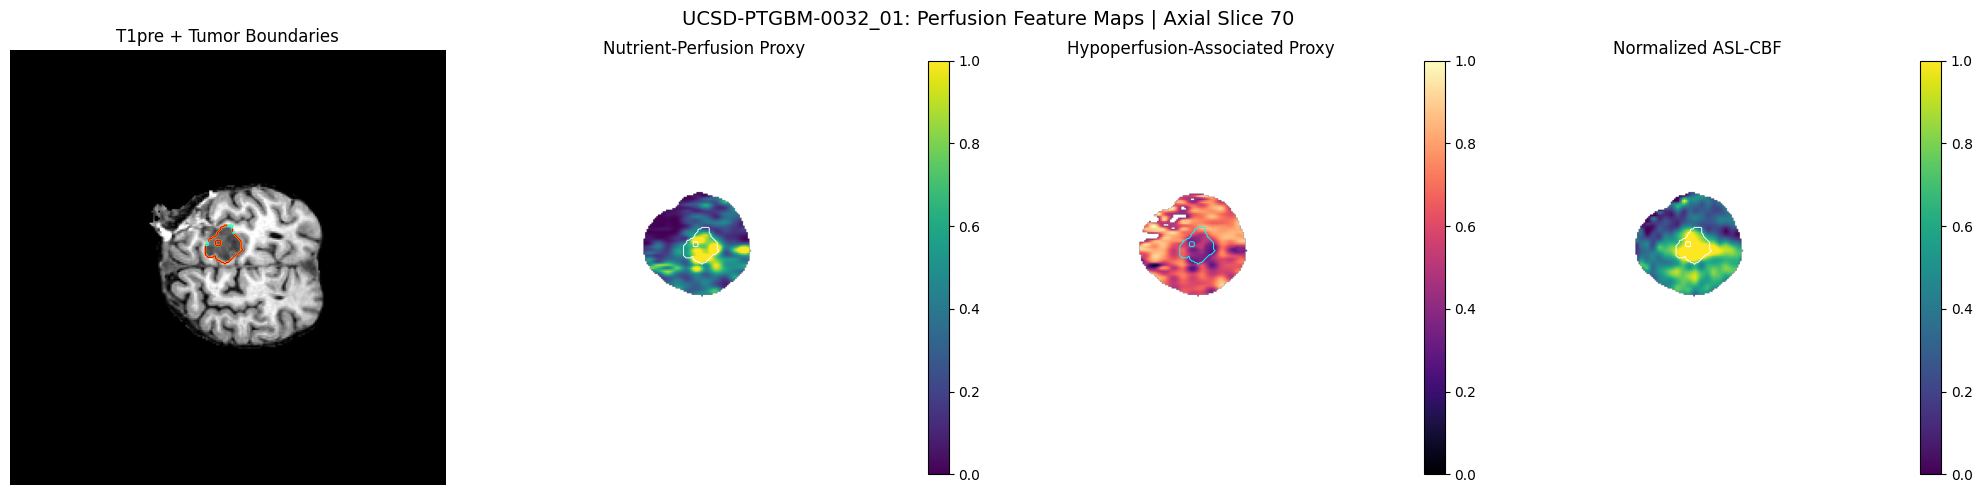

Visualization saved: /content/drive/MyDrive/UCSD-PTGBM/Sample_Visualizations/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_PerfusionFeature_Visualization.png


In [ ]:

# ============================================================
# PILOT: AXIAL FEATURE MAP VISUALIZATION
# ============================================================

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path

# Load saved feature maps
def load_saved_feature(suffix):
    path = OUTPUT_DIR / f"{SESSION_ID}_{suffix}.nii.gz"
    return nib.load(str(path)).get_fdata(dtype=np.float32)

nutrient_map = load_saved_feature("NutrientPerfusionProxy")
hypoperfusion_map = load_saved_feature("HypoperfusionProxy")
asl_map = load_saved_feature("ASL_CBF_Normalized")
hypoxia_valid_map = load_saved_feature(
    "Hypoperfusion_ValidityMask"
) > 0

# Reference anatomical image
t1 = reference_img.get_fdata(dtype=np.float32)

# Select slice with largest tumor cross-sectional area
tumor_area_by_slice = total_mask.sum(axis=(0, 1))
best_slice = int(np.argmax(tumor_area_by_slice))

print("Selected axial slice:", best_slice)
print("Tumor voxels on slice:", int(tumor_area_by_slice[best_slice]))

# Rotate images for conventional radiological-style display
def display_orientation(array):
    return np.rot90(array)

t1_slice = display_orientation(t1[:, :, best_slice])
tumor_slice = display_orientation(total_mask[:, :, best_slice])
enhancing_slice = display_orientation(
    enhancing_mask[:, :, best_slice]
)
nonenhancing_slice = display_orientation(
    nonenhancing_mask[:, :, best_slice]
)

nutrient_slice = display_orientation(
    np.where(
        total_mask[:, :, best_slice] |
        (region_masks["Peritumoral_0_5mm"][:, :, best_slice]) |
        (region_masks["Peritumoral_5_10mm"][:, :, best_slice]) |
        (region_masks["Peritumoral_10_20mm"][:, :, best_slice]),
        nutrient_map[:, :, best_slice],
        np.nan
    )
)

hypoperfusion_slice = display_orientation(
    np.where(
        hypoxia_valid_map[:, :, best_slice],
        hypoperfusion_map[:, :, best_slice],
        np.nan
    )
)

asl_slice = display_orientation(
    np.where(
        analysis_mask[:, :, best_slice],
        asl_map[:, :, best_slice],
        np.nan
    )
)

# T1 display window
t1_valid = t1_slice[np.isfinite(t1_slice) & (t1_slice != 0)]
vmin, vmax = np.percentile(t1_valid, [2, 98])

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Panel 1: Anatomy and tumor contours
axes[0].imshow(t1_slice, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].contour(
    tumor_slice.astype(float),
    levels=[0.5],
    colors=["yellow"],
    linewidths=1.2
)
axes[0].contour(
    enhancing_slice.astype(float),
    levels=[0.5],
    colors=["red"],
    linewidths=0.9
)
axes[0].contour(
    nonenhancing_slice.astype(float),
    levels=[0.5],
    colors=["cyan"],
    linewidths=0.9
)
axes[0].set_title("T1pre + Tumor Boundaries")
axes[0].axis("off")

# Panel 2: Nutrient-perfusion proxy
im1 = axes[1].imshow(
    nutrient_slice,
    cmap="viridis",
    vmin=0,
    vmax=1
)
axes[1].contour(
    tumor_slice.astype(float),
    levels=[0.5],
    colors=["white"],
    linewidths=0.7
)
axes[1].set_title("Nutrient-Perfusion Proxy")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# Panel 3: Hypoperfusion-associated proxy
im2 = axes[2].imshow(
    hypoperfusion_slice,
    cmap="magma",
    vmin=0,
    vmax=1
)
axes[2].contour(
    tumor_slice.astype(float),
    levels=[0.5],
    colors=["cyan"],
    linewidths=0.7
)
axes[2].set_title("Hypoperfusion-Associated Proxy")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

# Panel 4: Independent ASL-CBF map
im3 = axes[3].imshow(
    asl_slice,
    cmap="viridis",
    vmin=0,
    vmax=1
)
axes[3].contour(
    tumor_slice.astype(float),
    levels=[0.5],
    colors=["white"],
    linewidths=0.7
)
axes[3].set_title("Normalized ASL-CBF")
axes[3].axis("off")
plt.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

fig.suptitle(
    f"{SESSION_ID}: Perfusion Feature Maps | Axial Slice {best_slice}",
    fontsize=14
)

plt.tight_layout()

figure_path = (
    VISUALIZATION_DIR /
    f"{SESSION_ID}_PerfusionFeature_Visualization.png"
)

plt.savefig(figure_path, dpi=250, bbox_inches="tight")
plt.show()

print("Visualization saved:", figure_path)


All required variables found.
H_CBF100_MTT0: CBF=1.00, MTT=0.00
H_CBF75_MTT25: CBF=0.75, MTT=0.25
H_CBF50_MTT50: CBF=0.50, MTT=0.50
H_CBF25_MTT75: CBF=0.25, MTT=0.75
H_CBF0_MTT100: CBF=0.00, MTT=1.00

SPEARMAN CORRELATION BETWEEN H MODELS


,H_CBF100_MTT0,H_CBF75_MTT25,H_CBF50_MTT50,H_CBF25_MTT75,H_CBF0_MTT100
H_CBF100_MTT0,1.0000,0.9431,0.6988,0.3639,0.0458
H_CBF75_MTT25,0.9431,1.0000,0.8909,0.6301,0.3284
H_CBF50_MTT50,0.6988,0.8909,1.0000,0.9029,0.6787
H_CBF25_MTT75,0.3639,0.6301,0.9029,1.0000,0.9223
H_CBF0_MTT100,0.0458,0.3284,0.6787,0.9223,1.0000



N(x) CROSS-MODALITY VALIDATION
Spearman correlation: 0.6026
Pearson correlation: 0.577

REGIONAL H(x) SENSITIVITY


,Region,Voxel_Count,Valid_H_Voxels,H_Coverage_Percent,H_CBF100_MTT0_Median,H_CBF100_MTT0_Mean,H_CBF75_MTT25_Median,H_CBF75_MTT25_Mean,H_CBF50_MTT50_Median,H_CBF50_MTT50_Mean,H_CBF25_MTT75_Median,H_CBF25_MTT75_Mean,H_CBF0_MTT100_Median,H_CBF0_MTT100_Mean
0,Enhancing_Tumor,4417,4403,99.6830,0.3272,0.3317,0.4396,0.4366,0.5441,0.5415,0.6515,0.6463,0.7636,0.7512
1,NonEnhancing_Tumor,1862,1813,97.3684,0.7141,0.6813,0.7142,0.6949,0.7182,0.7086,0.7344,0.7223,0.7553,0.7360
2,Total_Tumor,6279,6216,98.9967,0.4595,0.4337,0.5409,0.5119,0.6102,0.5902,0.6780,0.6685,0.7607,0.7467
3,Peritumoral_0_5mm,21352,20905,97.9065,0.6985,0.6455,0.7018,0.6591,0.7012,0.6726,0.7135,0.6862,0.7299,0.6998
4,Peritumoral_5_10mm,34217,32983,96.3936,0.7362,0.6863,0.7210,0.6821,0.6990,0.6778,0.6972,0.6735,0.7019,0.6693
5,Peritumoral_10_20mm,100795,96858,96.0941,0.6942,0.6576,0.6822,0.6498,0.6552,0.6420,0.6473,0.6343,0.6450,0.6265


Saved: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_H_CBF100_MTT0.nii.gz
Saved: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_H_CBF75_MTT25.nii.gz
Saved: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_H_CBF50_MTT50.nii.gz
Saved: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_H_CBF25_MTT75.nii.gz
Saved: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_H_CBF0_MTT100.nii.gz

Saved correlation matrix: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_H_Model_Correlations.csv
Saved regional sensitivity: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_H_WeightSensitivity.csv


/tmp/ipykernel_768/1211216274.py:278: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


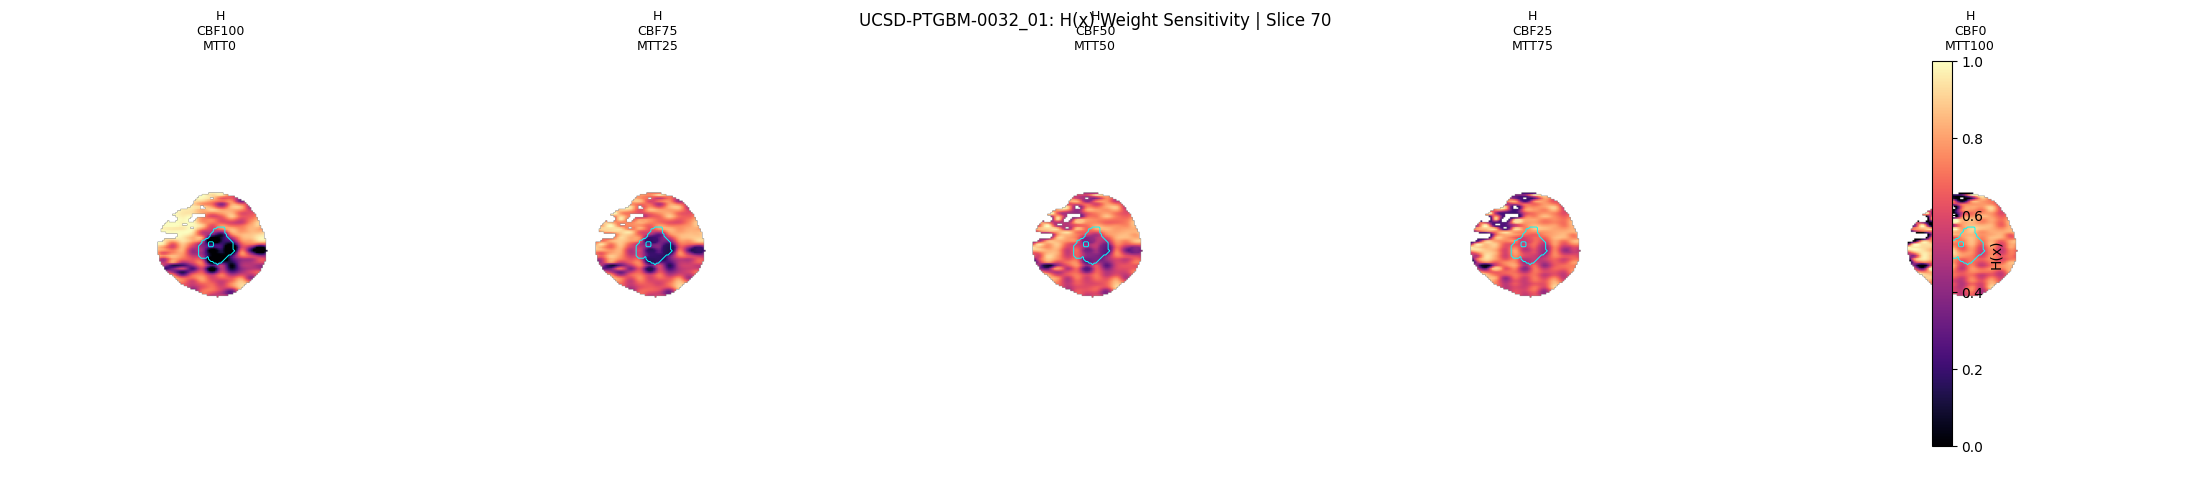


Sensitivity visualization saved: /content/drive/MyDrive/UCSD-PTGBM/Sample_Visualizations/UCSD-PTGBM-0032_01/UCSD-PTGBM-0032_01_H_WeightSensitivity.png

H(x) SENSITIVITY ANALYSIS COMPLETE


In [ ]:

# ============================================================
# PILOT VALIDATION 1: H(x) WEIGHT SENSITIVITY ANALYSIS
# Subject: UCSD-PTGBM-0032_01
# ============================================================

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, pearsonr
from pathlib import Path

# ------------------------------------------------------------
# 1. Verify required variables
# ------------------------------------------------------------

required_variables = [
    "cbf_norm",
    "asl_norm",
    "mtt_norm",
    "cbv_norm",
    "hypoxia_valid",
    "analysis_mask",
    "region_masks",
    "reference_img",
    "OUTPUT_DIR",
    "SESSION_ID"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. "
        "Rerun the feature extraction cell first."
    )

print("All required variables found.")

# ------------------------------------------------------------
# 2. Define alternative H(x) models
# ------------------------------------------------------------

# Weight represents the contribution of low CBF.
cbf_weights = [1.00, 0.75, 0.50, 0.25, 0.00]

H_maps = {}

low_cbf = 1.0 - cbf_norm

for weight in cbf_weights:

    mtt_weight = 1.0 - weight

    H = (
        weight * low_cbf
        + mtt_weight * mtt_norm
    ).astype(np.float32)

    # Restrict output to voxels with valid measurements
    H[~hypoxia_valid] = 0

    model_name = f"H_CBF{int(weight*100)}_MTT{int(mtt_weight*100)}"

    H_maps[model_name] = H

    print(
        f"{model_name}: "
        f"CBF={weight:.2f}, MTT={mtt_weight:.2f}"
    )

# ------------------------------------------------------------
# 3. Calculate correlations between H(x) models
# ------------------------------------------------------------

model_names = list(H_maps.keys())

correlation_matrix = pd.DataFrame(
    index=model_names,
    columns=model_names,
    dtype=float
)

common_valid = (
    hypoxia_valid
    & analysis_mask
)

for name_a in model_names:

    for name_b in model_names:

        a = H_maps[name_a][common_valid]
        b = H_maps[name_b][common_valid]

        if len(a) > 2:
            correlation_matrix.loc[name_a, name_b] = (
                spearmanr(a, b).statistic
            )

print("\nSPEARMAN CORRELATION BETWEEN H MODELS")
display(correlation_matrix.round(4))

# ------------------------------------------------------------
# 4. Compare CBF-based N(x) with independent ASL-CBF
# ------------------------------------------------------------

cbf_asl_valid = (
    analysis_mask
    & np.isfinite(cbf_norm)
    & np.isfinite(asl_norm)
    & (cbf_norm > 0)
    & (asl_norm > 0)
)

dsc_values = cbf_norm[cbf_asl_valid]
asl_values = asl_norm[cbf_asl_valid]

print("\nN(x) CROSS-MODALITY VALIDATION")

print(
    "Spearman correlation:",
    round(
        float(spearmanr(dsc_values, asl_values).statistic),
        4
    )
)

print(
    "Pearson correlation:",
    round(
        float(pearsonr(dsc_values, asl_values).statistic),
        4
    )
)

# ------------------------------------------------------------
# 5. Regional sensitivity analysis
# ------------------------------------------------------------

regional_rows = []

for region_name, region_mask in region_masks.items():

    valid = region_mask & hypoxia_valid

    row = {
        "Region": region_name,
        "Voxel_Count": int(region_mask.sum()),
        "Valid_H_Voxels": int(valid.sum()),
        "H_Coverage_Percent": (
            100 * valid.sum() / region_mask.sum()
        )
    }

    for model_name, H in H_maps.items():

        values = H[valid]

        row[f"{model_name}_Median"] = (
            float(np.median(values))
            if values.size else np.nan
        )

        row[f"{model_name}_Mean"] = (
            float(np.mean(values))
            if values.size else np.nan
        )

    regional_rows.append(row)

sensitivity_df = pd.DataFrame(regional_rows)

print("\nREGIONAL H(x) SENSITIVITY")
display(sensitivity_df.round(4))

# ------------------------------------------------------------
# 6. Save alternative H maps
# ------------------------------------------------------------

affine = reference_img.affine
header = reference_img.header.copy()

for model_name, H in H_maps.items():

    output_path = (
        OUTPUT_DIR /
        f"{SESSION_ID}_{model_name}.nii.gz"
    )

    img = nib.Nifti1Image(
        H.astype(np.float32),
        affine,
        header=header
    )

    img.set_data_dtype(np.float32)
    nib.save(img, str(output_path))

    print("Saved:", output_path)

# ------------------------------------------------------------
# 7. Save sensitivity results
# ------------------------------------------------------------

correlation_path = (
    OUTPUT_DIR /
    f"{SESSION_ID}_H_Model_Correlations.csv"
)

regional_path = (
    OUTPUT_DIR /
    f"{SESSION_ID}_H_WeightSensitivity.csv"
)

correlation_matrix.to_csv(correlation_path)
sensitivity_df.to_csv(regional_path, index=False)

print("\nSaved correlation matrix:", correlation_path)
print("Saved regional sensitivity:", regional_path)

# ------------------------------------------------------------
# 8. Visualize all five models on the same axial slice
# ------------------------------------------------------------

tumor_area = total_mask.sum(axis=(0, 1))
best_slice = int(np.argmax(tumor_area))

fig, axes = plt.subplots(1, 5, figsize=(22, 5))

for ax, (model_name, H) in zip(axes, H_maps.items()):

    display_map = np.rot90(
        np.where(
            hypoxia_valid[:, :, best_slice],
            H[:, :, best_slice],
            np.nan
        )
    )

    tumor_contour = np.rot90(
        total_mask[:, :, best_slice].astype(float)
    )

    im = ax.imshow(
        display_map,
        cmap="magma",
        vmin=0,
        vmax=1
    )

    ax.contour(
        tumor_contour,
        levels=[0.5],
        colors="cyan",
        linewidths=0.7
    )

    ax.set_title(model_name.replace("_", "\n"), fontsize=9)
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes,
    fraction=0.025,
    pad=0.02,
    label="H(x)"
)

fig.suptitle(
    f"{SESSION_ID}: H(x) Weight Sensitivity | Slice {best_slice}"
)

plt.tight_layout()

figure_path = (
    VISUALIZATION_DIR /
    f"{SESSION_ID}_H_WeightSensitivity.png"
)

plt.savefig(figure_path, dpi=250, bbox_inches="tight")
plt.show()

print("\nSensitivity visualization saved:", figure_path)

print("\nH(x) SENSITIVITY ANALYSIS COMPLETE")


Extract for multiple patients

Define extraction function

$
N(x)=\operatorname{RobustNormalize}(CBF(x))
$

$
H(x)=0.5[1-N(x)]+0.5M(x)
$

where $M(x)$ is the robustly normalized MTT map

In [ ]:

# ================================================================
# FULL-BRAIN N(x) AND H(x) EXTRACTION — PILOT-STYLE WORKFLOW
#
# Replicates the pilot's image-support-based perfusion calculation.
# NO tumor segmentation is loaded or required.
#
# N(x) = robust-normalized CBF_svd
# M(x) = robust-normalized log1p(MTT_svd)
# H(x) = 0.5 * (1 - N(x)) + 0.5 * M(x)
#
# Normalization domain:
#   finite, nonzero T1pre image support
#
# N validity:
#   finite positive CBF_svd within T1pre support
#
# H validity:
#   finite positive CBF_svd and MTT_svd within T1pre support
#
# Saves full-volume N, M, H maps and validity masks.
# ================================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

import os
import numpy as np
import pandas as pd
import nibabel as nib
from pathlib import Path

# ---------------- PATHS ----------------

MANIFEST = (
    "/content/drive/MyDrive/UCSD-PTGBM/"
    "Cohort_Features/patient_manifest.csv"
)

OUTPUT_ROOT = (
    "/content/drive/MyDrive/UCSD-PTGBM/"
    "Cohort_Features/N_H_PilotMethod_FullBrain"
)

MAP_DIR = os.path.join(OUTPUT_ROOT, "NIfTI_Maps")
QC_DIR = os.path.join(OUTPUT_ROOT, "QC")

os.makedirs(MAP_DIR, exist_ok=True)
os.makedirs(QC_DIR, exist_ok=True)

QC_PATH = os.path.join(QC_DIR, "FullBrain_N_H_QC.csv")

LOWER_PCT = 2.0
UPPER_PCT = 98.0

# ---------------- LOAD MANIFEST ----------------

df = pd.read_csv(MANIFEST)

required = ["session_id", "T1pre", "CBF_svd", "MTT_svd"]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing manifest columns: {missing}")

print("=" * 80)
print("FULL-BRAIN N(x) AND H(x) EXTRACTION")
print("=" * 80)
print("Sessions:", len(df))
print("Manifest:", MANIFEST)
print("Output:", OUTPUT_ROOT)
print("Normalization: per-session 2nd–98th percentile")
print("Spatial domain: full nonzero finite T1pre support")
print("Tumor segmentation: NOT USED")
print("=" * 80)


def get_path(value):
    if pd.isna(value):
        return None
    value = str(value).strip()
    if value.lower() in ("", "nan", "none", "null"):
        return None
    return value


def robust_normalize(data, valid_mask):
    """
    Robustly normalize valid voxels using the 2nd and 98th
    percentiles. Invalid voxels remain zero.
    """
    out = np.zeros(data.shape, dtype=np.float32)

    values = data[valid_mask].astype(np.float64)

    if values.size == 0:
        raise ValueError("No valid voxels for normalization.")

    lo, hi = np.percentile(
        values,
        [LOWER_PCT, UPPER_PCT]
    )

    if not np.isfinite(lo) or not np.isfinite(hi):
        raise ValueError("Non-finite normalization bounds.")

    if hi <= lo:
        raise ValueError(
            f"Invalid normalization range: lower={lo}, upper={hi}"
        )

    out[valid_mask] = np.clip(
        (data[valid_mask] - lo) / (hi - lo),
        0.0,
        1.0
    ).astype(np.float32)

    return out, float(lo), float(hi)


def save_nifti(data, reference, path):
    header = reference.header.copy()
    header.set_data_dtype(np.float32)

    out = nib.Nifti1Image(
        np.asarray(data, dtype=np.float32),
        reference.affine,
        header
    )

    nib.save(out, path)


# ---------------- PROCESS ALL SESSIONS ----------------

records = []

for i, row in df.iterrows():

    sid = str(row["session_id"])

    print(f"\n[{i + 1}/{len(df)}] {sid}")

    record = {
        "session_id": sid,
        "status": "NOT_STARTED",
        "T1pre_support_voxels": 0,
        "CBF_valid_voxels": 0,
        "MTT_valid_voxels": 0,
        "N_valid_voxels": 0,
        "H_valid_voxels": 0,
        "CBF_lower": np.nan,
        "CBF_upper": np.nan,
        "logMTT_lower": np.nan,
        "logMTT_upper": np.nan,
        "error": ""
    }

    try:
        t1_path = get_path(row["T1pre"])
        cbf_path = get_path(row["CBF_svd"])
        mtt_path = get_path(row["MTT_svd"])

        for label, path in [
            ("T1pre", t1_path),
            ("CBF_svd", cbf_path),
            ("MTT_svd", mtt_path)
        ]:
            if path is None or not os.path.isfile(path):
                raise FileNotFoundError(
                    f"{label} missing: {path}"
                )

        # Load reference anatomy and perfusion maps.
        t1_img = nib.load(t1_path)
        cbf_img = nib.load(cbf_path)
        mtt_img = nib.load(mtt_path)

        t1 = np.asarray(t1_img.dataobj, dtype=np.float32)
        cbf = np.asarray(cbf_img.dataobj, dtype=np.float32)
        mtt = np.asarray(mtt_img.dataobj, dtype=np.float32)

        # Validate 3D dimensions.
        if t1.ndim != 3 or cbf.ndim != 3 or mtt.ndim != 3:
            raise ValueError("One or more input images are not 3D.")

        # Validate image grids.
        for name, img, data in [
            ("CBF_svd", cbf_img, cbf),
            ("MTT_svd", mtt_img, mtt)
        ]:
            if data.shape != t1.shape:
                raise ValueError(
                    f"{name} shape {data.shape} != T1pre shape {t1.shape}"
                )

            if not np.allclose(
                img.affine,
                t1_img.affine,
                rtol=1e-5,
                atol=1e-4
            ):
                raise ValueError(
                    f"{name} affine does not match T1pre."
                )

        # FULL IMAGE SUPPORT — no tumor segmentation.
        image_support = np.isfinite(t1) & (t1 != 0)

        # Perfusion-specific validity.
        cbf_valid = (
            image_support
            & np.isfinite(cbf)
            & (cbf > 0)
        )

        mtt_valid = (
            image_support
            & np.isfinite(mtt)
            & (mtt > 0)
        )

        # N(x): normalized CBF.
        N, cbf_lo, cbf_hi = robust_normalize(
            cbf,
            cbf_valid
        )

        # M(x): normalized log-transformed MTT.
        log_mtt = np.zeros(mtt.shape, dtype=np.float32)
        log_mtt[mtt_valid] = np.log1p(mtt[mtt_valid])

        M, mtt_lo, mtt_hi = robust_normalize(
            log_mtt,
            mtt_valid
        )

        # H(x): combined hypoperfusion proxy.
        h_valid = cbf_valid & mtt_valid

        H = np.zeros(t1.shape, dtype=np.float32)

        H[h_valid] = (
            0.5 * (1.0 - N[h_valid])
            + 0.5 * M[h_valid]
        )

        # Enforce exact zero outside the corresponding validity masks.
        N[~cbf_valid] = 0
        M[~mtt_valid] = 0
        H[~h_valid] = 0

        # Save full-volume maps.
        session_dir = os.path.join(MAP_DIR, sid)
        os.makedirs(session_dir, exist_ok=True)

        save_nifti(
            N,
            t1_img,
            os.path.join(session_dir, f"{sid}_N_x.nii.gz")
        )

        save_nifti(
            M,
            t1_img,
            os.path.join(session_dir, f"{sid}_M_x.nii.gz")
        )

        save_nifti(
            H,
            t1_img,
            os.path.join(session_dir, f"{sid}_H_x.nii.gz")
        )

        # Save validity masks as float32 for consistent handling.
        save_nifti(
            cbf_valid.astype(np.float32),
            t1_img,
            os.path.join(session_dir, f"{sid}_N_ValidityMask.nii.gz")
        )

        save_nifti(
            mtt_valid.astype(np.float32),
            t1_img,
            os.path.join(session_dir, f"{sid}_M_ValidityMask.nii.gz")
        )

        save_nifti(
            h_valid.astype(np.float32),
            t1_img,
            os.path.join(session_dir, f"{sid}_H_ValidityMask.nii.gz")
        )

        # QC.
        record.update({
            "status": "SUCCESS",
            "T1pre_support_voxels": int(image_support.sum()),
            "CBF_valid_voxels": int(cbf_valid.sum()),
            "MTT_valid_voxels": int(mtt_valid.sum()),
            "N_valid_voxels": int(cbf_valid.sum()),
            "H_valid_voxels": int(h_valid.sum()),
            "CBF_lower": cbf_lo,
            "CBF_upper": cbf_hi,
            "logMTT_lower": mtt_lo,
            "logMTT_upper": mtt_hi,
        })

        print("  T1pre support:", f"{image_support.sum():,}")
        print("  N valid voxels:", f"{cbf_valid.sum():,}")
        print("  H valid voxels:", f"{h_valid.sum():,}")
        print("  N range:", float(N[cbf_valid].min()),
              float(N[cbf_valid].max()))
        print("  H range:", float(H[h_valid].min()),
              float(H[h_valid].max()))
        print("  SUCCESS — full-volume maps saved")

    except Exception as e:
        record["status"] = "FAILED"
        record["error"] = repr(e)
        print("  FAILED:", repr(e))

    records.append(record)

    # Save QC incrementally.
    pd.DataFrame(records).to_csv(QC_PATH, index=False)


# ---------------- FINAL REPORT ----------------

qc = pd.DataFrame(records)
qc.to_csv(QC_PATH, index=False)

print("\n" + "=" * 80)
print("EXTRACTION COMPLETE")
print("=" * 80)
print("Total sessions:", len(qc))
print("Successful:", int((qc["status"] == "SUCCESS").sum()))
print("Failed:", int((qc["status"] != "SUCCESS").sum()))
print("Tumor segmentation used: NO")
print("Maps saved:", MAP_DIR)
print("QC saved:", QC_PATH)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.width", 220
):
    display(qc)

print("\nOutput files per successful session:")
print("  *_N_x.nii.gz")
print("  *_M_x.nii.gz")
print("  *_H_x.nii.gz")
print("  *_N_ValidityMask.nii.gz")
print("  *_M_ValidityMask.nii.gz")
print("  *_H_ValidityMask.nii.gz")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
FULL-BRAIN N(x) AND H(x) EXTRACTION
Sessions: 184
Manifest: /content/drive/MyDrive/UCSD-PTGBM/Cohort_Features/patient_manifest.csv
Output: /content/drive/MyDrive/UCSD-PTGBM/Cohort_Features/N_H_PilotMethod_FullBrain
Normalization: per-session 2nd–98th percentile
Spatial domain: full nonzero finite T1pre support
Tumor segmentation: NOT USED

[1/184] UCSD-PTGBM-0002_01
  T1pre support: 1,591,800
  N valid voxels: 1,477,347
  H valid voxels: 1,435,963
  N range: 0.0 1.0
  H range: 0.0 1.0
  SUCCESS — full-volume maps saved

[2/184] UCSD-PTGBM-0005_01
  T1pre support: 1,490,787
  N valid voxels: 1,433,583
  H valid voxels: 1,364,971
  N range: 0.0 1.0
  H range: 0.0 1.0
  SUCCESS — full-volume maps saved

[3/184] UCSD-PTGBM-0005_02
  T1pre support: 1,486,073
  N valid voxels: 1,398,229
  H valid voxels: 1,337,565
  N range: 0.0 1.0
  H range: 0.0 1.0
  SUCCESS — f

,session_id,status,T1pre_support_voxels,CBF_valid_voxels,MTT_valid_voxels,N_valid_voxels,H_valid_voxels,CBF_lower,CBF_upper,logMTT_lower,logMTT_upper,error
0,UCSD-PTGBM-0002_01,SUCCESS,1591800,1477347,1445396,1477347,1435963,0.003580,0.159072,0.219210,1.821257,
1,UCSD-PTGBM-0005_01,SUCCESS,1490787,1433583,1369394,1433583,1364971,0.012018,0.417775,0.384697,1.587629,
2,UCSD-PTGBM-0005_02,SUCCESS,1486073,1398229,1347271,1398229,1337565,0.003669,0.170213,0.280798,1.895214,
3,UCSD-PTGBM-0006_01,SUCCESS,1423676,1343112,1316718,1343112,1306006,0.005106,0.224808,0.243877,1.705993,
4,UCSD-PTGBM-0007_01,SUCCESS,1484390,1427203,1348400,1427203,1341661,0.004027,0.160325,0.366514,1.736977,
5,UCSD-PTGBM-0007_02,SUCCESS,1463439,1369849,1325353,1369849,1317957,0.003744,0.229864,0.289023,1.842666,
6,UCSD-PTGBM-0008_01,SUCCESS,1678198,1599475,1547906,1599475,1544880,0.005835,0.154600,0.610850,1.923620,
7,UCSD-PTGBM-0008_02,SUCCESS,1648195,1580969,1533964,1580969,1531975,0.007899,0.155523,0.866494,2.443880,
8,UCSD-PTGBM-0008_03,SUCCESS,1695148,1607897,1558753,1607897,1552062,0.002535,0.105535,0.547117,1.971725,
9,UCSD-PTGBM-0009_01,SUCCESS,1824638,1701621,1617891,1701621,1607490,0.005061,0.211279,0.425346,2.177557,



Output files per successful session:
  *_N_x.nii.gz
  *_M_x.nii.gz
  *_H_x.nii.gz
  *_N_ValidityMask.nii.gz
  *_M_ValidityMask.nii.gz
  *_H_ValidityMask.nii.gz


Hypoxia and Nutrient-Driven Proliferation --> done

-------

## ECM Density and Degredation Extraction

$
Q_{\mathrm{ECM}}^{\mathrm{proxy}}(x,t)
=\frac{\mathrm{RSI}_{H}(x,t)}
{\mathrm{RSI}_{H}(x,t)+\mathrm{RSI}_{F}(x,t)+\epsilon}
$

LOADED RSI_Hindered: p1=0, p99=4.4464
LOADED RSI_Free: p1=0, p99=5.6933


,Modality,Shape,Finite_Voxels,Nonzero_Voxels,Tumor_Coverage_Percent,Tumor_Median
0,RSI_Hindered,"(256, 256, 256)",16777216,1434935,100.0,2.909657
1,RSI_Free,"(256, 256, 256)",16777216,1419315,100.0,1.003497



RSI hindered fraction coverage: 89.38 %
Valid voxels: 1,387,097
Median Q_ECM: 0.7090776562690735
SAVED: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0021_01/ECM_Pilot/NIfTI_Maps/UCSD-PTGBM-0021_01_RSI_Hindered_Fraction.nii.gz
SAVED: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0021_01/ECM_Pilot/NIfTI_Maps/UCSD-PTGBM-0021_01_RSI_Hindered_Fraction_Valid.nii.gz

REGIONAL Q_ECM SUMMARY


,Session,Region,Voxel_Count,Valid_Voxels,Coverage_Percent,Mean,Median,Std,P10,P90
0,UCSD-PTGBM-0021_01,Tumor,71367,71354,99.9818,0.7169,0.7367,0.1202,0.5708,0.8275
1,UCSD-PTGBM-0021_01,Peritumoral_0_5mm,103532,102120,98.6362,0.6845,0.7264,0.1600,0.4337,0.8373
2,UCSD-PTGBM-0021_01,Peritumoral_5_10mm,113460,108159,95.3279,0.6330,0.7011,0.1967,0.3256,0.8330
3,UCSD-PTGBM-0021_01,Peritumoral_10_20mm,213059,194553,91.3141,0.6303,0.7030,0.2087,0.3084,0.8403


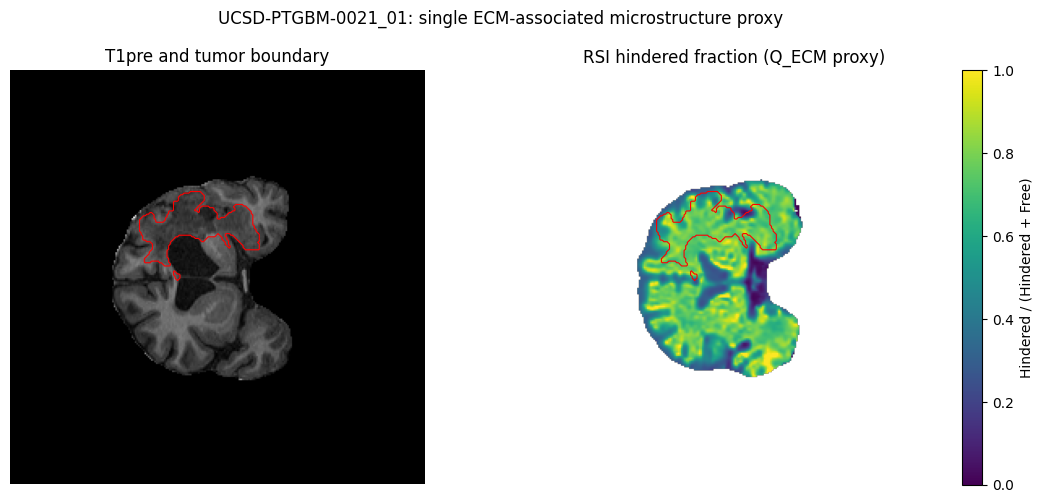

SAVED: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0021_01/ECM_Pilot/QC/Q_ECM_SingleProxy_QC.png

SINGLE ECM-ASSOCIATED PROXY PILOT COMPLETE
Session: UCSD-PTGBM-0021_01
Proxy: RSI hindered fraction
Output directory: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0021_01/ECM_Pilot
NIfTI proxy: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0021_01/ECM_Pilot/NIfTI_Maps/UCSD-PTGBM-0021_01_RSI_Hindered_Fraction.nii.gz
Validity mask: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0021_01/ECM_Pilot/NIfTI_Maps/UCSD-PTGBM-0021_01_RSI_Hindered_Fraction_Valid.nii.gz
Regional summary: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0021_01/ECM_Pilot/Q_ECM_Regional_Summary.csv
QC figure: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0021_01/ECM_Pilot/QC/Q_ECM_SingleProxy_QC.png
Metadata: /content/drive/MyDrive/UCSD-PTGBM/Sample_Features/UCSD-PTGBM-0021_01/ECM_Pilot/Q_ECM_Pilot_Metadata.json

No FA map was needed

In [ ]:

# ============================================================
# SINGLE ECM-ASSOCIATED MICROSTRUCTURE PROXY PILOT
# Subject: UCSD-PTGBM-0032_01
#
# Sole candidate:
#   Q_ECM = RSI_Hindered / (RSI_Hindered + RSI_Free)
#
# This is a scalar hindered/free water-compartment fraction.
# It is distinct in meaning from DTI anisotropy:
#   - Q_ECM: relative RSI water-compartment contribution
#   - FA: directional diffusion anisotropy magnitude
#   - V1: principal diffusion direction
#
# No FA map is required or assumed.
# No ADC, T2, FLAIR, or composite ECM scores are generated.
#
# Outputs:
#   1. Q_ECM 3D NIfTI map
#   2. Q_ECM validity-mask NIfTI
#   3. Regional summary CSV
#   4. Modality QC CSV
#   5. QC visualization
#   6. Metadata JSON
#
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import json

from scipy.ndimage import distance_transform_edt

# ------------------------------------------------------------
# 1. REQUIRE EXISTING PILOT INITIALIZATION
# ------------------------------------------------------------

required = [
    "SESSION_ID",
    "SESSION_DIR",
    "reference_img",
    "t1pre",
    "total_mask",
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        f"Run the existing pilot initialization cell first. "
        f"Missing: {missing}"
    )

SESSION_ID = str(SESSION_ID)

SESSION_DIR = Path(SESSION_DIR)

ECM_OUTPUT = (
    Path("/content/drive/MyDrive/UCSD-PTGBM")
    / "Sample_Features"
    / SESSION_ID
    / "ECM_Pilot"
)

ECM_QC = ECM_OUTPUT / "QC"
ECM_MAPS = ECM_OUTPUT / "NIfTI_Maps"

for p in [ECM_OUTPUT, ECM_QC, ECM_MAPS]:
    p.mkdir(parents=True, exist_ok=True)

reference_shape = reference_img.shape[:3]
reference_affine = reference_img.affine
spacing = nib.affines.voxel_sizes(reference_affine)[:3]

# ------------------------------------------------------------
# 2. BUILD TUMOR AND PERITUMORAL REGIONS
# ------------------------------------------------------------

tumor = np.asarray(total_mask, dtype=bool)
t1pre_array = np.asarray(t1pre, dtype=np.float32)

if tumor.shape != reference_shape:
    raise ValueError("Tumor mask does not match T1pre geometry.")

if t1pre_array.shape != reference_shape:
    raise ValueError("T1pre does not match reference geometry.")

image_support = (
    np.isfinite(t1pre_array)
    & (t1pre_array != 0)
)

# Restrict tumor to valid T1pre support.
tumor = tumor & image_support

if not tumor.any():
    raise RuntimeError(
        "Tumor mask has no overlap with T1pre image support."
    )

distance = distance_transform_edt(
    ~tumor,
    sampling=spacing
)

regions = {
    "Tumor": tumor,

    "Peritumoral_0_5mm": (
        (distance > 0)
        & (distance <= 5)
        & image_support
    ),

    "Peritumoral_5_10mm": (
        (distance > 5)
        & (distance <= 10)
        & image_support
    ),

    "Peritumoral_10_20mm": (
        (distance > 10)
        & (distance <= 20)
        & image_support
    ),
}

# ------------------------------------------------------------
# 3. LOAD RSI HINDERED AND RSI FREE
# ------------------------------------------------------------

# Retain the exact filename convention from your original code.
# These are the only two modalities needed for the selected proxy.

TOKENS = [
    "RSI_Hindered",
    "RSI_Free",
]

images = {}
modality_qc = {}
image_paths = {}

for token in TOKENS:

    path = (
        SESSION_DIR
        / f"{SESSION_ID}_{token}.nii.gz"
    )

    if not path.exists():
        raise FileNotFoundError(
            f"Required modality not found: {path}"
        )

    img = nib.load(str(path))
    data = img.get_fdata(dtype=np.float32)

    if data.ndim != 3:
        raise ValueError(
            f"{token} is not 3D: {data.shape}"
        )

    geometry_match = (
        data.shape == reference_shape
        and np.allclose(
            img.affine,
            reference_affine,
            atol=1e-4
        )
    )

    if not geometry_match:
        raise ValueError(
            f"{token} does not match reference image geometry."
        )

    images[token] = data
    image_paths[token] = str(path)

    finite = np.isfinite(data)
    nonzero = finite & (data != 0)

    modality_qc[token] = {
        "Modality": token,
        "Shape": str(data.shape),
        "Finite_Voxels": int(finite.sum()),
        "Nonzero_Voxels": int(nonzero.sum()),
        "Tumor_Coverage_Percent": (
            100 * (finite & tumor).sum() / tumor.sum()
            if tumor.sum() else np.nan
        ),
        "Tumor_Median": (
            float(np.median(data[finite & tumor]))
            if (finite & tumor).any()
            else np.nan
        ),
    }

    print(
        f"LOADED {token}: "
        f"p1={np.nanpercentile(data, 1):.5g}, "
        f"p99={np.nanpercentile(data, 99):.5g}"
    )

qc_df = pd.DataFrame(
    list(modality_qc.values())
)

display(qc_df)

# ------------------------------------------------------------
# 4. CALCULATE THE SINGLE ECM-ASSOCIATED PROXY
# ------------------------------------------------------------

hindered = images["RSI_Hindered"]
free = images["RSI_Free"]

denominator = hindered + free

valid = (
    image_support
    & np.isfinite(hindered)
    & np.isfinite(free)
    & (hindered >= 0)
    & (free >= 0)
    & np.isfinite(denominator)
    & (denominator > 1e-8)
)

hindered_fraction = np.full(
    reference_shape,
    np.nan,
    dtype=np.float32
)

hindered_fraction[valid] = (
    hindered[valid]
    / (hindered[valid] + free[valid] + 1e-8)
)

# The ratio is naturally bounded between 0 and 1.
hindered_fraction[valid] = np.clip(
    hindered_fraction[valid],
    0.0,
    1.0
)

features = {
    "RSI_Hindered_Fraction": hindered_fraction,
}

feature_validity = {
    "RSI_Hindered_Fraction": valid,
}

print(
    "\nRSI hindered fraction coverage:",
    round(
        100 * valid.sum() / image_support.sum(),
        2
    ),
    "%"
)

print(
    "Valid voxels:",
    f"{valid.sum():,}"
)

print(
    "Median Q_ECM:",
    float(np.nanmedian(hindered_fraction))
)

# ------------------------------------------------------------
# 5. SAVE THE SINGLE PROXY MAP AND VALIDITY MASK
# ------------------------------------------------------------

header = reference_img.header.copy()

proxy_path = (
    ECM_MAPS
    / f"{SESSION_ID}_RSI_Hindered_Fraction.nii.gz"
)

proxy_data = np.nan_to_num(
    hindered_fraction,
    nan=0.0
).astype(np.float32)

proxy_img = nib.Nifti1Image(
    proxy_data,
    reference_affine,
    header=header
)

proxy_img.set_data_dtype(np.float32)

nib.save(
    proxy_img,
    str(proxy_path)
)

valid_path = (
    ECM_MAPS
    / f"{SESSION_ID}_RSI_Hindered_Fraction_Valid.nii.gz"
)

valid_img = nib.Nifti1Image(
    valid.astype(np.uint8),
    reference_affine
)

valid_img.set_data_dtype(np.uint8)

nib.save(
    valid_img,
    str(valid_path)
)

print("SAVED:", proxy_path)
print("SAVED:", valid_path)

# ------------------------------------------------------------
# 6. REGIONAL FEATURE EXTRACTION
# ------------------------------------------------------------

rows = []

for region_name, region_mask in regions.items():

    selected = (
        region_mask
        & valid
        & np.isfinite(hindered_fraction)
    )

    values = hindered_fraction[selected]

    rows.append({
        "Session": SESSION_ID,
        "Region": region_name,
        "Voxel_Count": int(region_mask.sum()),
        "Valid_Voxels": int(values.size),

        "Coverage_Percent": (
            100 * values.size / region_mask.sum()
            if region_mask.sum()
            else np.nan
        ),

        "Mean": (
            float(np.mean(values))
            if values.size else np.nan
        ),

        "Median": (
            float(np.median(values))
            if values.size else np.nan
        ),

        "Std": (
            float(np.std(values))
            if values.size else np.nan
        ),

        "P10": (
            float(np.percentile(values, 10))
            if values.size else np.nan
        ),

        "P90": (
            float(np.percentile(values, 90))
            if values.size else np.nan
        ),
    })

regional_df = pd.DataFrame(rows)

regional_path = (
    ECM_OUTPUT
    / "Q_ECM_Regional_Summary.csv"
)

regional_df.to_csv(
    regional_path,
    index=False
)

print("\nREGIONAL Q_ECM SUMMARY")
display(regional_df.round(4))

# ------------------------------------------------------------
# 7. VISUALIZE THE SINGLE PROXY
# ------------------------------------------------------------

tumor_area = tumor.sum(axis=(0, 1))
best_slice = int(np.argmax(tumor_area))

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 5)
)

# T1pre reference with tumor boundary.
axes[0].imshow(
    np.rot90(t1pre_array[:, :, best_slice]),
    cmap="gray"
)

axes[0].contour(
    np.rot90(tumor[:, :, best_slice].astype(float)),
    levels=[0.5],
    colors="red",
    linewidths=0.8
)

axes[0].set_title("T1pre and tumor boundary")
axes[0].axis("off")

# Sole ECM-associated proxy.
q_slice = hindered_fraction[:, :, best_slice].copy()

q_slice[
    ~valid[:, :, best_slice]
] = np.nan

im = axes[1].imshow(
    np.rot90(q_slice),
    cmap="viridis",
    vmin=0,
    vmax=1
)

axes[1].contour(
    np.rot90(tumor[:, :, best_slice].astype(float)),
    levels=[0.5],
    colors="red",
    linewidths=0.8
)

axes[1].set_title(
    "RSI hindered fraction (Q_ECM proxy)"
)

axes[1].axis("off")

fig.colorbar(
    im,
    ax=axes[1],
    fraction=0.046,
    pad=0.04,
    label="Hindered / (Hindered + Free)"
)

plt.suptitle(
    f"{SESSION_ID}: single ECM-associated microstructure proxy"
)

plt.tight_layout()

figure_path = (
    ECM_QC
    / "Q_ECM_SingleProxy_QC.png"
)

plt.savefig(
    figure_path,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("SAVED:", figure_path)

# ------------------------------------------------------------
# 8. SAVE MODALITY QC AND METADATA
# ------------------------------------------------------------

qc_path = ECM_QC / "ECM_Modality_QC.csv"

qc_df.to_csv(
    qc_path,
    index=False
)

metadata = {
    "session": SESSION_ID,

    "selected_proxy": "RSI_Hindered_Fraction",

    "formula": (
        "RSI_Hindered / (RSI_Hindered + RSI_Free)"
    ),

    "interpretation": (
        "Scalar relative contribution of the RSI hindered "
        "water compartment. Used as an exploratory "
        "ECM-associated tissue microstructure proxy."
    ),

    "distinction_from_anisotropy": (
        "This scalar compartment fraction is conceptually "
        "different from DTI anisotropy, which describes "
        "directional diffusion. No FA map is required for "
        "calculation of this proxy."
    ),

    "not_a_direct_measurement_of": [
        "ECM concentration",
        "Collagen concentration",
        "Hyaluronan concentration",
        "Enzymatic ECM degradation",
    ],

    "reference_image": "T1pre",

    "support_definition": (
        "Finite, nonzero T1pre signal support. This is not "
        "a definitive brain mask."
    ),

    "normalization": (
        "No additional min-max normalization. The ratio "
        "is naturally bounded between zero and one."
    ),

    "valid_voxels": int(valid.sum()),

    "support_voxels": int(image_support.sum()),

    "valid_support_coverage_percent": float(
        100 * valid.sum() / image_support.sum()
    ),

    "voxel_spacing_mm": [
        float(x) for x in spacing
    ],

    "input_files": image_paths,

    "output_proxy": str(proxy_path),

    "output_validity_mask": str(valid_path),

    "regional_summary": str(regional_path),

    "warnings": [
        "RSI hindered fraction is not ECM-specific.",
        "Cellularity, membranes, edema, and other tissue "
        "properties may affect the signal.",
        "A single scan cannot estimate an ECM degradation rate.",
        "The proxy should be validated before biological "
        "interpretation as an ECM measurement."
    ],
}

metadata_path = (
    ECM_OUTPUT
    / "Q_ECM_Pilot_Metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

# ------------------------------------------------------------
# 9. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SINGLE ECM-ASSOCIATED PROXY PILOT COMPLETE")
print("=" * 60)

print("Session:", SESSION_ID)
print("Proxy: RSI hindered fraction")
print("Output directory:", ECM_OUTPUT)
print("NIfTI proxy:", proxy_path)
print("Validity mask:", valid_path)
print("Regional summary:", regional_path)
print("QC figure:", figure_path)
print("Metadata:", metadata_path)
print("\nNo FA map was needed.")
print("No ADC/T2/FLAIR composites were generated.")


Extract for all patients

Manifest sessions: 184
Package root exists: True
Indexing cohort NIfTI files...
Indexed NIfTI files: 4047

[1/184] Processing UCSD-PTGBM-0002_01
Status: success | Valid voxels: 1589920 | Regional analysis: False | Proxy extracted; no usable cellular tumor mask.

[2/184] Processing UCSD-PTGBM-0005_01
Status: success | Valid voxels: 1488755 | Regional analysis: True | Proxy extracted.

[3/184] Processing UCSD-PTGBM-0005_02
Status: success | Valid voxels: 1484371 | Regional analysis: False | Proxy extracted; no usable cellular tumor mask.

[4/184] Processing UCSD-PTGBM-0006_01
Status: success | Valid voxels: 1421600 | Regional analysis: True | Proxy extracted.

[5/184] Processing UCSD-PTGBM-0007_01
Status: success | Valid voxels: 1481195 | Regional analysis: True | Proxy extracted.

[6/184] Processing UCSD-PTGBM-0007_02
Status: success | Valid voxels: 1460631 | Regional analysis: True | Proxy extracted.

[7/184] Processing UCSD-PTGBM-0008_01
Status: success | Valid voxels: 1676627 | Regio

,Region,Sessions,Median_of_Session_Medians,Mean_of_Session_Medians,SD_of_Session_Medians,P10,P90
0,Tumor,142,0.6589,0.6644,0.0693,0.5736,0.7634
1,Peritumoral_0_5mm,142,0.6270,0.6251,0.0712,0.5422,0.7136
2,Peritumoral_5_10mm,142,0.6474,0.6384,0.0728,0.5492,0.7197
3,Peritumoral_10_20mm,142,0.6675,0.6607,0.0657,0.5936,0.7350


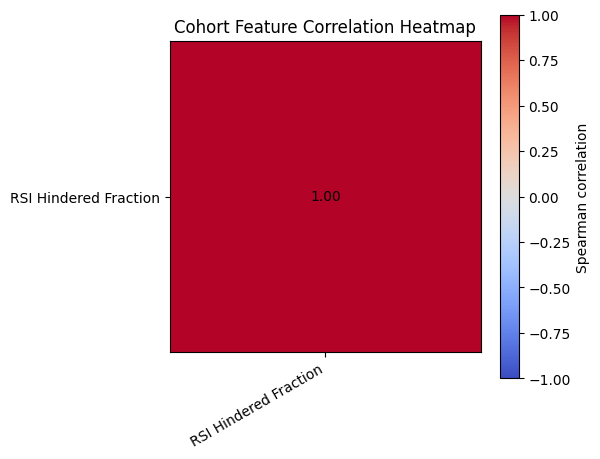

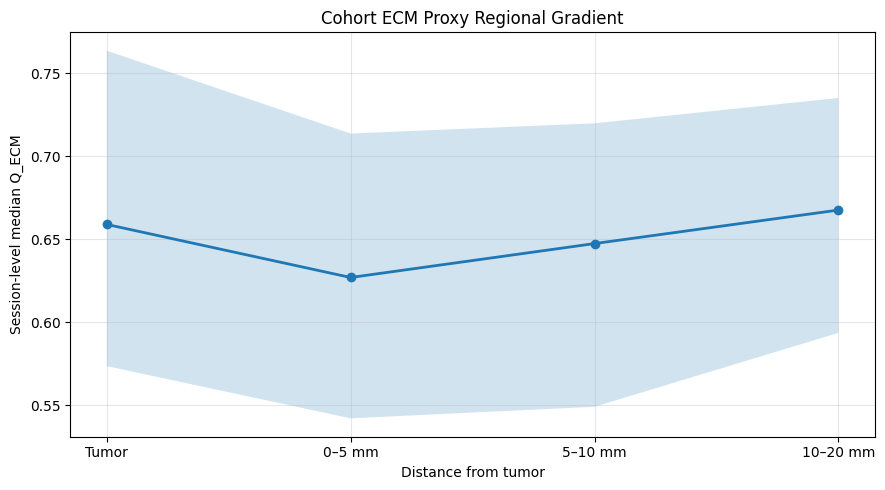

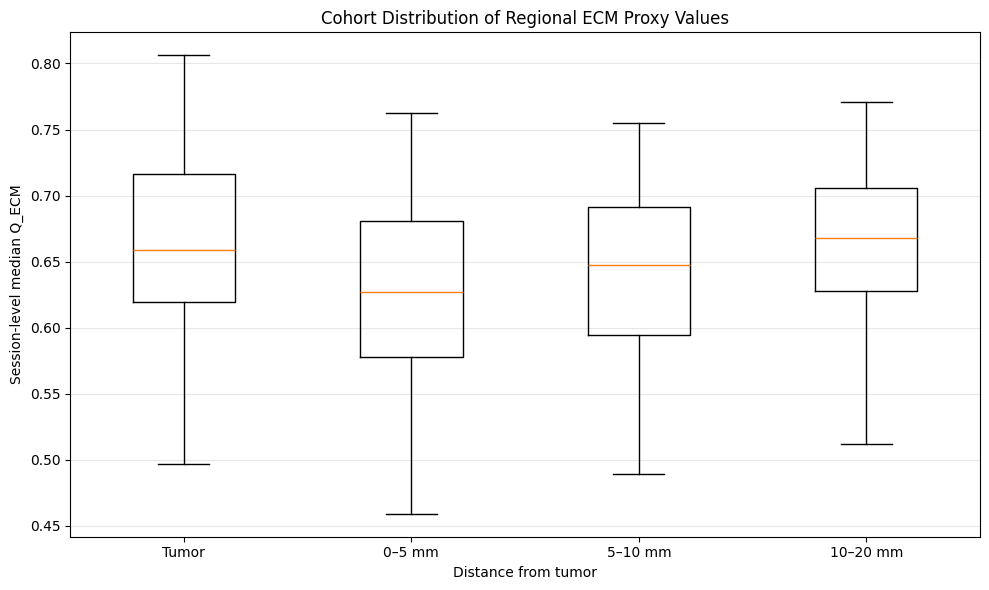

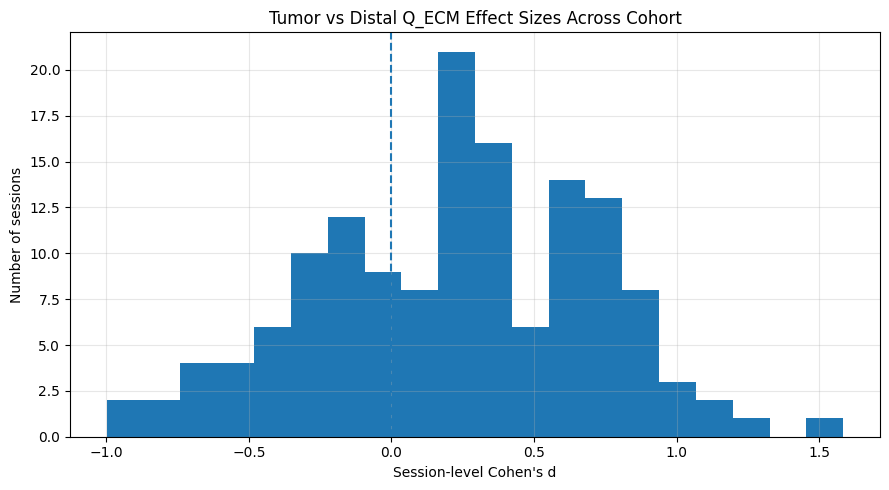


COHORT EXTRACTION COMPLETE
Output directory: /content/drive/MyDrive/UCSD-PTGBM/Cohort_Features/ECM_Cohort

Files:
 - Cohort_Regional_Distributions.png
 - Cohort_Regional_Gradient.png
 - Cohort_Tumor_vs_Distal_Effect_Sizes.png
 - ECM_Cohort_QC.csv
 - ECM_Cohort_Regional_Distributions.csv
 - ECM_Cohort_Regional_Summary.csv
 - ECM_Cohort_Tumor_vs_Distal_Effects.csv
 - Feature_Correlation_Heatmap.png
 - Feature_Correlations.csv


In [ ]:

# ============================================================
# FULL COHORT ECM PROXY EXTRACTION + VALIDATION
#
# Cohort: UCSD-PTGBM patient_manifest.csv
# Proxy: RSI_Hindered / (RSI_Hindered + RSI_Free)
#
# Outputs per session:
#   - Q_ECM NIfTI map
#   - Q_ECM validity NIfTI mask
#   - Regional statistics CSV
#   - Session QC record
#
# Cohort outputs:
#   - Combined regional statistics
#   - Combined session QC
#   - Feature correlation heatmap
#   - Cohort regional distribution plot
#   - Cohort regional gradient plot
#   - Tumor vs distal effect-size plot
# ============================================================

import os
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.ndimage import distance_transform_edt
from scipy.stats import mannwhitneyu, spearmanr

# ------------------------------------------------------------
# 1. PATHS AND SETTINGS
# ------------------------------------------------------------

RAW_ROOT = Path("/content/UCSD-PTGBM")

PACKAGE_ROOT = (
    RAW_ROOT
    / "Images_Segmentations"
    / "PKG - UCSD-PTGBM-v1"
    / "UCSD-PTGBM"
)

MANIFEST_PATH = Path(
    "/content/drive/MyDrive/UCSD-PTGBM/Cohort_Features/patient_manifest.csv"
)

COHORT_OUTPUT = Path(
    "/content/drive/MyDrive/UCSD-PTGBM/Cohort_Features/ECM_Cohort"
)

COHORT_OUTPUT.mkdir(parents=True, exist_ok=True)

SESSION_OUTPUT = Path(
    "/content/drive/MyDrive/UCSD-PTGBM/Sample_Features"
)

REGION_ORDER = [
    "Tumor",
    "Peritumoral_0_5mm",
    "Peritumoral_5_10mm",
    "Peritumoral_10_20mm",
]

REGION_LABELS = [
    "Tumor",
    "0–5 mm",
    "5–10 mm",
    "10–20 mm",
]

EPSILON = 1e-8

# ------------------------------------------------------------
# 2. LOAD MANIFEST AND INDEX NIFTI FILES
# ------------------------------------------------------------

manifest = pd.read_csv(MANIFEST_PATH)

required_columns = [
    "patient_id",
    "session_id",
    "T1pre",
    "total_seg",
]

missing_columns = [
    c for c in required_columns if c not in manifest.columns
]

if missing_columns:
    raise ValueError(
        f"Manifest is missing required columns: {missing_columns}"
    )

print("Manifest sessions:", len(manifest))
print("Package root exists:", PACKAGE_ROOT.exists())

if not PACKAGE_ROOT.exists():
    raise FileNotFoundError(PACKAGE_ROOT)

# Build a filename index once, instead of repeatedly searching
# the entire dataset for every session.

print("Indexing cohort NIfTI files...")

file_index = {}

for root, dirs, files in os.walk(PACKAGE_ROOT):
    for filename in files:
        if filename.endswith((".nii", ".nii.gz")):
            file_index.setdefault(filename, []).append(
                Path(root) / filename
            )

print("Indexed NIfTI files:", len(file_index))

def find_session_file(session_id, token):
    """
    Find a session-specific NIfTI using the established naming
    convention: SESSION_ID_TOKEN.nii.gz.
    """
    candidates = [
        f"{session_id}_{token}.nii.gz",
        f"{session_id}_{token}.nii",
    ]

    for candidate in candidates:
        matches = file_index.get(candidate, [])
        if matches:
            return matches[0]

    return None


def resolve_manifest_file(session_id, column, session_token):
    """
    First try a path stored in the manifest.
    Otherwise use the session-specific filename convention.
    """
    value = manifest_row.get(column, None)

    if isinstance(value, str) and value.strip():
        candidate = Path(value.strip())

        if candidate.exists():
            return candidate

        # Try the manifest value as a filename.
        matches = file_index.get(candidate.name, [])
        if matches:
            return matches[0]

    return find_session_file(session_id, session_token)


def load_nifti(path):
    img = nib.load(str(path))
    data = img.get_fdata(dtype=np.float32)
    return img, data


def same_geometry(img_a, img_b):
    return (
        img_a.shape[:3] == img_b.shape[:3]
        and np.allclose(
            img_a.affine,
            img_b.affine,
            atol=1e-3
        )
    )


# ------------------------------------------------------------
# 3. PROCESS ONE SESSION AT A TIME
# ------------------------------------------------------------

regional_records = []
qc_records = []
effect_records = []

for row_number, manifest_row in manifest.iterrows():

    SESSION_ID = str(manifest_row["session_id"])
    PATIENT_ID = str(manifest_row["patient_id"])

    print(
        f"\n[{row_number + 1}/{len(manifest)}] "
        f"Processing {SESSION_ID}"
    )

    session_output = (
        SESSION_OUTPUT
        / SESSION_ID
        / "ECM_Cohort_Extraction"
    )

    nifti_output = session_output / "NIfTI_Maps"
    qc_output = session_output / "QC"

    nifti_output.mkdir(parents=True, exist_ok=True)
    qc_output.mkdir(parents=True, exist_ok=True)

    qc = {
        "patient_id": PATIENT_ID,
        "session_id": SESSION_ID,
        "status": "failed",
        "reason": "",
        "hindered_found": False,
        "free_found": False,
        "T1pre_found": False,
        "total_seg_found": False,
        "valid_voxels": 0,
        "image_support_voxels": 0,
        "valid_support_coverage_percent": np.nan,
        "cellular_tumor_voxels": 0,
        "regional_analysis_available": False,
    }

    try:

        # ----------------------------------------------------
        # A. FIND REQUIRED RSI MAPS
        # ----------------------------------------------------

        hindered_path = find_session_file(
            SESSION_ID,
            "RSI_Hindered"
        )

        free_path = find_session_file(
            SESSION_ID,
            "RSI_Free"
        )

        qc["hindered_found"] = hindered_path is not None
        qc["free_found"] = free_path is not None

        if hindered_path is None or free_path is None:
            raise FileNotFoundError(
                "Missing RSI_Hindered or RSI_Free map."
            )

        hindered_img, hindered = load_nifti(hindered_path)
        free_img, free = load_nifti(free_path)

        if not same_geometry(hindered_img, free_img):
            raise ValueError(
                "RSI_Hindered and RSI_Free geometry mismatch."
            )

        # ----------------------------------------------------
        # B. LOAD T1pre FOR IMAGE SUPPORT
        # ----------------------------------------------------

        t1_path = resolve_manifest_file(
            SESSION_ID,
            "T1pre",
            "T1pre"
        )

        qc["T1pre_found"] = t1_path is not None

        if t1_path is None:
            raise FileNotFoundError("T1pre image not found.")

        t1_img, t1pre = load_nifti(t1_path)

        if not same_geometry(hindered_img, t1_img):
            raise ValueError(
                "T1pre and RSI geometry mismatch."
            )

        image_support = (
            np.isfinite(t1pre)
            & (t1pre != 0)
        )

        qc["image_support_voxels"] = int(
            np.sum(image_support)
        )

        # ----------------------------------------------------
        # C. CALCULATE THE SINGLE ECM-ASSOCIATED PROXY
        # ----------------------------------------------------

        denominator = hindered + free

        valid = (
            image_support
            & np.isfinite(hindered)
            & np.isfinite(free)
            & (hindered >= 0)
            & (free >= 0)
            & (denominator > EPSILON)
        )

        q_ecm = np.zeros(
            hindered.shape,
            dtype=np.float32
        )

        q_ecm[valid] = (
            hindered[valid]
            / (denominator[valid] + EPSILON)
        )

        q_ecm = np.clip(q_ecm, 0, 1)

        qc["valid_voxels"] = int(np.sum(valid))

        qc["valid_support_coverage_percent"] = (
            100 * np.sum(valid) / np.sum(image_support)
            if np.sum(image_support) else np.nan
        )

        # ----------------------------------------------------
        # D. SAVE PROXY MAP AND VALIDITY MASK
        # ----------------------------------------------------

        q_img = nib.Nifti1Image(
            q_ecm,
            hindered_img.affine,
            hindered_img.header
        )

        valid_img = nib.Nifti1Image(
            valid.astype(np.uint8),
            hindered_img.affine,
            hindered_img.header
        )

        nib.save(
            q_img,
            str(nifti_output / f"{SESSION_ID}_Q_ECM.nii.gz")
        )

        nib.save(
            valid_img,
            str(nifti_output / f"{SESSION_ID}_Q_ECM_Valid.nii.gz")
        )

        # ----------------------------------------------------
        # E. LOAD CELLULAR TUMOR MASK
        # ----------------------------------------------------

        total_mask_path = resolve_manifest_file(
            SESSION_ID,
            "total_seg",
            "total_seg"
        )

        qc["total_seg_found"] = total_mask_path is not None

        tumor = None
        regions = None

        if total_mask_path is not None:

            try:
                mask_img, total_mask_data = load_nifti(
                    total_mask_path
                )

                if not same_geometry(hindered_img, mask_img):
                    raise ValueError(
                        "Cellular tumor mask geometry mismatch."
                    )

                total_mask = (
                    np.isfinite(total_mask_data)
                    & (total_mask_data > 0)
                )

                tumor = total_mask & image_support

                qc["cellular_tumor_voxels"] = int(
                    np.sum(tumor)
                )

                # Empty cellular masks are not treated as a
                # reason to skip whole-brain proxy extraction.
                if np.any(tumor):

                    spacing = hindered_img.header.get_zooms()[:3]

                    distance_mm = distance_transform_edt(
                        ~tumor,
                        sampling=spacing
                    )

                    regions = {
                        "Tumor": tumor,
                        "Peritumoral_0_5mm": (
                            image_support
                            & ~tumor
                            & (distance_mm > 0)
                            & (distance_mm <= 5)
                        ),
                        "Peritumoral_5_10mm": (
                            image_support
                            & ~tumor
                            & (distance_mm > 5)
                            & (distance_mm <= 10)
                        ),
                        "Peritumoral_10_20mm": (
                            image_support
                            & ~tumor
                            & (distance_mm > 10)
                            & (distance_mm <= 20)
                        ),
                    }

                    qc["regional_analysis_available"] = True

            except Exception as mask_error:
                qc["reason"] = (
                    "Proxy extracted; regional mask issue: "
                    + str(mask_error)
                )

        # ----------------------------------------------------
        # F. REGIONAL DISTRIBUTIONS
        # ----------------------------------------------------

        if regions is not None:

            for region_name in REGION_ORDER:

                selected = regions[region_name] & valid
                values = q_ecm[selected]
                values = values[np.isfinite(values)]

                regional_records.append({
                    "patient_id": PATIENT_ID,
                    "session_id": SESSION_ID,
                    "Feature": "RSI_Hindered_Fraction",
                    "Region": region_name,
                    "N": len(values),
                    "Median": (
                        np.median(values)
                        if len(values) else np.nan
                    ),
                    "Mean": (
                        np.mean(values)
                        if len(values) else np.nan
                    ),
                    "SD": (
                        np.std(values)
                        if len(values) else np.nan
                    ),
                    "P10": (
                        np.percentile(values, 10)
                        if len(values) else np.nan
                    ),
                    "P90": (
                        np.percentile(values, 90)
                        if len(values) else np.nan
                    ),
                })

            # ------------------------------------------------
            # G. SESSION-LEVEL TUMOR VS DISTAL EFFECT SIZE
            # ------------------------------------------------

            tumor_values = q_ecm[
                regions["Tumor"] & valid
            ]

            distal_values = q_ecm[
                regions["Peritumoral_10_20mm"] & valid
            ]

            if len(tumor_values) and len(distal_values):

                pooled_sd = np.sqrt(
                    (
                        np.var(tumor_values)
                        + np.var(distal_values)
                    ) / 2
                )

                cohens_d = (
                    (
                        np.mean(tumor_values)
                        - np.mean(distal_values)
                    ) / pooled_sd
                    if pooled_sd > 0 else np.nan
                )

                _, p_value = mannwhitneyu(
                    tumor_values,
                    distal_values,
                    alternative="two-sided"
                )

                effect_records.append({
                    "patient_id": PATIENT_ID,
                    "session_id": SESSION_ID,
                    "Tumor_N": len(tumor_values),
                    "Distal_N": len(distal_values),
                    "Tumor_Median": np.median(tumor_values),
                    "Distal_Median": np.median(distal_values),
                    "Cohens_d": cohens_d,
                    "Mann_Whitney_p": p_value,
                })

        # ----------------------------------------------------
        # H. SAVE SESSION QC
        # ----------------------------------------------------

        qc["status"] = "success"

        if not qc["reason"]:
            qc["reason"] = (
                "Proxy extracted."
                if qc["regional_analysis_available"]
                else "Proxy extracted; no usable cellular tumor mask."
            )

    except Exception as error:
        qc["status"] = "failed"
        qc["reason"] = str(error)

    qc_records.append(qc)

    print(
        "Status:", qc["status"],
        "| Valid voxels:", qc["valid_voxels"],
        "| Regional analysis:", qc["regional_analysis_available"],
        "|", qc["reason"]
    )

# ------------------------------------------------------------
# 4. COMBINE COHORT RESULTS
# ------------------------------------------------------------

qc_df = pd.DataFrame(qc_records)
regional_df = pd.DataFrame(regional_records)
effect_df = pd.DataFrame(effect_records)

qc_df.to_csv(
    COHORT_OUTPUT / "ECM_Cohort_QC.csv",
    index=False
)

regional_df.to_csv(
    COHORT_OUTPUT / "ECM_Cohort_Regional_Distributions.csv",
    index=False
)

effect_df.to_csv(
    COHORT_OUTPUT / "ECM_Cohort_Tumor_vs_Distal_Effects.csv",
    index=False
)

print("\n========================================")
print("COHORT EXTRACTION SUMMARY")
print("========================================")
print("Manifest sessions:", len(manifest))
print("Successful extractions:", (qc_df["status"] == "success").sum())
print("Failed extractions:", (qc_df["status"] == "failed").sum())
print("Sessions with regional analysis:",
      qc_df["regional_analysis_available"].sum())
print("Sessions without usable cellular tumor masks:",
      (~qc_df["regional_analysis_available"]).sum())

# ------------------------------------------------------------
# 5. COHORT-LEVEL REGIONAL SUMMARY
# Each session contributes one regional median.
# This avoids treating millions of voxels as independent
# patient-level observations.
# ------------------------------------------------------------

if not regional_df.empty:

    cohort_summary = (
        regional_df
        .groupby("Region")
        .agg(
            Sessions=("session_id", "nunique"),
            Median_of_Session_Medians=("Median", "median"),
            Mean_of_Session_Medians=("Median", "mean"),
            SD_of_Session_Medians=("Median", "std"),
            P10=("Median", lambda x: x.quantile(0.10)),
            P90=("Median", lambda x: x.quantile(0.90)),
        )
        .reindex(REGION_ORDER)
        .reset_index()
    )

    cohort_summary.to_csv(
        COHORT_OUTPUT / "ECM_Cohort_Regional_Summary.csv",
        index=False
    )

    print("\nCohort regional summary:")
    display(cohort_summary.round(4))

# ------------------------------------------------------------
# 6. COHORT FEATURE CORRELATION HEATMAP
# ------------------------------------------------------------

# Only one feature is extracted in this pipeline.
# The 1x1 heatmap is intentional; no unextracted features
# are fabricated or treated as available.

cohort_correlation = pd.DataFrame(
    [[1.0]],
    index=["RSI_Hindered_Fraction"],
    columns=["RSI_Hindered_Fraction"]
)

cohort_correlation.to_csv(
    COHORT_OUTPUT / "Feature_Correlations.csv"
)

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(
    cohort_correlation.values,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

fig.colorbar(im, ax=ax, label="Spearman correlation")

ax.set_xticks([0])
ax.set_xticklabels(["RSI Hindered Fraction"], rotation=30, ha="right")
ax.set_yticks([0])
ax.set_yticklabels(["RSI Hindered Fraction"])

ax.text(0, 0, "1.00", ha="center", va="center")

ax.set_title("Cohort Feature Correlation Heatmap")
plt.tight_layout()

fig.savefig(
    COHORT_OUTPUT / "Feature_Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. COHORT REGIONAL GRADIENT
# ------------------------------------------------------------

if not regional_df.empty:

    fig, ax = plt.subplots(figsize=(9, 5))

    plot_data = (
        regional_df
        .groupby("Region")["Median"]
        .agg(["median", "quantile"])
        .reindex(REGION_ORDER)
    )

    medians = []
    p10 = []
    p90 = []

    for region_name in REGION_ORDER:
        values = regional_df.loc[
            regional_df["Region"] == region_name,
            "Median"
        ].dropna()

        medians.append(values.median() if len(values) else np.nan)
        p10.append(values.quantile(0.10) if len(values) else np.nan)
        p90.append(values.quantile(0.90) if len(values) else np.nan)

    x = np.arange(len(REGION_ORDER))

    ax.plot(
        x,
        medians,
        marker="o",
        linewidth=2
    )

    ax.fill_between(
        x,
        p10,
        p90,
        alpha=0.2
    )

    ax.set_xticks(x)
    ax.set_xticklabels(REGION_LABELS)
    ax.set_xlabel("Distance from tumor")
    ax.set_ylabel("Session-level median Q_ECM")
    ax.set_title("Cohort ECM Proxy Regional Gradient")
    ax.grid(alpha=0.3)

    plt.tight_layout()

    fig.savefig(
        COHORT_OUTPUT / "Cohort_Regional_Gradient.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 8. COHORT REGIONAL DISTRIBUTION VISUAL
# ------------------------------------------------------------

if not regional_df.empty:

    fig, ax = plt.subplots(figsize=(10, 6))

    box_data = [
        regional_df.loc[
            regional_df["Region"] == region,
            "Median"
        ].dropna().values
        for region in REGION_ORDER
    ]

    ax.boxplot(
        box_data,
        tick_labels=REGION_LABELS,
        showfliers=False
    )

    ax.set_xlabel("Distance from tumor")
    ax.set_ylabel("Session-level median Q_ECM")
    ax.set_title("Cohort Distribution of Regional ECM Proxy Values")
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    fig.savefig(
        COHORT_OUTPUT / "Cohort_Regional_Distributions.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 9. COHORT TUMOR VS DISTAL EFFECT SIZE VISUAL
# ------------------------------------------------------------

if not effect_df.empty:

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.hist(
        effect_df["Cohens_d"].dropna(),
        bins=20
    )

    ax.axvline(0, linestyle="--")

    ax.set_xlabel("Session-level Cohen's d")
    ax.set_ylabel("Number of sessions")
    ax.set_title("Tumor vs Distal Q_ECM Effect Sizes Across Cohort")
    ax.grid(alpha=0.3)

    plt.tight_layout()

    fig.savefig(
        COHORT_OUTPUT / "Cohort_Tumor_vs_Distal_Effect_Sizes.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 10. FINAL OUTPUT
# ------------------------------------------------------------

print("\n========================================")
print("COHORT EXTRACTION COMPLETE")
print("========================================")
print("Output directory:", COHORT_OUTPUT)
print("\nFiles:")
for path in sorted(COHORT_OUTPUT.iterdir()):
    print(" -", path.name)


# Acknowledgements
TCIA is funded by the [Cancer Imaging Program (CIP)](https://imaging.cancer.gov/), a part of the United States [National Cancer Institute (NCI)](https://www.cancer.gov/).  It is managed by the [Frederick National Laboratory for Cancer Research (FNLCR)](https://frederick.cancer.gov/) and hosted by the [University of Arkansas for Medical Sciences (UAMS)](https://www.uams.edu/)

This notebook was created by [Justin Kirby](https://www.linkedin.com/in/justinkirby82/), [Quasar Jarosz](https://www.linkedin.com/in/quasarjarosz/) and [Lawrence Tarbox](https://www.linkedin.com/in/lawrence-tarbox-088335/). Also, big thanks to [@VolodymyrChapman](https://github.com/VolodymyrChapman) for pointing out we can download individual files/directories from a package and to [Laurent Martin](https://www.linkedin.com/in/laurentmartinjp/) for assisting with a variety of our ASCLI questions!

If you leverage this notebook or any TCIA datasets in your work, please be sure to comply with the [TCIA Data Usage Policy](https://wiki.cancerimagingarchive.net/x/c4hF). In particular, make sure to cite the DOI(s) for the specific TCIA datasets you used in addition to the following paper!

## TCIA Citation

Clark, K., Vendt, B., Smith, K., Freymann, J., Kirby, J., Koppel, P., Moore, S., Phillips, S., Maffitt, D., Pringle, M., Tarbox, L., & Prior, F. (2013). The Cancer Imaging Archive (TCIA): Maintaining and Operating a Public Information Repository. Journal of Digital Imaging, 26(6), 1045–1057. https://doi.org/10.1007/s10278-013-9622-7